##### 1. Import

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
#import shap
#import tqdm as notebook_tqdm
print(f"NumPy Version: {np.__version__}")

NumPy Version: 1.26.4


##### 2. Load Datasets

In [3]:
extrait_eval = pd.read_csv('./extrait_eval.csv')
extrait_sirh = pd.read_csv('./extrait_sirh.csv')
extrait_sondage = pd.read_csv('./extrait_sondage.csv')

#### 3. Visualisation des dataframes

---
##### 3.1 extrait_eval

In [81]:
print(extrait_eval.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   satisfaction_employee_environnement        1470 non-null   int64 
 1   note_evaluation_precedente                 1470 non-null   int64 
 2   niveau_hierarchique_poste                  1470 non-null   int64 
 3   satisfaction_employee_nature_travail       1470 non-null   int64 
 4   satisfaction_employee_equipe               1470 non-null   int64 
 5   satisfaction_employee_equilibre_pro_perso  1470 non-null   int64 
 6   eval_number                                1470 non-null   int64 
 7   note_evaluation_actuelle                   1470 non-null   int64 
 8   heure_supplementaires                      1470 non-null   object
 9   augementation_salaire_precedente           1470 non-null   object
dtypes: int64(8), object(2)
memory usage:

In [83]:
extrait_eval.head()

,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,2,3,2,4,1,1,E_1,3,Oui,11 %
1,3,2,2,2,4,3,E_2,4,Non,23 %
2,4,2,1,3,2,3,E_4,3,Oui,15 %
3,4,3,1,3,3,3,E_5,3,Oui,11 %
4,1,3,1,2,4,3,E_7,3,Non,12 %


In [75]:
print(extrait_eval.describe())

       satisfaction_employee_environnement  note_evaluation_precedente  \
count                          1470.000000                 1470.000000   
mean                              2.721769                    2.729932   
std                               1.093082                    0.711561   
min                               1.000000                    1.000000   
25%                               2.000000                    2.000000   
50%                               3.000000                    3.000000   
75%                               4.000000                    3.000000   
max                               4.000000                    4.000000   

       niveau_hierarchique_poste  satisfaction_employee_nature_travail  \
count                1470.000000                           1470.000000   
mean                    2.063946                              2.728571   
std                     1.106940                              1.102846   
min                     1.000000     

---
##### 3.2 extrait_sirh

In [71]:
print(extrait_sirh.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   id_employee                     1470 non-null   int64 
 1   age                             1470 non-null   int64 
 2   genre                           1470 non-null   object
 3   revenu_mensuel                  1470 non-null   int64 
 4   statut_marital                  1470 non-null   object
 5   departement                     1470 non-null   object
 6   poste                           1470 non-null   object
 7   nombre_experiences_precedentes  1470 non-null   int64 
 8   nombre_heures_travailless       1470 non-null   int64 
 9   annee_experience_totale         1470 non-null   int64 
 10  annees_dans_l_entreprise        1470 non-null   int64 
 11  annees_dans_le_poste_actuel     1470 non-null   int64 
dtypes: int64(8), object(4)
memory usage: 137.9+ KB
N

In [79]:
extrait_sirh.head()

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2


In [76]:
print(extrait_sirh.describe())

       id_employee          age  revenu_mensuel  \
count  1470.000000  1470.000000     1470.000000   
mean   1024.865306    36.923810     6502.931293   
std     602.024335     9.135373     4707.956783   
min       1.000000    18.000000     1009.000000   
25%     491.250000    30.000000     2911.000000   
50%    1020.500000    36.000000     4919.000000   
75%    1555.750000    43.000000     8379.000000   
max    2068.000000    60.000000    19999.000000   

       nombre_experiences_precedentes  nombre_heures_travailless  \
count                     1470.000000                     1470.0   
mean                         2.693197                       80.0   
std                          2.498009                        0.0   
min                          0.000000                       80.0   
25%                          1.000000                       80.0   
50%                          2.000000                       80.0   
75%                          4.000000                       80.0

---
##### 3.3 extrait_sondage

In [84]:
print(extrait_sondage.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 12 columns):
 #   Column                               Non-Null Count  Dtype 
---  ------                               --------------  ----- 
 0   a_quitte_l_entreprise                1470 non-null   object
 1   nombre_participation_pee             1470 non-null   int64 
 2   nb_formations_suivies                1470 non-null   int64 
 3   nombre_employee_sous_responsabilite  1470 non-null   int64 
 4   code_sondage                         1470 non-null   int64 
 5   distance_domicile_travail            1470 non-null   int64 
 6   niveau_education                     1470 non-null   int64 
 7   domaine_etude                        1470 non-null   object
 8   ayant_enfants                        1470 non-null   object
 9   frequence_deplacement                1470 non-null   object
 10  annees_depuis_la_derniere_promotion  1470 non-null   int64 
 11  annes_sous_responsable_actuel        1470 n

In [4]:
extrait_sondage.head()

,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,Non,0,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,Non,1,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2


In [5]:
print(extrait_sondage.describe())

       nombre_participation_pee  nb_formations_suivies  \
count               1470.000000            1470.000000   
mean                   0.793878               2.799320   
std                    0.852077               1.289271   
min                    0.000000               0.000000   
25%                    0.000000               2.000000   
50%                    1.000000               3.000000   
75%                    1.000000               3.000000   
max                    3.000000               6.000000   

       nombre_employee_sous_responsabilite  code_sondage  \
count                               1470.0   1470.000000   
mean                                   1.0   1024.865306   
std                                    0.0    602.024335   
min                                    1.0      1.000000   
25%                                    1.0    491.250000   
50%                                    1.0   1020.500000   
75%                                    1.0   1555.750000 

---
---
#### 4 Jointure sur l'id

| extract_eval['eval_number'] | extrait_sirh['id_employee'] | extrait_sondage['code_sondage'] |
| --------------------------- | --------------------------- | --------------------------- |
| E_1                         | 1                           | 1                           |
| E_2                         | 2                           | 2                           |
| E_4                         | 4                           | 4                           |
| E_5                         | 5                           | 5                           |
| E_7                         | 7                           | 7                           |

In [4]:
#formatage colonne eval
extrait_eval['eval_number'] = extrait_eval['eval_number'].apply(lambda x: x.replace('E_', '',)if isinstance(x, str) else x)
extrait_eval['eval_number'] = pd.to_numeric(extrait_eval['eval_number'], errors='coerce')
extrait_eval.head()
extrait_eval.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   satisfaction_employee_environnement        1470 non-null   int64 
 1   note_evaluation_precedente                 1470 non-null   int64 
 2   niveau_hierarchique_poste                  1470 non-null   int64 
 3   satisfaction_employee_nature_travail       1470 non-null   int64 
 4   satisfaction_employee_equipe               1470 non-null   int64 
 5   satisfaction_employee_equilibre_pro_perso  1470 non-null   int64 
 6   eval_number                                1470 non-null   int64 
 7   note_evaluation_actuelle                   1470 non-null   int64 
 8   heure_supplementaires                      1470 non-null   object
 9   augementation_salaire_precedente           1470 non-null   object
dtypes: int64(8), object(2)
memory usage:

In [5]:
#extrait_eval.merge(extrait_sirh, left_on='eval_number', right_on='id_employee', how='outer')
df1 = extrait_sirh.merge(extrait_eval, left_on='id_employee', right_on='eval_number', how='outer')
df1 = df1.drop('eval_number',axis=1)
print(df1.head().to_string())

   id_employee  age genre  revenu_mensuel statut_marital departement                   poste  nombre_experiences_precedentes  nombre_heures_travailless  annee_experience_totale  annees_dans_l_entreprise  annees_dans_le_poste_actuel  satisfaction_employee_environnement  note_evaluation_precedente  niveau_hierarchique_poste  satisfaction_employee_nature_travail  satisfaction_employee_equipe  satisfaction_employee_equilibre_pro_perso  note_evaluation_actuelle heure_supplementaires augementation_salaire_precedente
0            1   41     F            5993    Célibataire  Commercial        Cadre Commercial                               8                         80                        8                         6                            4                                    2                           3                          2                                     4                             1                                          1                         3                   Oui  

In [5]:
df_result = df1.merge(extrait_sondage, left_on='id_employee', right_on='code_sondage', how='outer')
df_result = df_result.drop('code_sondage',axis=1)
print(df_result.head().to_string())

   id_employee  age genre  revenu_mensuel statut_marital departement                   poste  nombre_experiences_precedentes  nombre_heures_travailless  annee_experience_totale  annees_dans_l_entreprise  annees_dans_le_poste_actuel  satisfaction_employee_environnement  note_evaluation_precedente  niveau_hierarchique_poste  satisfaction_employee_nature_travail  satisfaction_employee_equipe  satisfaction_employee_equilibre_pro_perso  note_evaluation_actuelle heure_supplementaires augementation_salaire_precedente a_quitte_l_entreprise  nombre_participation_pee  nb_formations_suivies  nombre_employee_sous_responsabilite  distance_domicile_travail  niveau_education            domaine_etude ayant_enfants frequence_deplacement  annees_depuis_la_derniere_promotion  annes_sous_responsable_actuel
0            1   41     F            5993    Célibataire  Commercial        Cadre Commercial                               8                         80                        8                         6

In [136]:
df_result.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 32 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   id_employee                                1470 non-null   int64 
 1   age                                        1470 non-null   int64 
 2   genre                                      1470 non-null   object
 3   revenu_mensuel                             1470 non-null   int64 
 4   statut_marital                             1470 non-null   object
 5   departement                                1470 non-null   object
 6   poste                                      1470 non-null   object
 7   nombre_experiences_precedentes             1470 non-null   int64 
 8   nombre_heures_travailless                  1470 non-null   int64 
 9   annee_experience_totale                    1470 non-null   int64 
 10  annees_dans_l_entreprise            

Pas de valeur nulle

---
---
#### 5. Exploration des données

##### 5.1 Recherche d'Outlier

In [22]:
print(df_result.describe())

       id_employee          age  revenu_mensuel  \
count  1470.000000  1470.000000     1470.000000   
mean   1024.865306    36.923810     6502.931293   
std     602.024335     9.135373     4707.956783   
min       1.000000    18.000000     1009.000000   
25%     491.250000    30.000000     2911.000000   
50%    1020.500000    36.000000     4919.000000   
75%    1555.750000    43.000000     8379.000000   
max    2068.000000    60.000000    19999.000000   

       nombre_experiences_precedentes  nombre_heures_travailless  \
count                     1470.000000                     1470.0   
mean                         2.693197                       80.0   
std                          2.498009                        0.0   
min                          0.000000                       80.0   
25%                          1.000000                       80.0   
50%                          2.000000                       80.0   
75%                          4.000000                       80.0

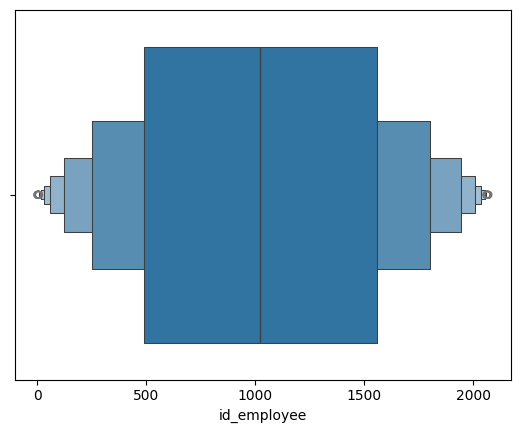

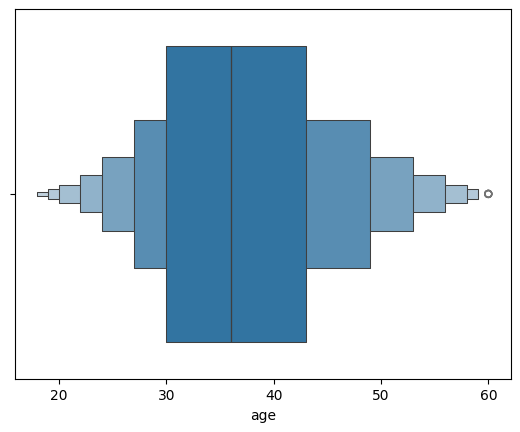

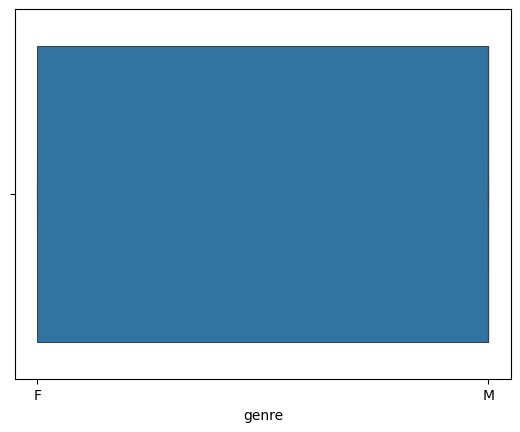

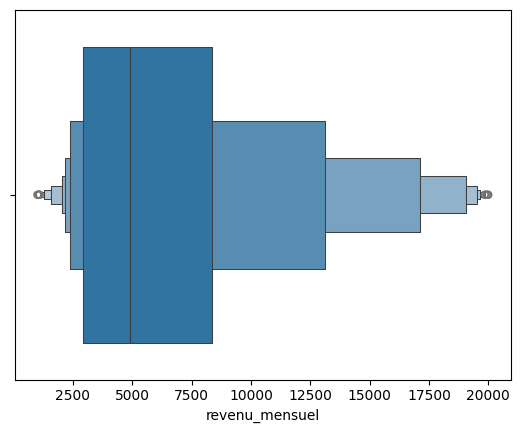

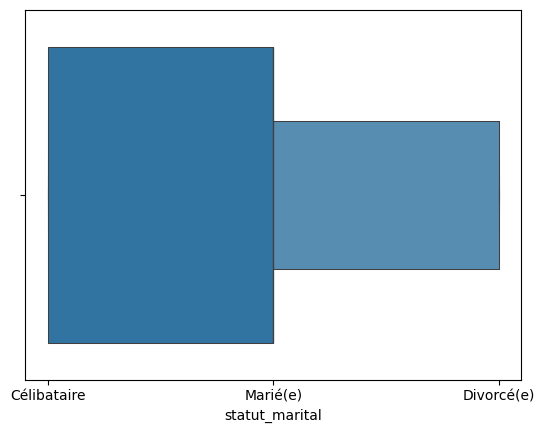

...

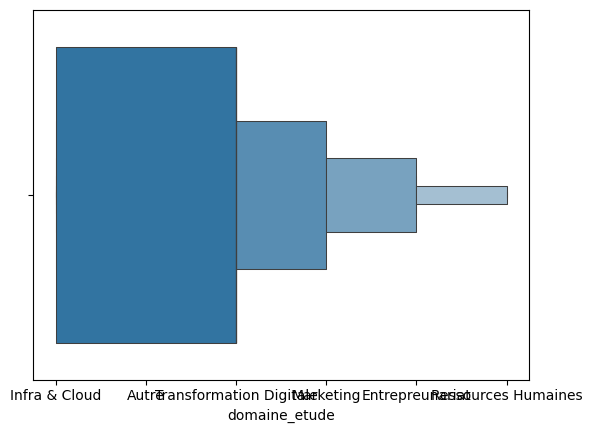

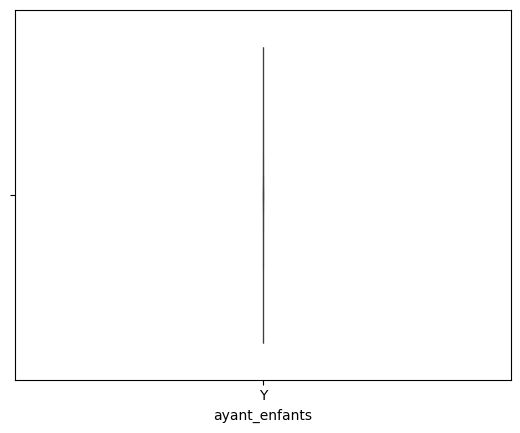

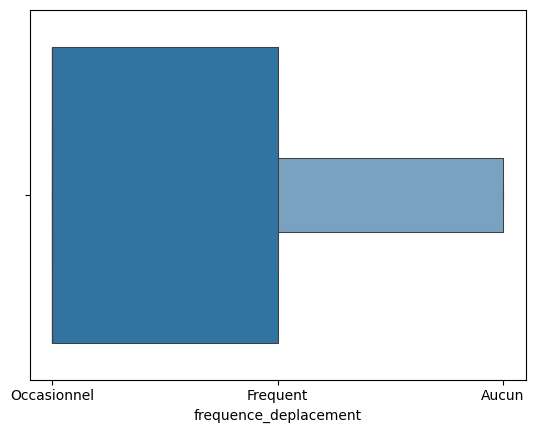

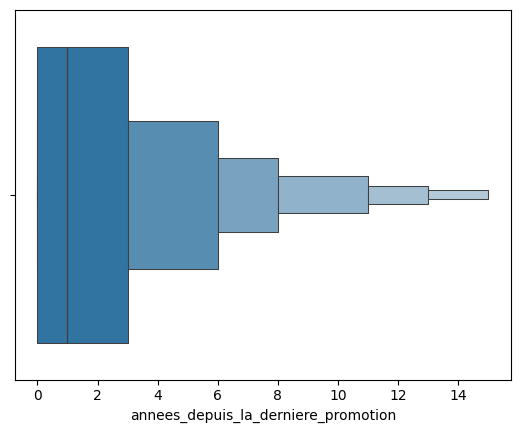

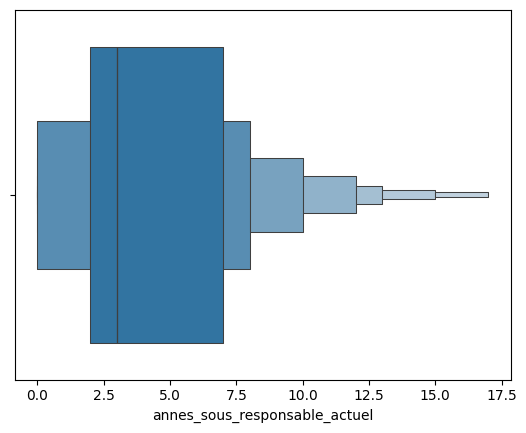

In [ ]:
for column in df_result:    
    sns.boxenplot(df_result, x=column)
    plt.show()


##### Pas d'outlier

---
##### 5.2 Les valeurs Uniques

In [ ]:
for column in df_result:
    print(column,': ',pd.unique(df_result[column].to_numpy().flatten()))

id_employee :  [   1    2    4 ... 2064 2065 2068]
age :  [41 49 37 33 27 32 59 30 38 36 35 29 31 34 28 22 53 24 21 42 44 46 39 43
 50 26 48 55 45 56 23 51 40 54 58 20 25 19 57 52 47 18 60]
genre :  ['F' 'M']
revenu_mensuel :  [5993 5130 2090 ... 9991 5390 4404]
statut_marital :  ['Célibataire' 'Marié(e)' 'Divorcé(e)']
departement :  ['Commercial' 'Consulting' 'Ressources Humaines']
poste :  ['Cadre Commercial' 'Assistant de Direction' 'Consultant' 'Tech Lead'
 'Manager' 'Senior Manager' 'Représentant Commercial'
 'Directeur Technique' 'Ressources Humaines']
nombre_experiences_precedentes :  [8 1 6 9 0 4 5 2 7 3]
nombre_heures_travailless :  [80]
annee_experience_totale :  [ 8 10  7  6 12  1 17  5  3 31 13  0 26 24 22  9 19  2 23 14 15  4 29 28
 21 25 20 11 16 37 38 30 40 18 36 34 32 33 35 27]
annees_dans_l_entreprise :  [ 6 10  0  8  2  7  1  9  5  4 25  3 12 14 22 15 27 21 17 11 13 37 16 20
 40 24 33 19 36 18 29 31 32 34 26 30 23]
annees_dans_le_poste_actuel :  [ 4  7  0  2  5  9  8 

In [19]:
nb_employes = len(pd.unique(df_result['id_employee'].to_numpy().flatten()))
print(nb_employes)

1470


In [14]:
left = (df_result['a_quitte_l_entreprise']=='Oui').sum()
rest = (df_result['a_quitte_l_entreprise']=='Non').sum()
print("left:",left,"|rest:",rest)

left: 237 |rest: 1233


##### Résultat
- Pas de doublon d'id ni de manquant
- Plusieurs constantes
---

#### Résultats de l'exploration:

- **Numérique:** id_employee, age, revenu_mensuel, nombre_experiences_precedentes, annee_experience_totale, annees_dans_l_entreprise, annees_dans_le_poste_actuel, note_evaluation_actuelle, distance_domicile_travail, annees_depuis_la_derniere_promotion, annes_sous_responsable_actuel,  nombre_participation_pee, nb_formations_suivies


- **ordinal:** satisfaction_employee_environnement, satisfaction_employee_nature_travail, satisfaction_employee_equipe, satisfaction_employee_equilibre_pro_perso, niveau_education, frequence_deplacement, note_evaluation_precedente, niveau_hierarchique_poste

- **nominale:** statut_marital, departement, poste, domaine_etude, augementation_salaire_precedente(object à transformer en numérique)
    - binaire: genre, heure_supplementaires, a_quitte_l_entreprise

- **contante:** nombre_heures_travailless, nombre_employee_sous_responsabilite, ayant_enfants


---
---
#### 6. Exploration des relations

##### 6.1 Recherche manuelle

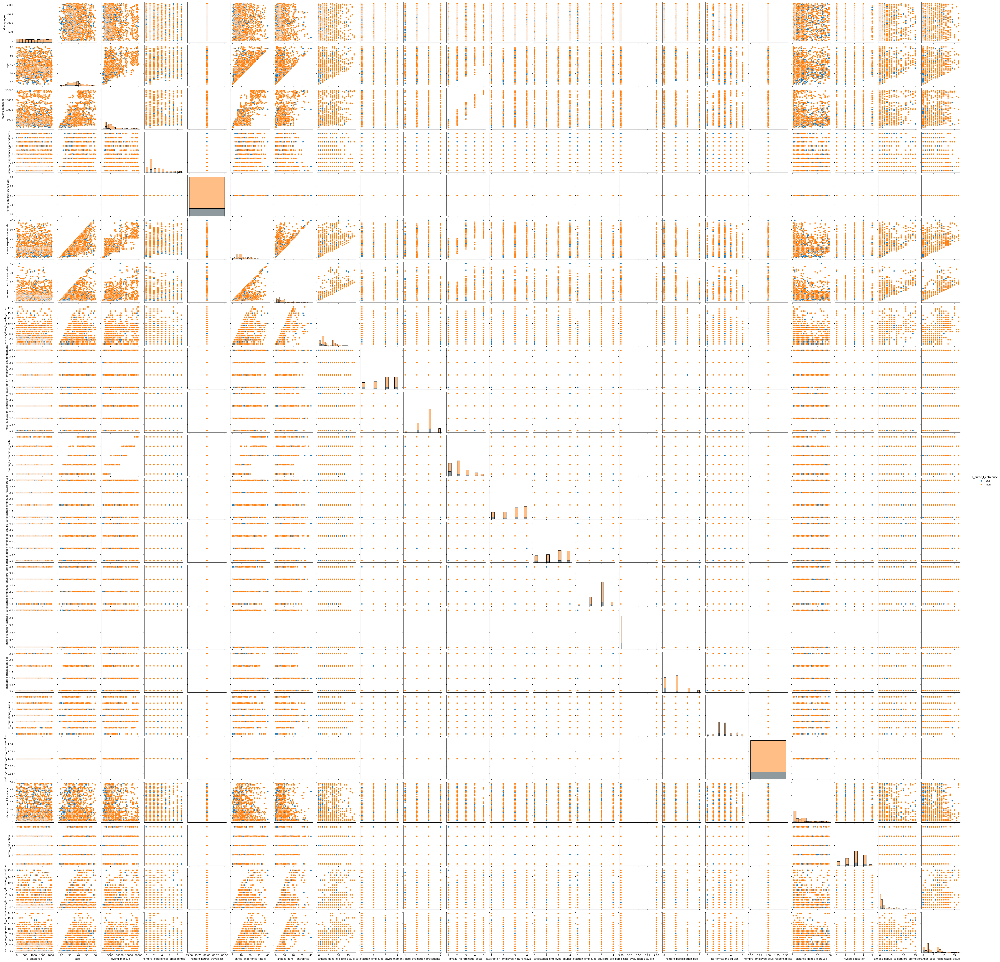

In [ ]:
# Recherche sur toutes les colonnes
sns.pairplot(df_result, hue="a_quitte_l_entreprise", diag_kind="hist")

<Axes: xlabel='distance_domicile_travail', ylabel='Count'>

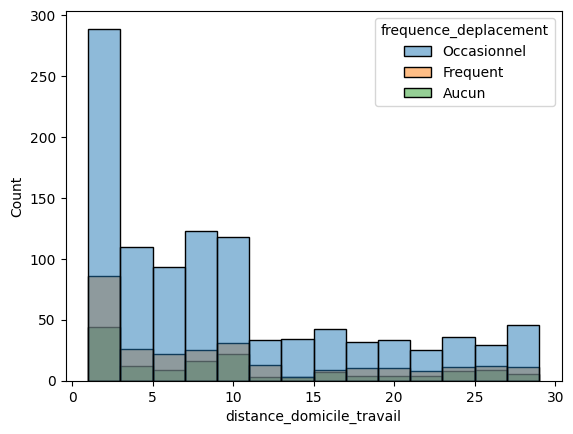

In [ ]:
sns.histplot(df_result,x='distance_domicile_travail', hue="frequence_deplacement") 

<Axes: xlabel='distance_domicile_travail', ylabel='Count'>

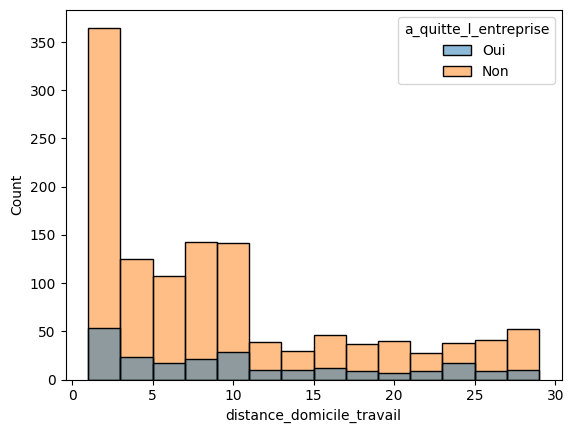

In [ ]:
sns.histplot(df_result,x='distance_domicile_travail', hue="a_quitte_l_entreprise" ) 

<Axes: xlabel='revenu_mensuel', ylabel='Count'>

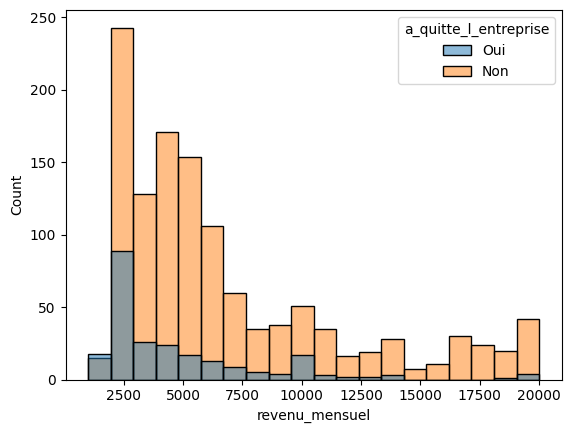

In [ ]:
sns.histplot(df_result,x='revenu_mensuel', hue="a_quitte_l_entreprise" )

<Axes: xlabel='satisfaction_employee_nature_travail', ylabel='Count'>

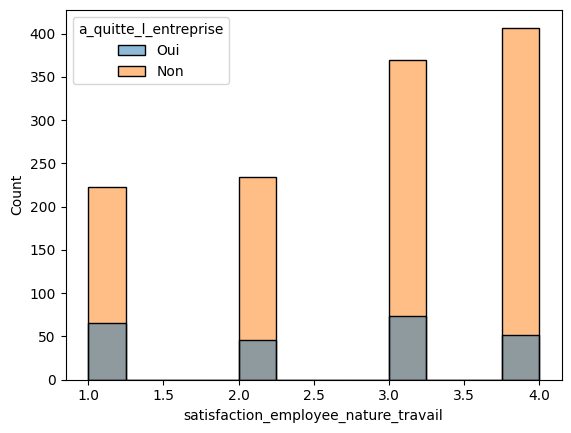

In [117]:
sns.histplot(df_result,x='satisfaction_employee_nature_travail',hue='a_quitte_l_entreprise')

<Axes: xlabel='satisfaction_employee_equipe', ylabel='Count'>

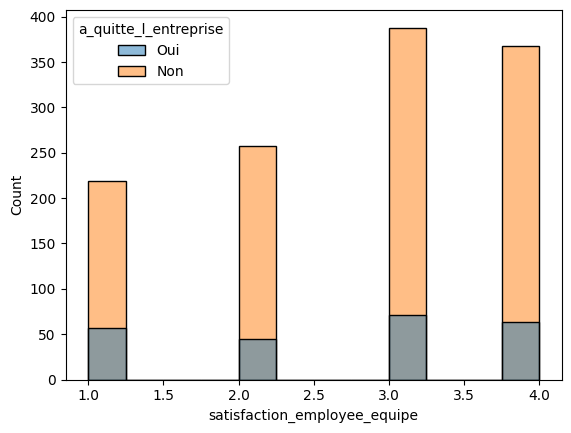

In [118]:
sns.histplot(df_result,x='satisfaction_employee_equipe',hue='a_quitte_l_entreprise')


---
##### 6.2 Recherche groupée par Satisfaction

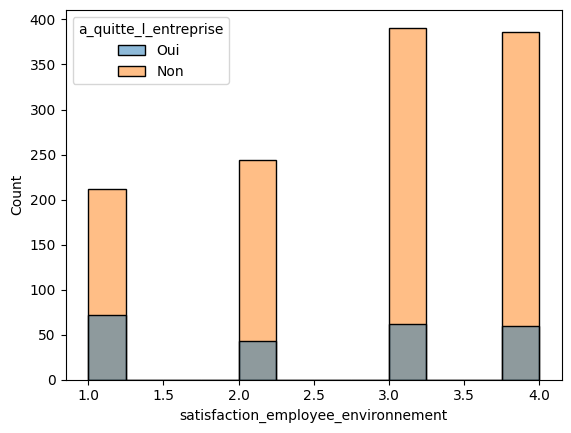

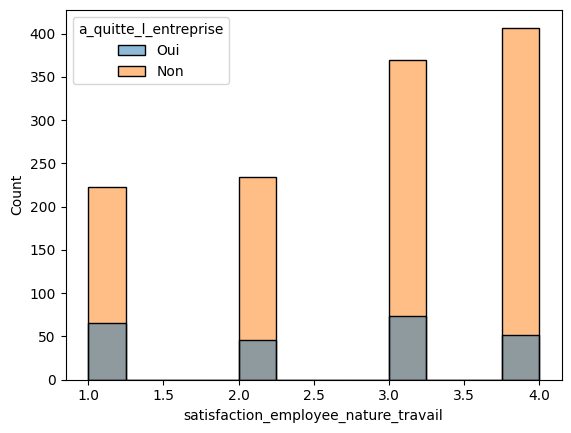

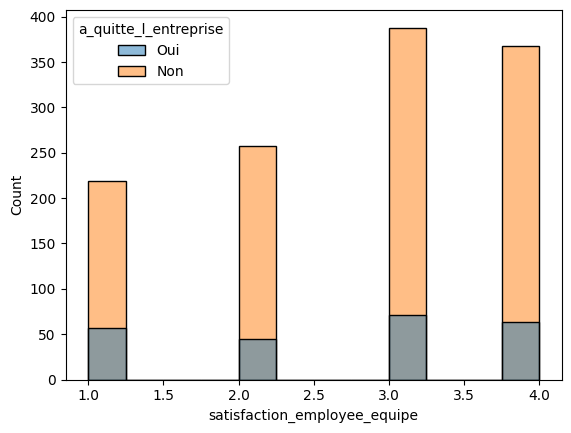

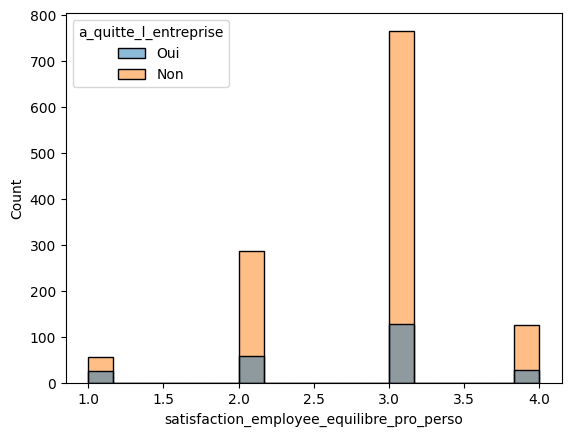

In [21]:
#cols = df_result.loc[:, df_result.columns.str.startswith("satisfaction")]
cols = df_result.filter(regex=r"^satisfaction")

for column in cols:    
    sns.histplot(df_result, x=column, hue='a_quitte_l_entreprise')
    plt.show()

- Pas d'influence visible des questionnaires de satisfaction
- Calcul de la moyenne de satisfaction:

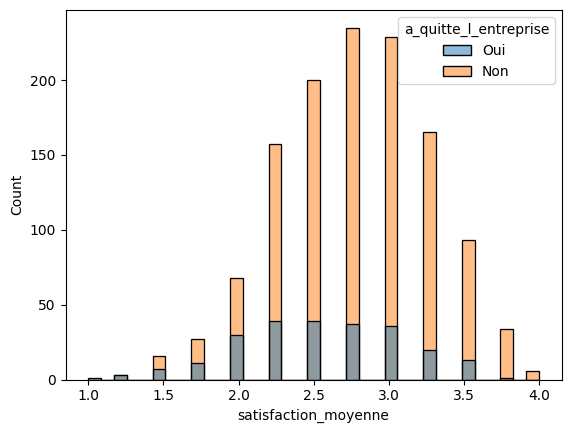

In [ ]:
df_result['satisfaction_moyenne'] = (
    df_result['satisfaction_employee_environnement'] +
    df_result['satisfaction_employee_nature_travail'] +
    df_result['satisfaction_employee_equipe'] +
    df_result['satisfaction_employee_equilibre_pro_perso']
) / 4
 
sns.histplot(df_result, x='satisfaction_moyenne', hue='a_quitte_l_entreprise')
plt.show()

---
##### 6.3 Recherche sur les données de temps

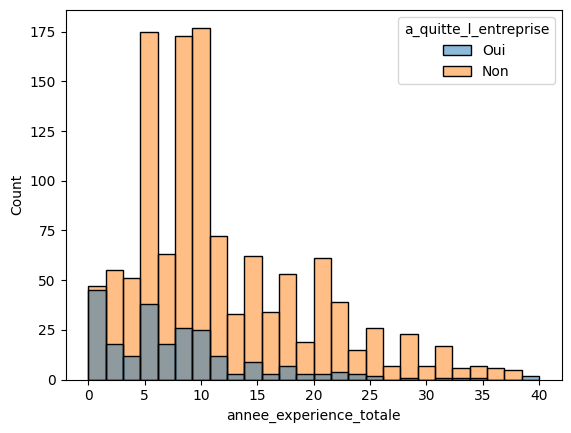

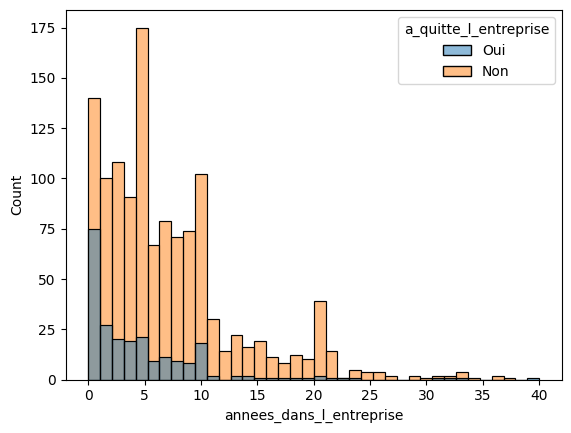

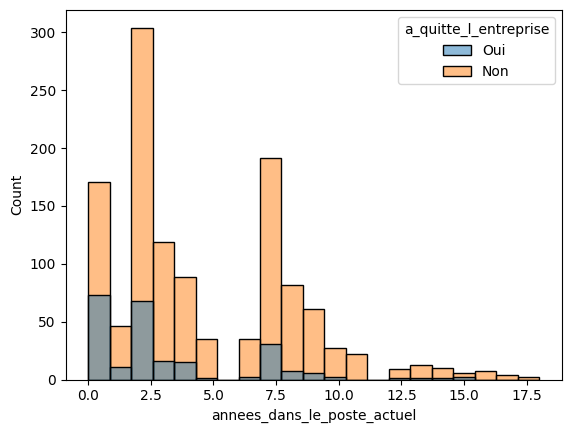

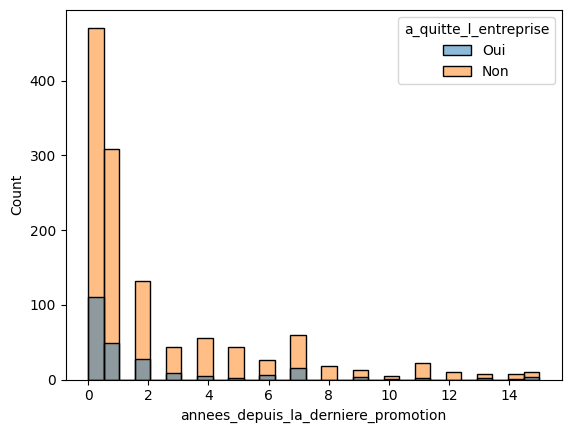

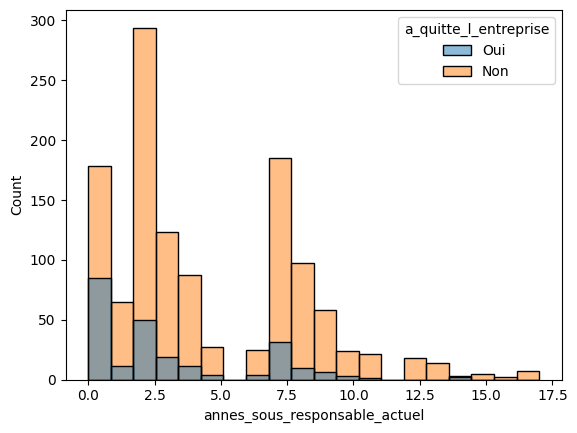

In [9]:
#Toutes les colonnes commencant par annees
cols = df_result.filter(regex=r"^anne")

for column in cols:    
    sns.histplot(df_result, x=column, hue='a_quitte_l_entreprise')
    plt.show()

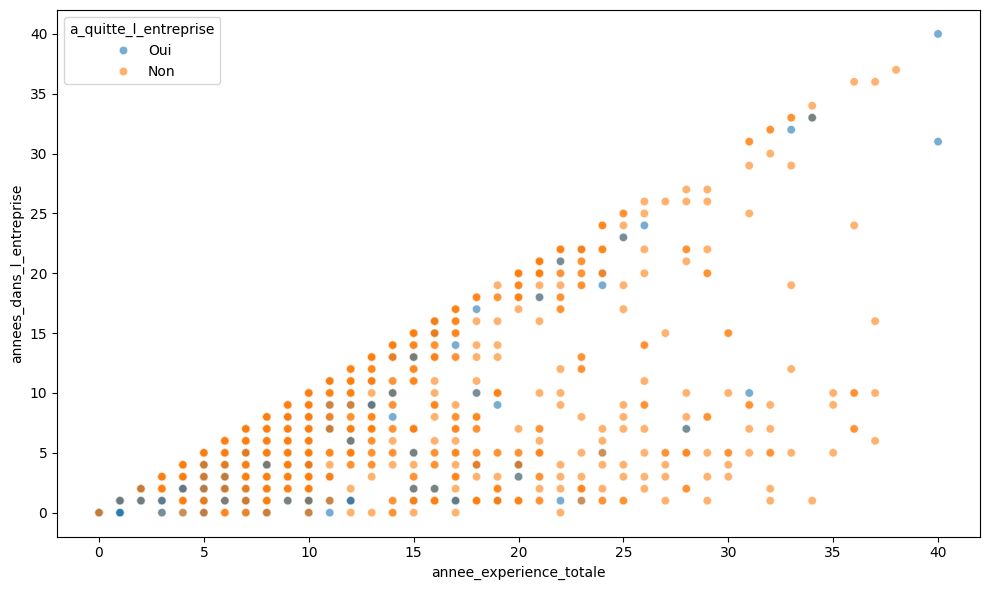

In [22]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='annee_experience_totale', y='annees_dans_l_entreprise', data=df_result, alpha=0.6,hue='a_quitte_l_entreprise') #color='b')

# Afficher le graphique
plt.tight_layout()
plt.show()

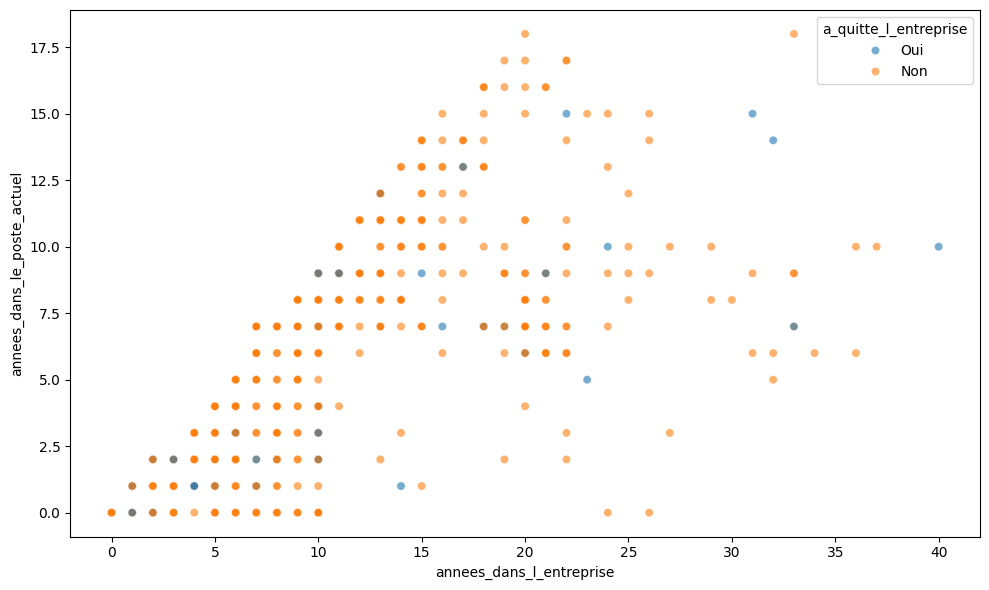

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='annees_dans_l_entreprise', y='annees_dans_le_poste_actuel', data=df_result, alpha=0.6, hue='a_quitte_l_entreprise') #color='b')

# Afficher le graphique
plt.tight_layout()
plt.show()

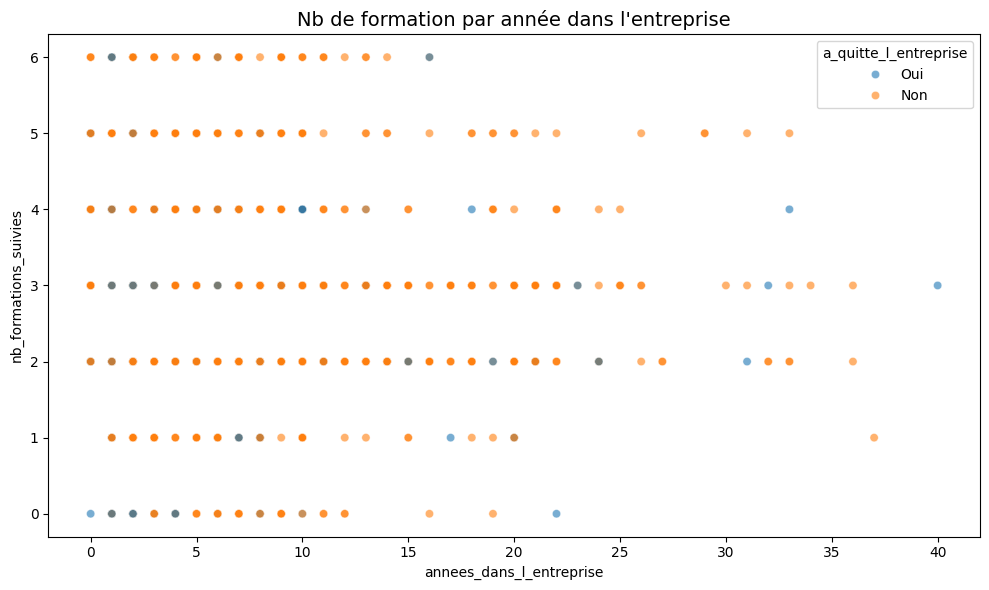

In [ ]:
# Visualisation du nb de formation par année dans l'entreprise
plt.figure(figsize=(10, 6))
sns.scatterplot(x='annees_dans_l_entreprise', y='nb_formations_suivies', data=df_result, alpha=0.6,hue='a_quitte_l_entreprise') #color='b')

# Afficher le graphique
plt.title('Nb de formation par année dans l\'entreprise', fontsize=14)
plt.tight_layout()
plt.show()

---
##### 6.4 Nombre, Note, Niveau

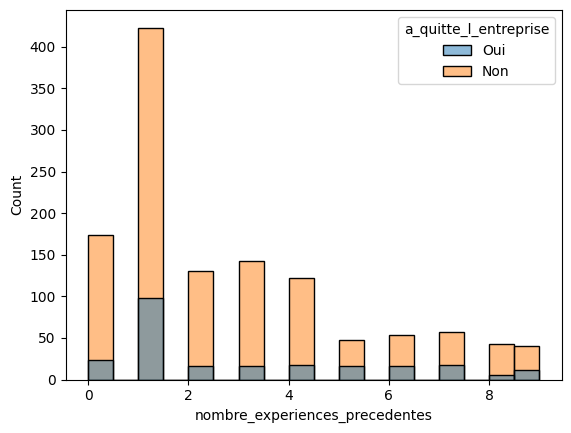

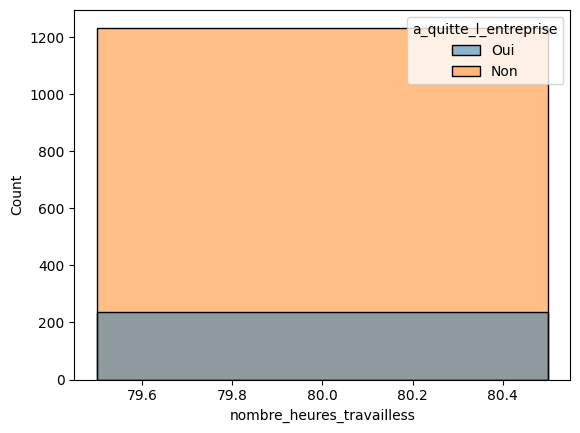

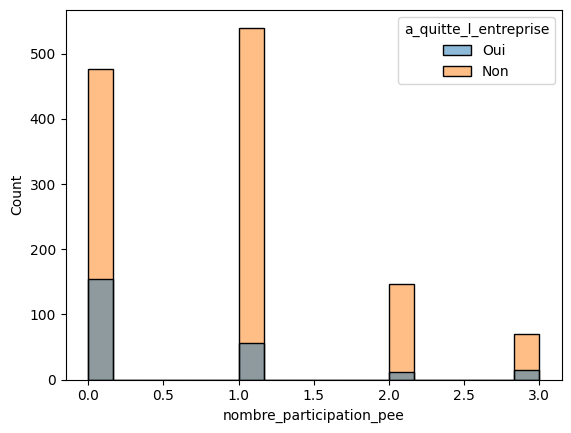

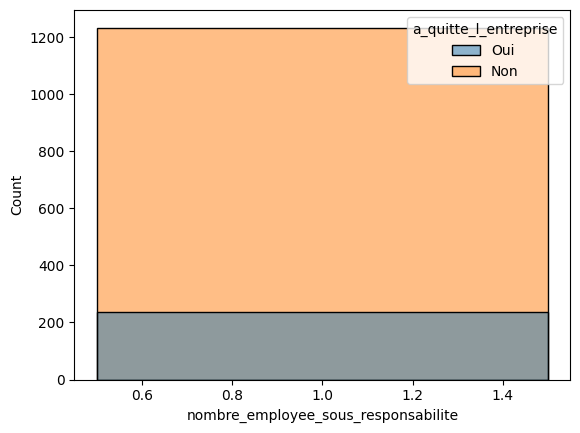

In [ ]:
#Toutes les colonnes commencant par nombre

for column in cols:    
    sns.histplot(df_result, x=column, hue='a_quitte_l_entreprise')
    plt.show()

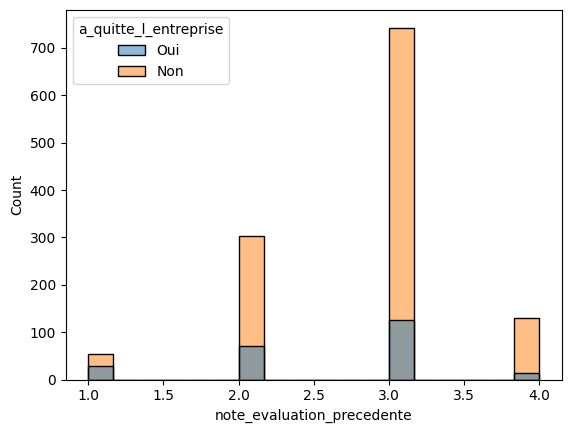

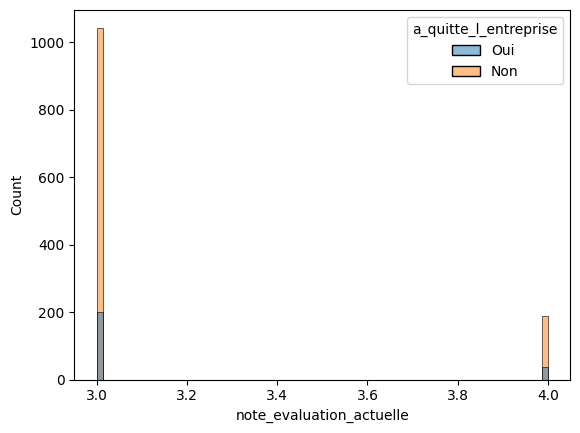

In [ ]:
#Toutes les colonnes commencant par note
cols = df_result.filter(regex=r"^note")

for column in cols:    
    sns.histplot(df_result, x=column, hue='a_quitte_l_entreprise')
    plt.show()

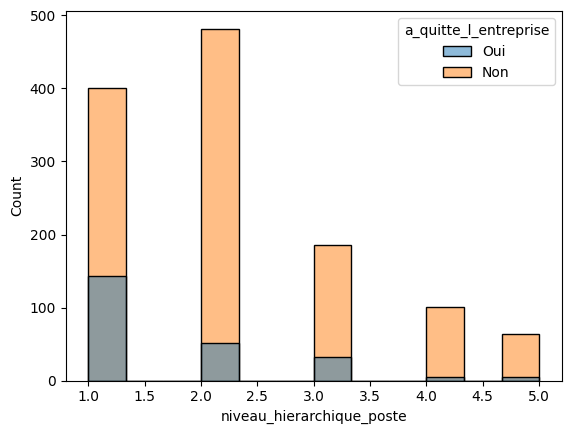

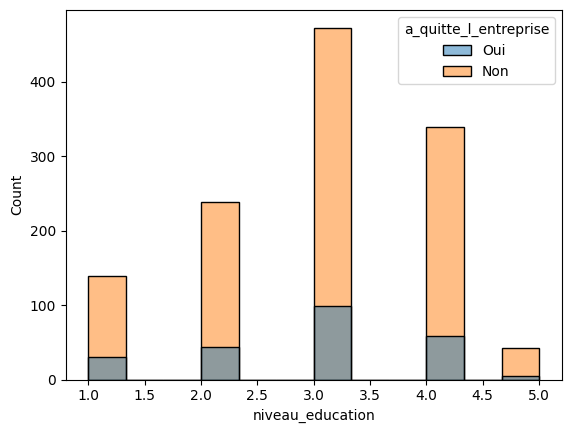

In [ ]:
#Toutes les colonnes commencant par niveau
cols = df_result.filter(regex=r"^niveau")

for column in cols:    
    sns.histplot(df_result, x=column, hue='a_quitte_l_entreprise')
    plt.show()

---
##### 6.5 Autres

<Axes: xlabel='statut_marital', ylabel='Count'>

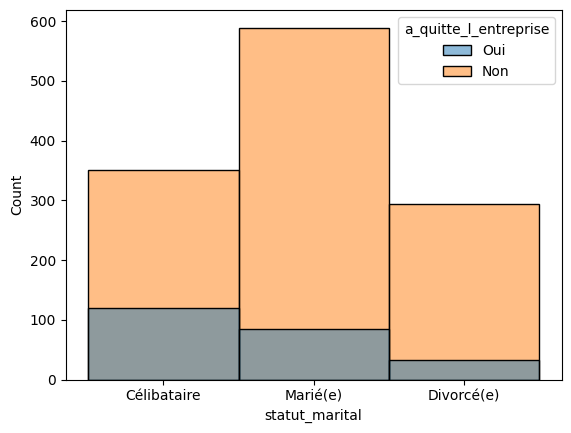

In [144]:
sns.histplot(df_result, x='statut_marital', hue='a_quitte_l_entreprise')

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 [Text(0, 0, '11 %'),
  Text(1, 0, '23 %'),
  Text(2, 0, '15 %'),
  Text(3, 0, '12 %'),
  Text(4, 0, '13 %'),
  Text(5, 0, '20 %'),
  Text(6, 0, '22 %'),
  Text(7, 0, '21 %'),
  Text(8, 0, '17 %'),
  Text(9, 0, '14 %'),
  Text(10, 0, '16 %'),
  Text(11, 0, '18 %'),
  Text(12, 0, '19 %'),
  Text(13, 0, '24 %'),
  Text(14, 0, '25 %')])

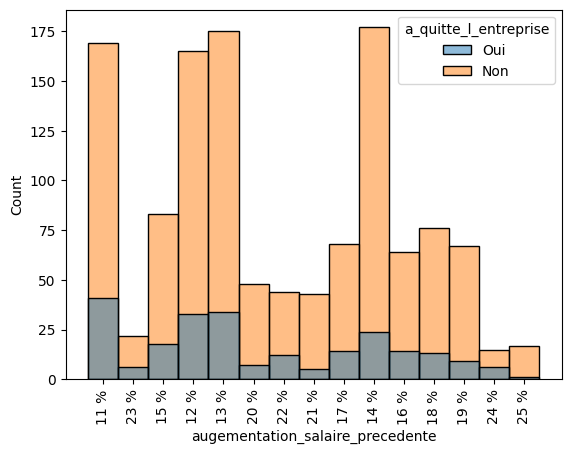

In [8]:
sns.histplot(df_result, x='augementation_salaire_precedente', hue='a_quitte_l_entreprise')# à voir avec année entreprise/poste actuel
plt.xticks( rotation='vertical')

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 [Text(0, 0, '11 %'),
  Text(1, 0, '23 %'),
  Text(2, 0, '15 %'),
  Text(3, 0, '12 %'),
  Text(4, 0, '13 %'),
  Text(5, 0, '20 %'),
  Text(6, 0, '22 %'),
  Text(7, 0, '21 %'),
  Text(8, 0, '17 %'),
  Text(9, 0, '14 %'),
  Text(10, 0, '16 %'),
  Text(11, 0, '18 %'),
  Text(12, 0, '19 %'),
  Text(13, 0, '24 %'),
  Text(14, 0, '25 %')])

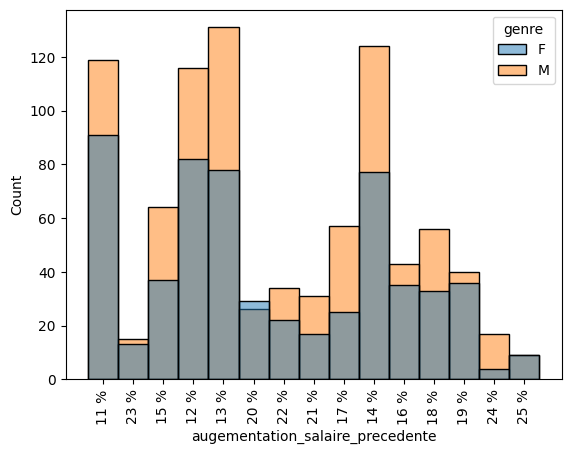

In [ ]:
sns.histplot(df_result, x='augementation_salaire_precedente', hue='genre')
plt.xticks( rotation='vertical')

([0, 1], [Text(0, 0, 'F'), Text(1, 0, 'M')])

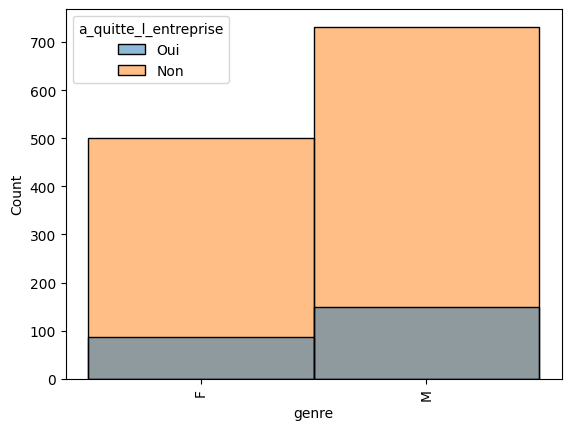

In [12]:
sns.histplot(df_result, x='genre', hue='a_quitte_l_entreprise')
plt.xticks( rotation='vertical')

<Axes: xlabel='departement', ylabel='Count'>

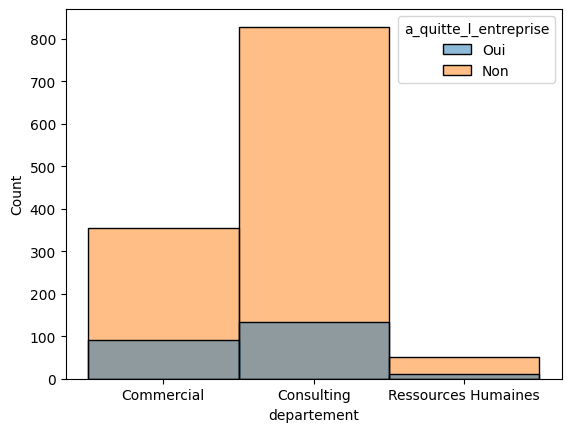

In [146]:
sns.histplot(df_result, x='departement', hue='a_quitte_l_entreprise')

([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'Infra & Cloud'),
  Text(1, 0, 'Autre'),
  Text(2, 0, 'Transformation Digitale'),
  Text(3, 0, 'Marketing'),
  Text(4, 0, 'Entrepreunariat'),
  Text(5, 0, 'Ressources Humaines')])

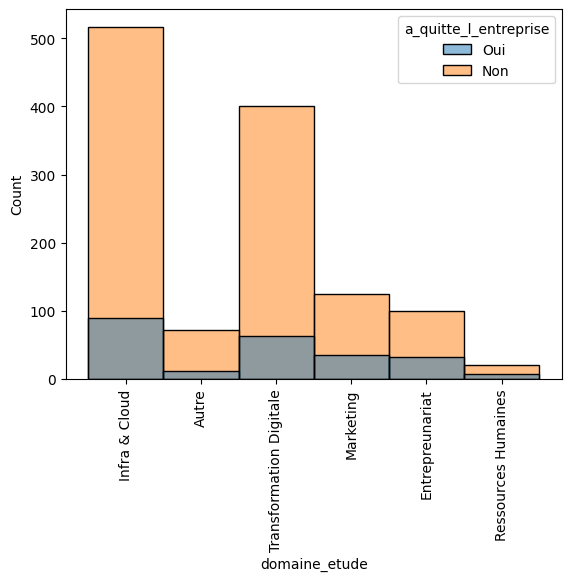

In [20]:
sns.histplot(df_result, x='domaine_etude', hue='a_quitte_l_entreprise')
plt.xticks( rotation='vertical')

([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, 'Cadre Commercial'),
  Text(1, 0, 'Assistant de Direction'),
  Text(2, 0, 'Consultant'),
  Text(3, 0, 'Tech Lead'),
  Text(4, 0, 'Manager'),
  Text(5, 0, 'Senior Manager'),
  Text(6, 0, 'Représentant Commercial'),
  Text(7, 0, 'Directeur Technique'),
  Text(8, 0, 'Ressources Humaines')])

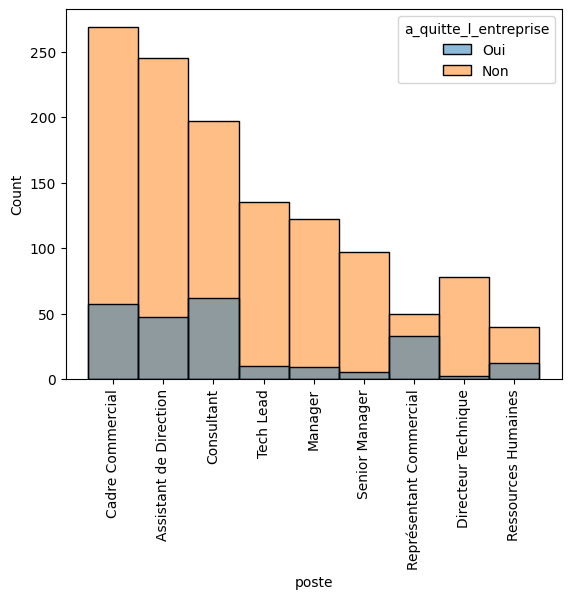

In [149]:
sns.histplot(df_result, x='poste', hue='a_quitte_l_entreprise')
plt.xticks( rotation='vertical')

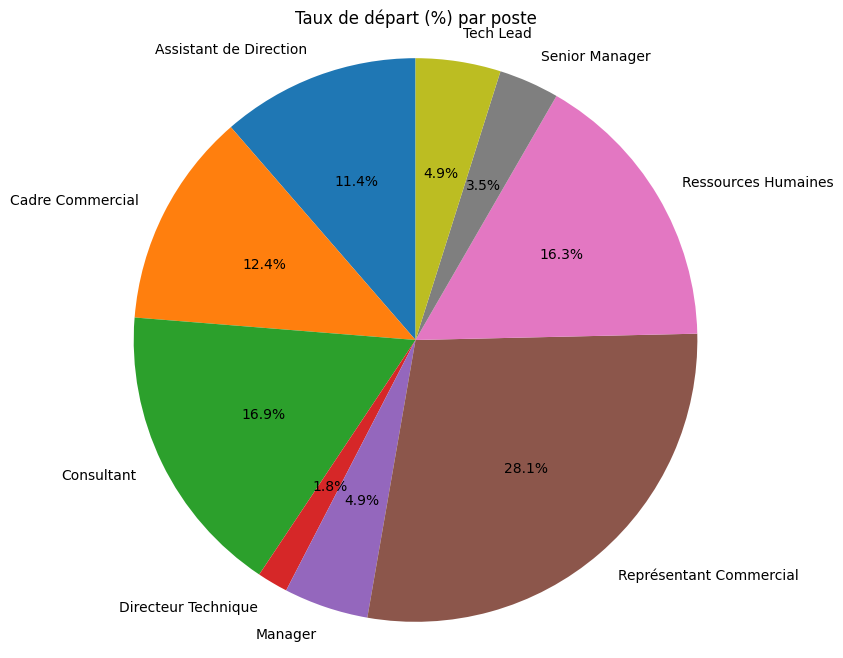

In [ ]:
# Total d'employés par poste
total_par_poste = df_result.groupby("poste").size()

# Nombre de départs par poste
depart_par_poste = df_result[df_result["a_quitte_l_entreprise"] == "Oui"].groupby("poste").size()

# Pourcentage de départ
taux_depart = (depart_par_poste / total_par_poste * 100)#si valeur nulle .fillna(0)

plt.figure(figsize=(8, 8))
plt.pie(
    taux_depart,
    labels=taux_depart.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Taux de départ (%) par poste")
plt.axis("equal")
plt.show()

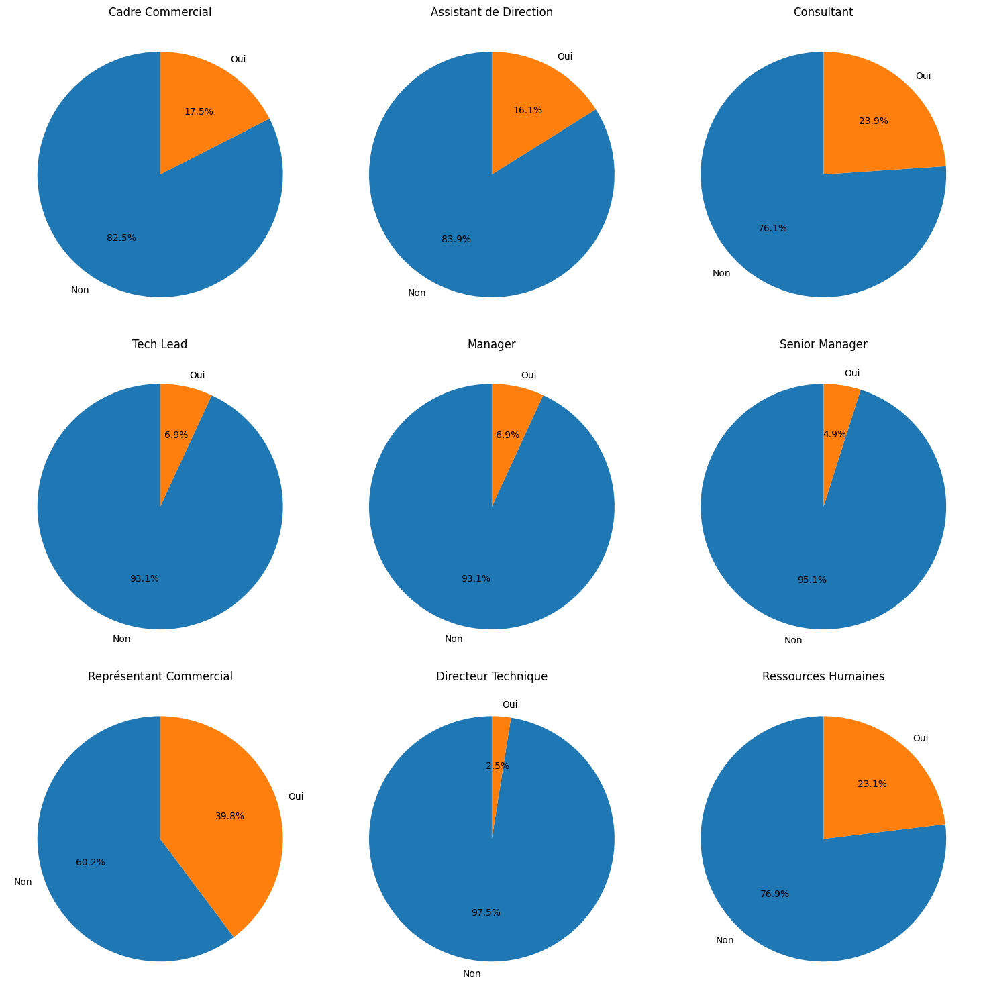

In [28]:
postes = df_result["poste"].unique()
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 15))
axes = axes.flatten()

for ax, poste in zip(axes, postes):
    data_poste = df_result[df_result["poste"] == poste]["a_quitte_l_entreprise"].value_counts(normalize=True) * 100
    ax.pie(data_poste, labels=data_poste.index, autopct='%1.1f%%', startangle=90)
    ax.set_title(poste)

plt.tight_layout()
plt.show()

<Axes: xlabel='heure_supplementaires', ylabel='Count'>

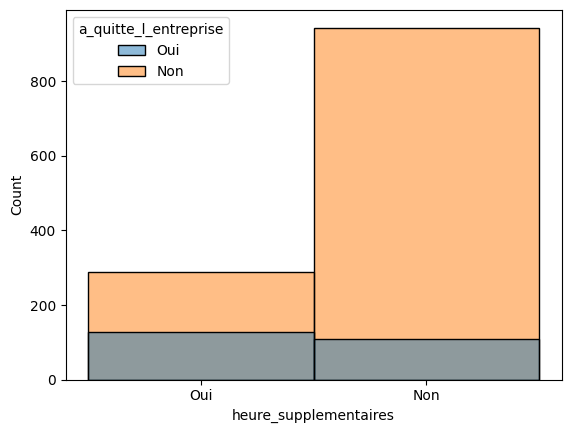

In [150]:
sns.histplot(df_result, x='heure_supplementaires', hue='a_quitte_l_entreprise')

---
##### 6.6 Sur le Salaire

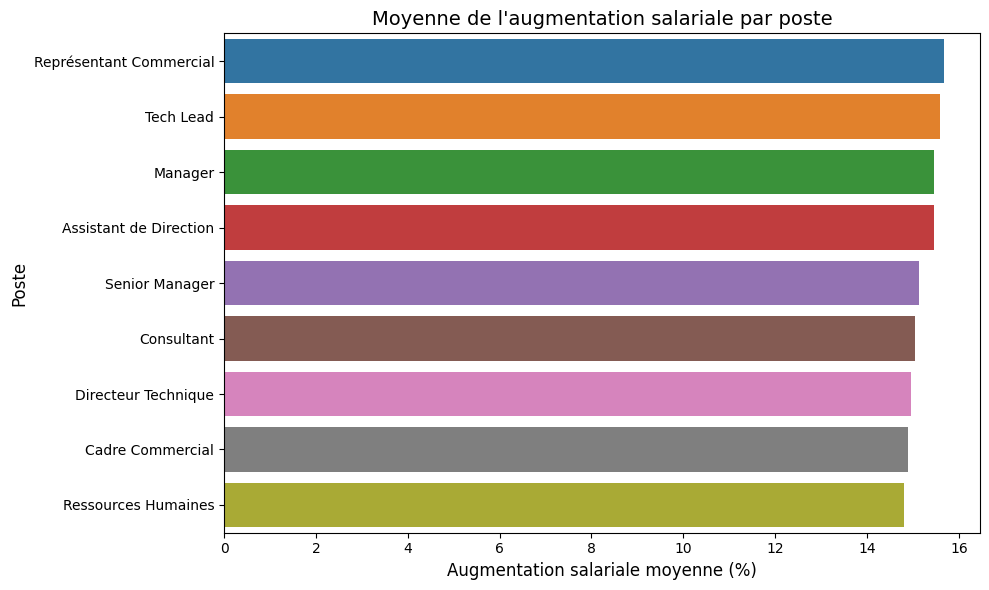

In [ ]:
# Convertir les pourcentages d'augmentation salariale en valeurs numériques
df_result['augmentation_salaire_percent'] = df_result['augementation_salaire_precedente'].str.rstrip(' %').astype(float)

# Calculer la moyenne de l'augmentation salariale par poste
avg_augmentation = df_result.groupby('poste')['augmentation_salaire_percent'].mean().reset_index()
avg_augmentation = avg_augmentation.sort_values('augmentation_salaire_percent', ascending=False)

# Tracer le graphique
plt.figure(figsize=(10, 6))
sns.barplot(data=avg_augmentation, x='augmentation_salaire_percent', y='poste', hue='poste',legend=False)

# Ajouter des titres et des labels
plt.title('Moyenne de l\'augmentation salariale par poste', fontsize=14)
plt.xlabel('Augmentation salariale moyenne (%)', fontsize=12)
plt.ylabel('Poste', fontsize=12)

# Afficher le graphique
plt.tight_layout()
plt.show()

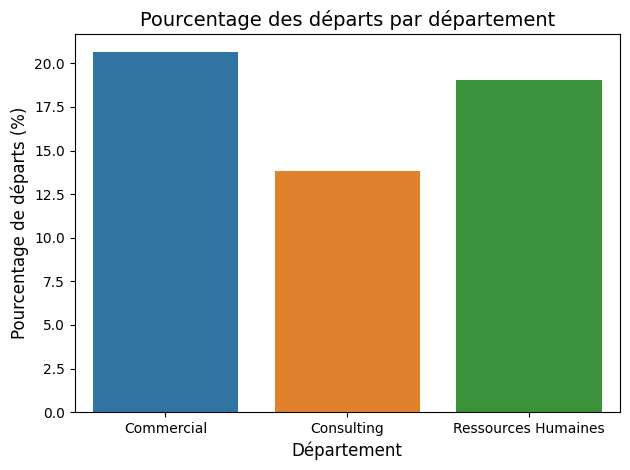

In [ ]:
# Calculer le pourcentage de départs par département
departements_quittes = df_result[df_result['a_quitte_l_entreprise'] == 'Oui'] \
    .groupby('departement')['a_quitte_l_entreprise'] \
    .count() \
    .reset_index(name='nombre_quittes')

# Calculer le nombre total d'employés par département
total_par_departement = df_result.groupby('departement')['a_quitte_l_entreprise'] \
    .count() \
    .reset_index(name='nombre_total')

# Fusionner les deux DataFrames pour obtenir les départs en pourcentage
departements_quittes = pd.merge(departements_quittes, total_par_departement, on='departement')
departements_quittes['pourcentage_quittes'] = (departements_quittes['nombre_quittes'] / departements_quittes['nombre_total']) * 100

# Tracer le graphique
sns.barplot(data=departements_quittes, x='departement', y='pourcentage_quittes', hue='departement', legend=False)

# Ajouter des titres et labels
plt.title('Pourcentage des départs par département', fontsize=14)
plt.xlabel('Département', fontsize=12)
plt.ylabel('Pourcentage de départs (%)', fontsize=12)

# Afficher le graphique
plt.tight_layout()
plt.show()

##### 6.7 Salaire/éxpérience

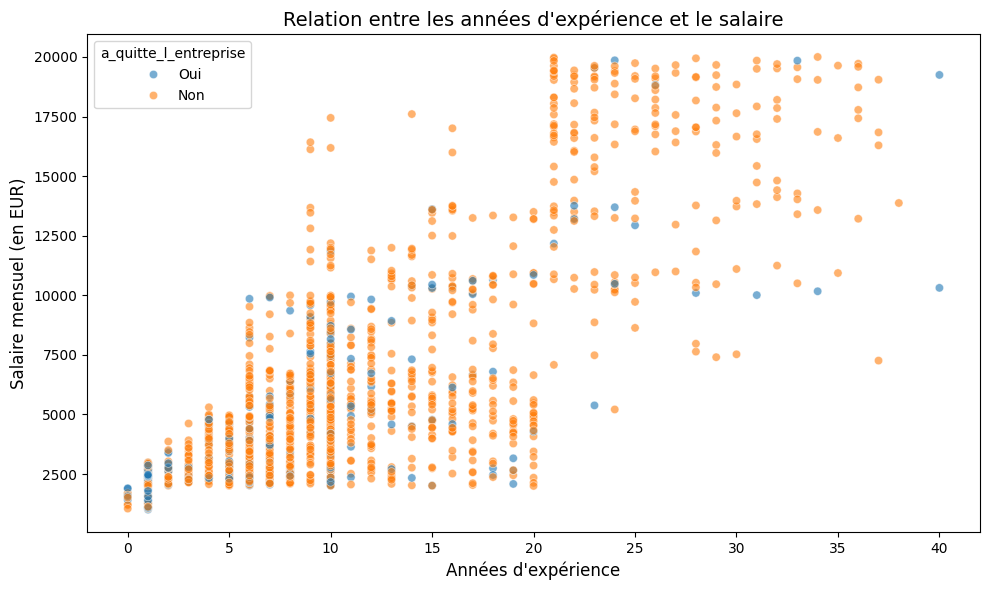

In [ ]:
# Relation entre les années d'expérience et le salaire
plt.figure(figsize=(10, 6))
sns.scatterplot(x='annee_experience_totale', y='revenu_mensuel', data=df_result, alpha=0.6,hue='a_quitte_l_entreprise') #color='b')

# Ajouter des titres et des labels
plt.title('Relation entre les années d\'expérience et le salaire', fontsize=14)
plt.xlabel('Années d\'expérience', fontsize=12)
plt.ylabel('Salaire mensuel (en EUR)', fontsize=12)

# Afficher le graphique
plt.tight_layout()
plt.show()

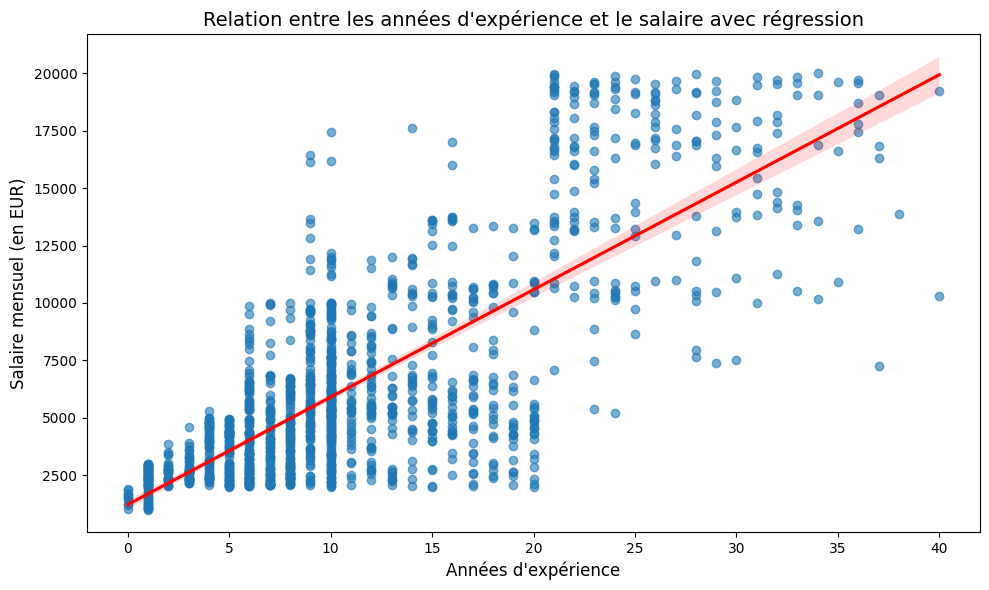

In [82]:
# Scatter plot avec droite de régression
plt.figure(figsize=(10, 6))

sns.regplot(x='annee_experience_totale', y='revenu_mensuel', data=df_result, scatter_kws={'alpha':0.6}, line_kws={'color':'red'})

# Ajouter des titres et des labels
plt.title('Relation entre les années d\'expérience et le salaire avec régression', fontsize=14)
plt.xlabel('Années d\'expérience', fontsize=12)
plt.ylabel('Salaire mensuel (en EUR)', fontsize=12)

# Afficher le graphique
plt.tight_layout()
plt.show()

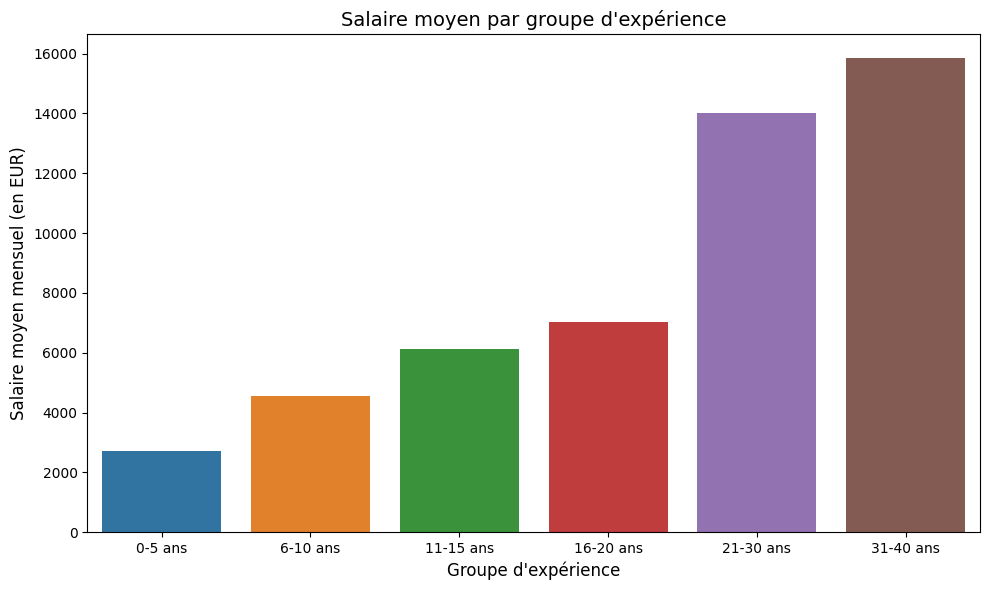

In [ ]:
# Créer des catégories d'expérience
bins = [0, 5, 10, 15, 20, 30, 40] 
labels = ['0-5 ans', '6-10 ans', '11-15 ans', '16-20 ans', '21-30 ans', '31-40 ans']
df_result['groupe_experience'] = pd.cut(df_result['annee_experience_totale'], bins=bins, labels=labels, right=False)

# Calcule du salaire moyen pour chaque groupe d'expérience
salaire_moyen_par_experience = df_result.groupby('groupe_experience', observed=True)['revenu_mensuel'].mean().reset_index()
''' 
FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. 
Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
https://github.com/pandas-dev/pandas/issues/54054
df.groupby(categorical_index, observed=True)
'''

# Tracer le graphique
plt.figure(figsize=(10, 6))
sns.barplot(x='groupe_experience', y='revenu_mensuel', data=salaire_moyen_par_experience,hue='groupe_experience', legend=False)

# titres et labels
plt.title('Salaire moyen par groupe d\'expérience', fontsize=14)
plt.xlabel('Groupe d\'expérience', fontsize=12)
plt.ylabel('Salaire moyen mensuel (en EUR)', fontsize=12)

# Afficher le graphique
plt.tight_layout()
plt.show()

In [32]:
correlation = df_result[['annee_experience_totale', 'revenu_mensuel']].corr().iloc[0, 1]
print(f"Le coefficient de corrélation entre les années d'expérience et le salaire est : {correlation:.2f}")

Le coefficient de corrélation entre les années d'expérience et le salaire est : 0.77


---
---
#### 7. Création de Features 

##### 7.1 Satisfaction

2.730952380952381


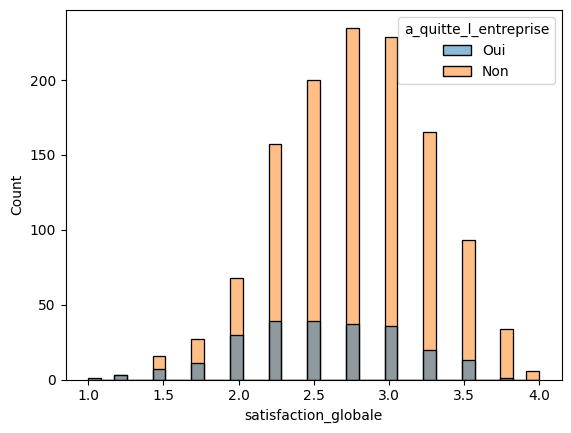

In [8]:
satisfaction_cols = [
    "satisfaction_employee_environnement",
    "satisfaction_employee_nature_travail",
    "satisfaction_employee_equipe",
    "satisfaction_employee_equilibre_pro_perso"
]

df_result["satisfaction_globale"] = df_result[satisfaction_cols].mean(axis=1)
print(df_result["satisfaction_globale"].mean())
sns.histplot(df_result, x='satisfaction_globale', hue='a_quitte_l_entreprise')
plt.show()

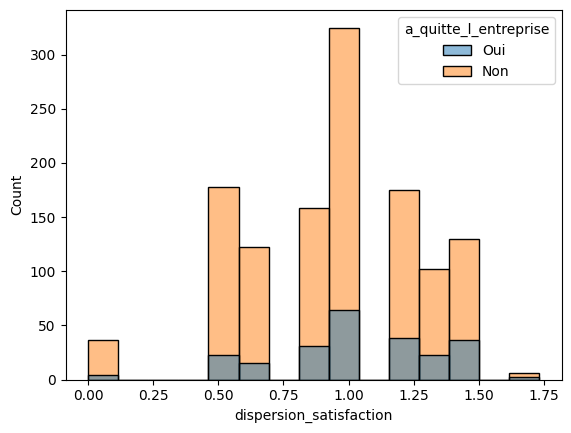

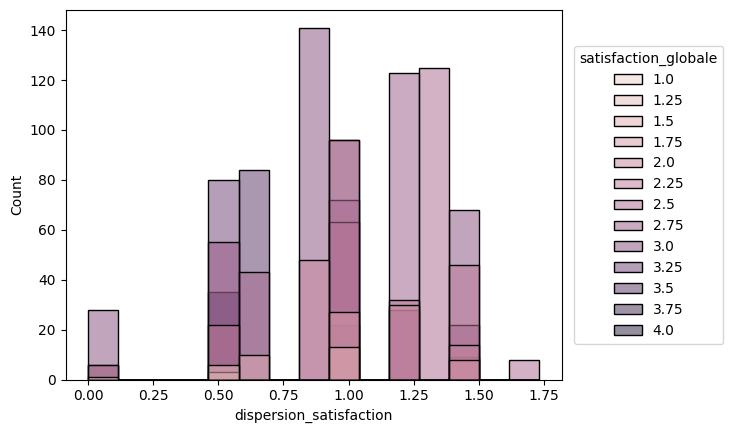

In [ ]:
df_result["dispersion_satisfaction"] = df_result[satisfaction_cols].std(axis=1)
plt.figure(1)
ax_1 = sns.histplot(df_result, x='dispersion_satisfaction', hue='a_quitte_l_entreprise')
plt.figure(2)
ax_2 = sns.histplot(df_result, x='dispersion_satisfaction', hue='satisfaction_globale')
sns.move_legend(ax_2, "center right", bbox_to_anchor=(1.34, 0.5))
plt.show()

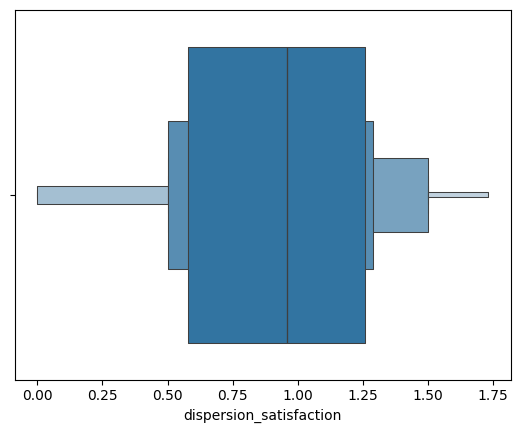

In [ ]:
sns.boxenplot(df_result, x='dispersion_satisfaction')
plt.show()

---
##### 7.2 Années

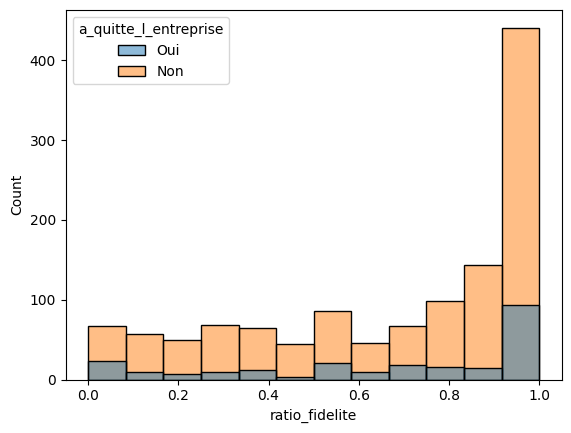

In [ ]:
# Ratio de fidélité
df_result["ratio_fidelite"] = df_result["annees_dans_l_entreprise"] / df_result["annee_experience_totale"].replace(0, 1)

sns.histplot(df_result, x='ratio_fidelite', hue='a_quitte_l_entreprise')
plt.show()

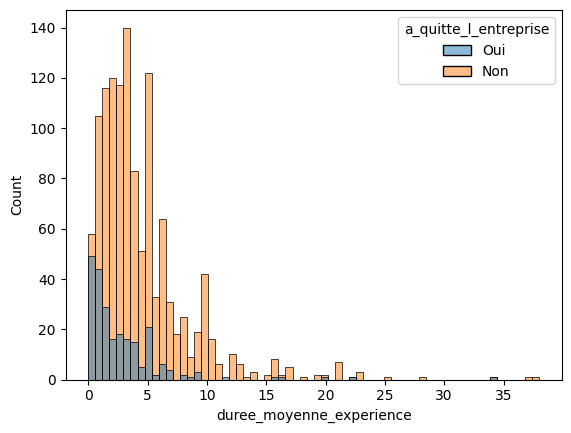

In [ ]:
# Durée moyenne d'une expérience
df_result["duree_moyenne_experience"] = df_result["annee_experience_totale"] / (df_result["nombre_experiences_precedentes"] + 1)

sns.histplot(df_result, x='duree_moyenne_experience', hue='a_quitte_l_entreprise')
plt.show()

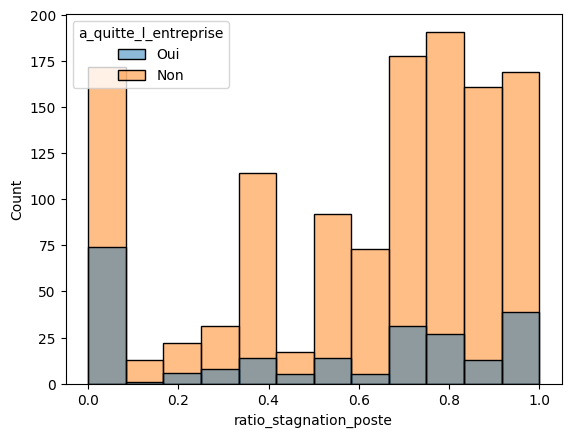

In [14]:
# Ratio de stagnation au poste
df_result["ratio_stagnation_poste"] = (     
	df_result["annees_dans_le_poste_actuel"] /   
	df_result["annees_dans_l_entreprise"].replace(0, 1) 
)

df_result["ratio_stagnation_poste"]

sns.histplot(df_result, x='ratio_stagnation_poste', hue='a_quitte_l_entreprise')
plt.show()


---
##### 7.3 Salaire

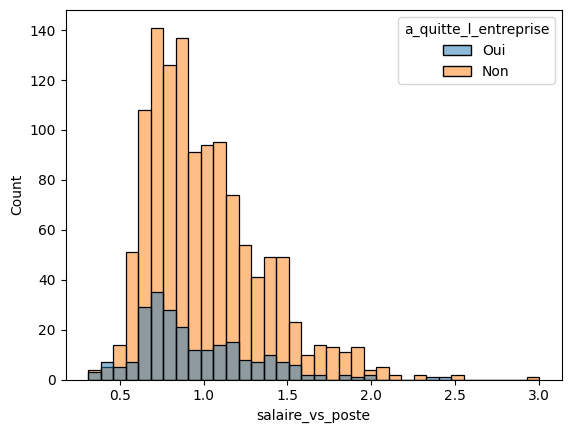

In [13]:
# Ratio Salaire/Salaire moyen du Poste

salaire_moyen_poste = df_result.groupby("poste")["revenu_mensuel"].transform("mean") 
df_result["salaire_vs_poste"] = df_result["revenu_mensuel"] / salaire_moyen_poste

sns.histplot(df_result, x='salaire_vs_poste', hue='a_quitte_l_entreprise')
plt.show()

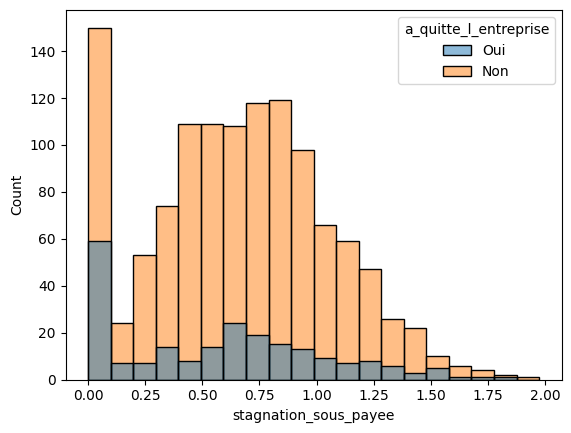

In [51]:
df_result["stagnation_sous_payee"] = (
	df_result["ratio_stagnation_poste"] *     
	(1 / df_result["salaire_vs_poste"]) 
)

sns.histplot(df_result, x='stagnation_sous_payee', hue='a_quitte_l_entreprise')
plt.show()

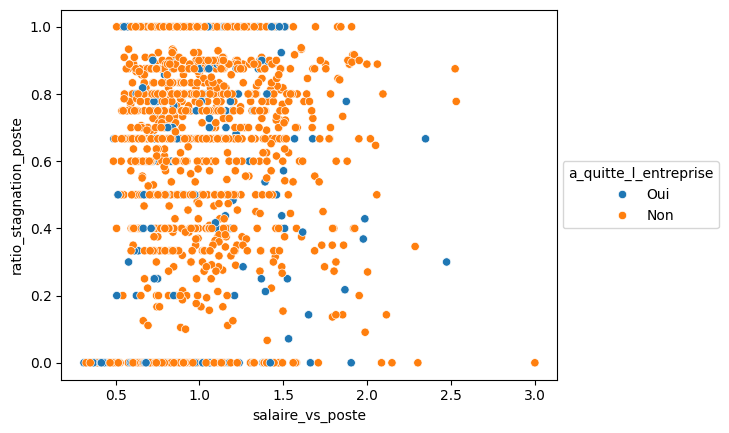

In [19]:
ax = sns.scatterplot(df_result,x='salaire_vs_poste', y='ratio_stagnation_poste', hue='a_quitte_l_entreprise')
sns.move_legend(ax, "center right", bbox_to_anchor=(1.34, 0.5))
plt.show()

---

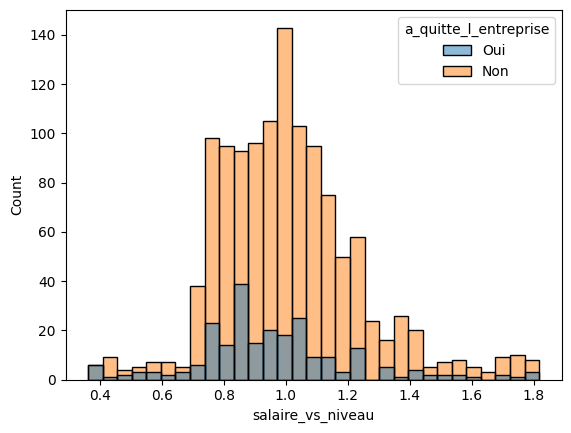

In [44]:
salaire_moyen_niveau = df_result.groupby("niveau_hierarchique_poste")["revenu_mensuel"].transform("mean") 
df_result["salaire_vs_niveau"] = df_result["revenu_mensuel"] / salaire_moyen_niveau

sns.histplot(df_result, x='salaire_vs_niveau', hue='a_quitte_l_entreprise')
plt.show()

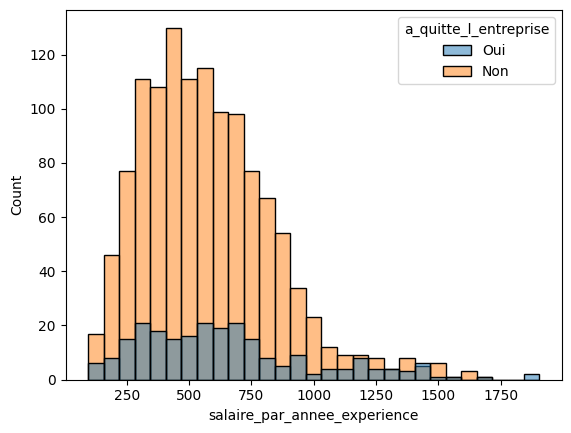

In [47]:
df_result["salaire_par_annee_experience"] = df_result["revenu_mensuel"] / (df_result["annee_experience_totale"] + 1)

sns.histplot(df_result, x='salaire_par_annee_experience', hue='a_quitte_l_entreprise')
plt.show()

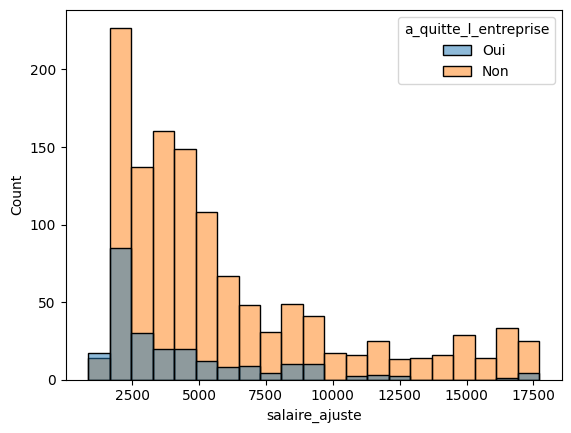

In [48]:
df_result["augmentation_salaire_pct"] = (     
	df_result["augementation_salaire_precedente"]     
	.str.replace("%", "")     
	.astype(int) 
)  
df_result["salaire_ajuste"] = df_result["revenu_mensuel"] / (1 + df_result["augmentation_salaire_pct"] / 100)

sns.histplot(df_result, x='salaire_ajuste', hue='a_quitte_l_entreprise')
plt.show()

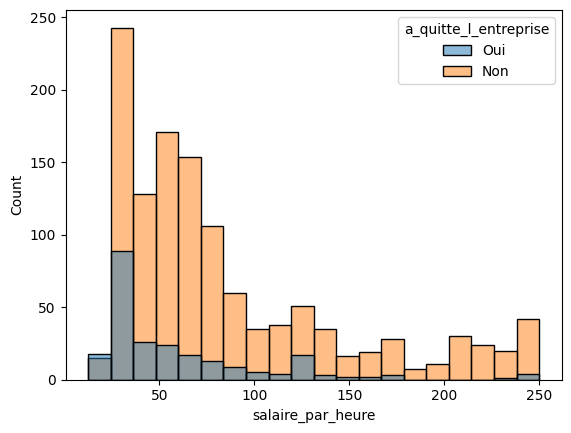

In [50]:
df_result["salaire_par_heure"] = df_result["revenu_mensuel"] / df_result["nombre_heures_travailless"]

sns.histplot(df_result, x='salaire_par_heure', hue='a_quitte_l_entreprise')
plt.show()

---
#### Bilan Features créées intéressantes :

Les +
- satisfaction_moyenne + dispersion_satisfaction
- ratio_fidelite , ratio_stagnation_poste , duree_moyenne_experience 
- salaire_par_annee_experience 


Les -
- salaire_vs_poste
- salaire_vs_niveau
- composée
    - ( salaire_vs_poste , ratio_stagnation_poste => stagnation_sous_payee )
- salaire_par_heure (heures travaillées contantes) ou salaire_ajuste (légère différence de prime): quasi identiques au salaire_mensuel




---
#### 8. Recherche des corrélations


##### 8.1 Reprise Features

In [7]:
# Merge --------------------------------------------
def merge():
    # formatage colonne eval
    extrait_eval['eval_number'] = extrait_eval['eval_number'].apply(lambda x: x.replace('E_', '',)if isinstance(x, str) else x)
    extrait_eval['eval_number'] = pd.to_numeric(extrait_eval['eval_number'], errors='coerce')

    # merge de eval et sirh
    df_temp = extrait_sirh.merge(extrait_eval, left_on='id_employee', right_on='eval_number', how='outer')
    df_temp = df_temp.drop('eval_number',axis=1)

    # merge de df1 et sondage
    df_merge = df_temp.merge(extrait_sondage, left_on='id_employee', right_on='code_sondage', how='outer')
    df_corr = df_merge.drop('code_sondage',axis=1)
    return df_corr

#df_corr = merge()

# Feature + ----------------------------------------
def features(df_corr):
    # satisfaction_moyenne + dispersion_satisfaction
    satisfaction_cols = [
        "satisfaction_employee_environnement",
        "satisfaction_employee_nature_travail",
        "satisfaction_employee_equipe",
        "satisfaction_employee_equilibre_pro_perso"
    ]

    df_corr["satisfaction_globale"] = df_corr[satisfaction_cols].mean(axis=1)
    df_corr["dispersion_satisfaction"] = df_corr[satisfaction_cols].std(axis=1)    
    df_corr = df_corr.drop(columns=satisfaction_cols)

    # ratio_fidelite , ratio_stagnation_poste , duree_moyenne_experience 
    df_corr["ratio_fidelite"] = df_corr["annees_dans_l_entreprise"] / df_corr["annee_experience_totale"].replace(0, 1)
    df_corr["ratio_stagnation_poste"] = df_corr["annees_dans_le_poste_actuel"] / df_corr["annees_dans_l_entreprise"].replace(0, 1)
    df_corr["duree_moyenne_experience"] = df_corr["annee_experience_totale"] / (df_corr["nombre_experiences_precedentes"] + 1)

    # salaire_par_annee_experience 
    df_corr["salaire_par_annee_experience"] = df_corr["revenu_mensuel"] / (df_corr["annee_experience_totale"] + 1)

    # salaire_vs_poste
    salaire_moyen_poste = df_corr.groupby("poste")["revenu_mensuel"].transform("mean") 
    df_corr["salaire_vs_poste"] = df_corr["revenu_mensuel"] / salaire_moyen_poste
    salaire_moyen_niveau = df_corr.groupby("niveau_hierarchique_poste")["revenu_mensuel"].transform("mean") 
    df_corr["salaire_vs_niveau"] = df_corr["revenu_mensuel"] / salaire_moyen_niveau
    return df_corr

# Transformation ----------------------------------------
def transfo_df(df):
    df = df.copy()

    # Variables binaires
    df['genre'] = df['genre'].apply({'F': 0, 'M': 1}.get)
    df['heure_supplementaires'] = df['heure_supplementaires'].apply({'Non': 0, 'Oui': 1}.get)
    #df['a_quitte_l_entreprise'] = df['a_quitte_l_entreprise'].apply({'Non': 0, 'Oui': 1}.get)

    # Nettoyage et conversion en entier
    df['augementation_salaire_precedente'] = df['augementation_salaire_precedente'].apply(lambda x: int(x.replace(' %', '')))

    # Variable ordinale
    df['frequence_deplacement'] = df['frequence_deplacement'].apply({'Aucun': 0, 'Occasionnel': 1, 'Frequent': 2}.get)

    return df
# ---------------------------------------------------

# df_merge = merge()
# df_transfo = transfo_df(df_merge)
# df_corr = features(df_transfo)

#print(df)

In [42]:
df_merge = merge()
df_transfo = transfo_df(df_merge)
df_corr = features(df_transfo)
print(df_corr.columns)

Index(['id_employee', 'age', 'genre', 'revenu_mensuel', 'statut_marital',
       'departement', 'poste', 'nombre_experiences_precedentes',
       'nombre_heures_travailless', 'annee_experience_totale',
       'annees_dans_l_entreprise', 'annees_dans_le_poste_actuel',
       'note_evaluation_precedente', 'niveau_hierarchique_poste',
       'note_evaluation_actuelle', 'heure_supplementaires',
       'augementation_salaire_precedente', 'a_quitte_l_entreprise',
       'nombre_participation_pee', 'nb_formations_suivies',
       'nombre_employee_sous_responsabilite', 'distance_domicile_travail',
       'niveau_education', 'domaine_etude', 'ayant_enfants',
       'frequence_deplacement', 'annees_depuis_la_derniere_promotion',
       'annes_sous_responsable_actuel', 'satisfaction_globale',
       'dispersion_satisfaction', 'ratio_fidelite', 'ratio_stagnation_poste',
       'duree_moyenne_experience', 'salaire_par_annee_experience',
       'salaire_vs_poste', 'salaire_vs_niveau'],
      dtype='

##### 8.2 Corrélations

      id_employee  age  genre  revenu_mensuel statut_marital departement  \
0               1   41      0            5993    Célibataire  Commercial   
1               2   49      1            5130       Marié(e)  Consulting   
2               4   37      1            2090    Célibataire  Consulting   
3               5   33      0            2909       Marié(e)  Consulting   
4               7   27      1            3468       Marié(e)  Consulting   
...           ...  ...    ...             ...            ...         ...   
1465         2061   36      1            2571       Marié(e)  Consulting   
1466         2062   39      1            9991       Marié(e)  Consulting   
1467         2064   27      1            6142       Marié(e)  Consulting   
1468         2065   49      1            5390       Marié(e)  Commercial   
1469         2068   34      1            4404       Marié(e)  Consulting   

                       poste  nombre_experiences_precedentes  \
0           Cadre Comme

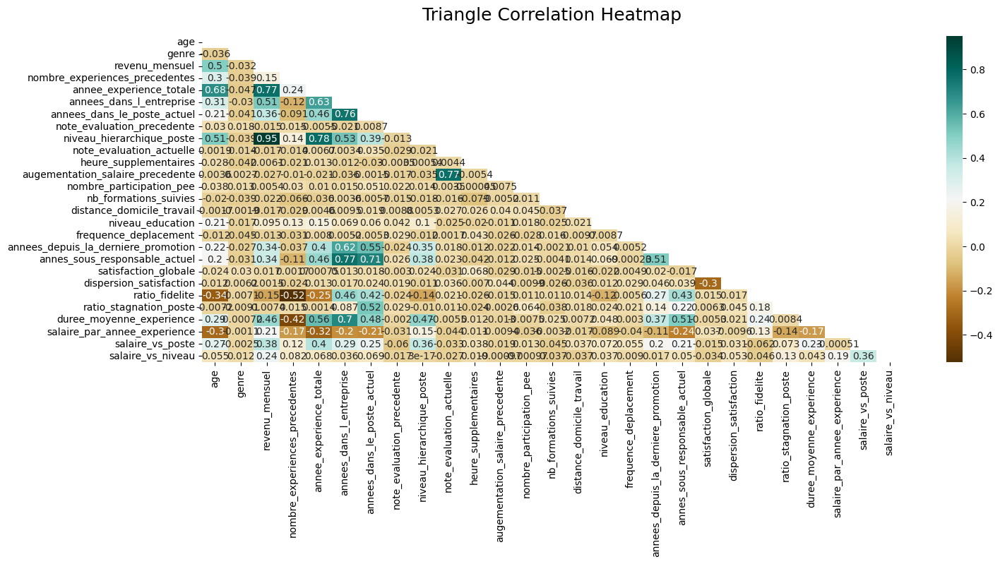

In [11]:
drop_col = ['nombre_heures_travailless', 
            'nombre_employee_sous_responsabilite', 
            'ayant_enfants','id_employee','a_quitte_l_entreprise',
            'statut_marital','departement','poste','domaine_etude' 
]
print(df_corr)
df_corr = df_corr.drop(columns=drop_col)


# Person
def matrice(df,methode):
    corr_per = df.corr(method=methode )#, min_periods=3)
    plt.figure(figsize=(16, 6))
    mask = np.triu(np.ones_like(corr_per, dtype=np.bool))
    heatmap = sns.heatmap(corr_per, mask=mask, annot=True, cmap='BrBG')

    heatmap.set_title('Triangle Correlation Heatmap', fontdict={'fontsize':18}, pad=16)

matrice(df_corr,'pearson')

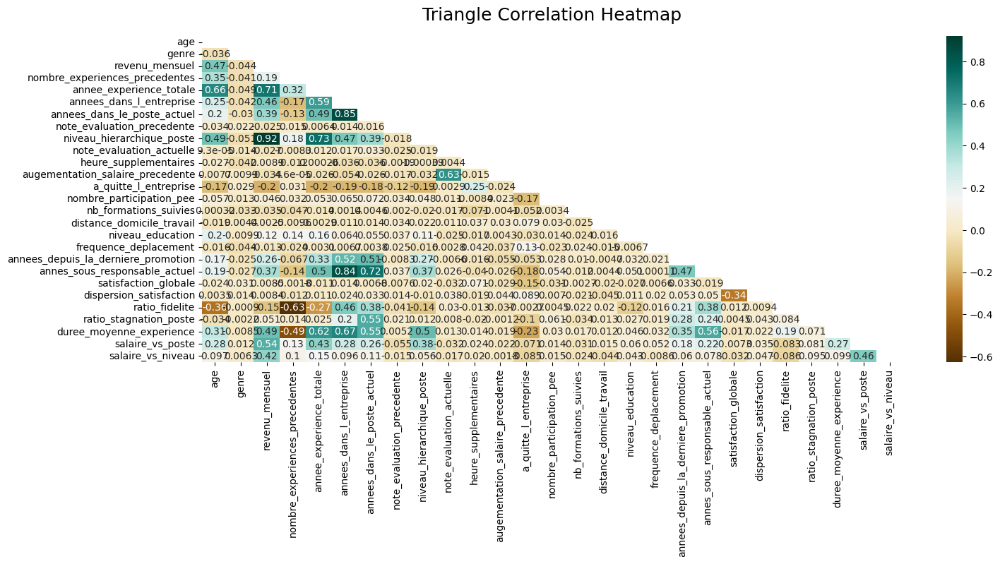

In [ ]:
# Spearman
matrice(df_corr,'spearman')

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
df_vif = df_corr#.drop(columns=['a_quitte_l_entreprise'])
X = df_vif
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]
print(vif_data.to_string())

                                feature         VIF
0                                   age   34.603118
1                                 genre    2.519586
2                        revenu_mensuel   77.897453
3        nombre_experiences_precedentes    5.571836
4               annee_experience_totale   31.172613
5              annees_dans_l_entreprise   22.860148
6           annees_dans_le_poste_actuel   11.867809
7            note_evaluation_precedente   15.238365
8             niveau_hierarchique_poste  112.980437
9              note_evaluation_actuelle  143.653205
10                heure_supplementaires    1.429164
11     augementation_salaire_precedente   43.549827
12             nombre_participation_pee    1.892410
13                nb_formations_suivies    5.656485
14            distance_domicile_travail    2.321222
15                     niveau_education    9.527014
16                frequence_deplacement    5.236254
17  annees_depuis_la_derniere_promotion    2.494571
18        an

- 1 annee_experience_totale , revenu_mensuel
- 1 annees_dans_le_poste_actuel , annes_dans_l_entreprise
- 2 **niveau_hierarchique_du_poste** , revenu_mensuel , annee_experience_totale
- 1 augmentation_salaire_precedente , note_evaluation_actuelle
- 2 annes_sous_responsable_actuel , annees_dans_l_entreprise , annees_dans_le_poste_actuel
- 2 ratio_fidelite , age , nombre_experiences_precedentes , 

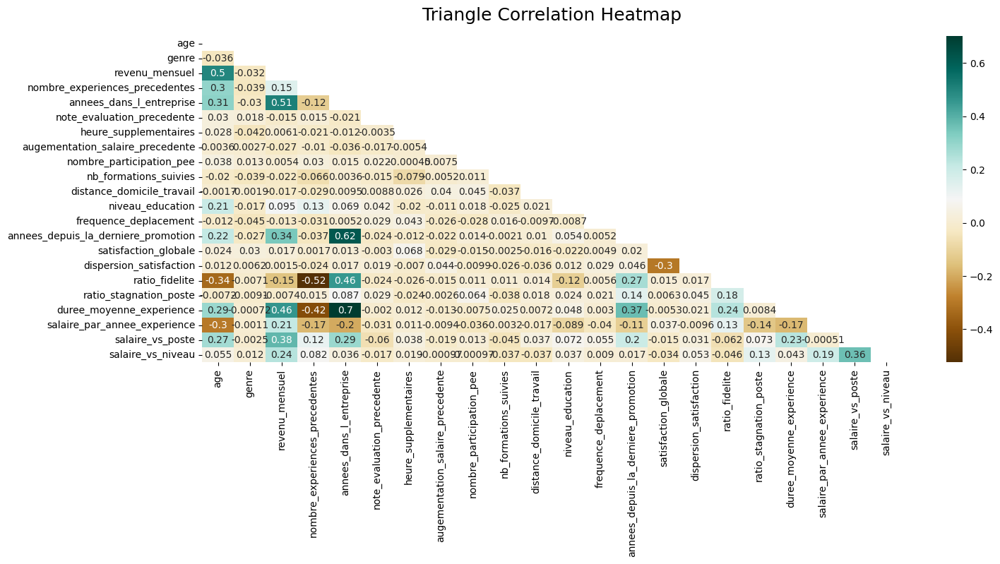

In [15]:
# Test après suppression des Features trop corrélées
corr_feat_col = ['niveau_hierarchique_poste',
    'annees_dans_le_poste_actuel',
    'note_evaluation_actuelle',
    'annes_sous_responsable_actuel',
    'annee_experience_totale'
]

df_temp = df_corr.drop(columns=corr_feat_col)

matrice(df_temp,'pearson')

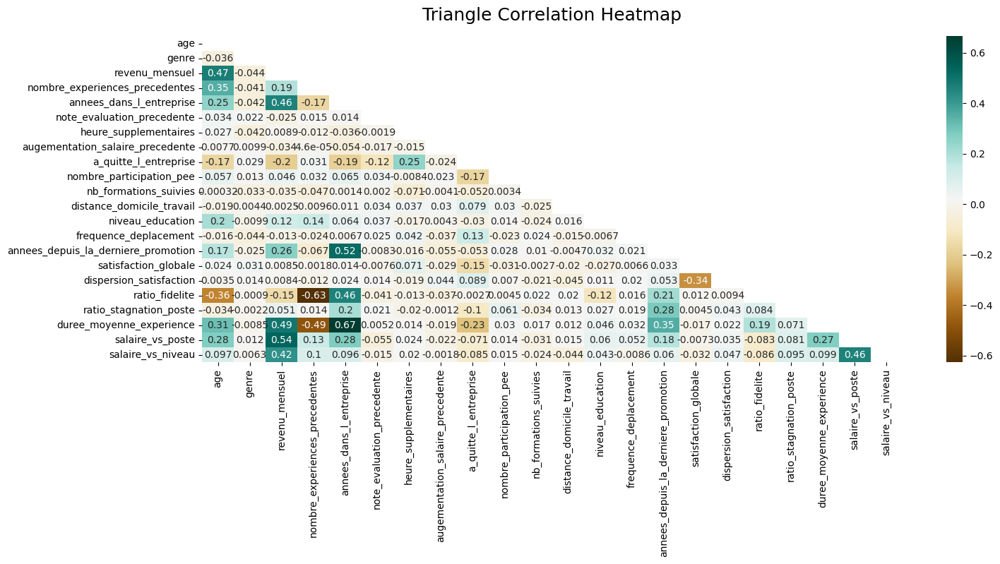

In [73]:
matrice(df_temp,'spearman')

In [84]:
df_vif = df_temp.drop(columns=['a_quitte_l_entreprise'])
X = df_vif
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]
print(vif_data.to_string())

                                feature        VIF
0                                   age  28.506252
1                                 genre   2.505123
2                        revenu_mensuel  10.030184
3        nombre_experiences_precedentes   5.289197
4              annees_dans_l_entreprise  14.013263
5            note_evaluation_precedente  14.718227
6                 heure_supplementaires   1.425394
7      augementation_salaire_precedente  16.535810
8              nombre_participation_pee   1.886837
9                 nb_formations_suivies   5.548492
10            distance_domicile_travail   2.297150
11                     niveau_education   9.369048
12                frequence_deplacement   5.123191
13  annees_depuis_la_derniere_promotion   2.455302
14                 satisfaction_globale  26.089735
15              dispersion_satisfaction   8.430561
16                       ratio_fidelite  16.883421
17               ratio_stagnation_poste   4.690429
18             duree_moyenne_ex

---
#### 9. Pipeline

In [8]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer , LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
    StratifiedKFold,
)

from sklearn.metrics import (f1_score,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix, 
    ConfusionMatrixDisplay,
    roc_curve, auc,
    )

# -----------------------------------------------------------------------
# Reconstruction du dataframe
df_merge_pipe = merge()
df_feat_pipe = features(df_merge_pipe)

drop_col = ['nombre_heures_travailless', 
            'nombre_employee_sous_responsabilite', 
            'ayant_enfants','id_employee',
            'niveau_hierarchique_poste',
            'annees_dans_le_poste_actuel',
            'note_evaluation_actuelle',
            'annes_sous_responsable_actuel',
            'annee_experience_totale'
]

df_feat_pipe_drop = df_feat_pipe.drop(columns=drop_col)

# Transformation -----------------------------------------------------------
binary_map = {
    'genre': {'F': 0, 'M': 1},
    'heure_supplementaires': {'Non': 0, 'Oui': 1},
    #'a_quitte_l_entreprise': {'Non': 0, 'Oui': 1}
}

binary_transformer = FunctionTransformer(
    lambda X: X.replace(binary_map),
    feature_names_out='one-to-one'
)

percent_transformer = FunctionTransformer(
    lambda X: X.iloc[:, 0]
              .str.replace(' %','',regex=False)
              .astype(int)
              .to_frame(),
    feature_names_out='one-to-one'
)

pd.set_option('future.no_silent_downcasting', True)
freq_transformer = FunctionTransformer(
    lambda X: X.replace({'Aucun': 0, 'Occasionnel': 1, 'Frequent': 2}).infer_objects(copy=False),
    feature_names_out='one-to-one'
)
'''
FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. 
To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. 
To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
'''
# Colonnes ---------------------------------------------------------
df_feat_pipe_clean = df_feat_pipe_drop
df_feat_pipe_clean['a_quitte_l_entreprise'] = df_feat_pipe_drop['a_quitte_l_entreprise'].apply({'Non': 0, 'Oui': 1}.get)

cat_cols = ['statut_marital','departement','poste', 'domaine_etude']
binary_cols = ['genre','heure_supplementaires']#,'a_quitte_l_entreprise']
percent_col = ['augementation_salaire_precedente']
freq_col = ['frequence_deplacement']

preprocessor = ColumnTransformer(
    transformers=[
        ('binary', binary_transformer, binary_cols),
        ('percent', percent_transformer, percent_col),
        ('freq', freq_transformer, freq_col),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
    ],
    #remainder='drop'
    remainder='passthrough'
)


##### 9.1 DummyClassifier

              precision    recall  f1-score   support

           0       0.87      1.00      0.93       255
           1       0.00      0.00      0.00        39

    accuracy                           0.87       294
   macro avg       0.43      0.50      0.46       294
weighted avg       0.75      0.87      0.81       294



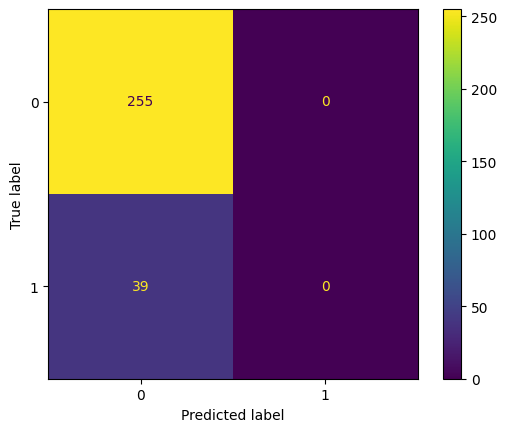

In [44]:
#modeles=[DummyClassifier,LogisticRegression,RandomForestClassifier,CatBoostClassifier]
model = DummyClassifier()
pipeline_dum = Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])

X = df_feat_pipe_clean.drop(columns=['a_quitte_l_entreprise'])
y = df_feat_pipe_clean['a_quitte_l_entreprise']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline_dum.fit(X_train,y_train)

predictions= pipeline_dum.predict(X_test)

cm = confusion_matrix(y_test,predictions)
print(classification_report(y_test,predictions,zero_division=0.0))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=pipeline_dum.classes_)
disp.plot()


##### 9.2 LogisticRegression

Métriques de train :
Accuracy : 0.8920068027210885
              precision    recall  f1-score   support

           0       0.90      0.98      0.94       978
           1       0.83      0.45      0.59       198

    accuracy                           0.89      1176
   macro avg       0.86      0.72      0.76      1176
weighted avg       0.89      0.89      0.88      1176

ROC AUC Score (train) : 0.8675662556030654
-------------------------------------------------------
Métriques de test :
Accuracy : 0.8741496598639455
              precision    recall  f1-score   support

           0       0.90      0.96      0.93       255
           1       0.55      0.28      0.37        39

    accuracy                           0.87       294
   macro avg       0.72      0.62      0.65       294
weighted avg       0.85      0.87      0.86       294

ROC AUC Score (test) : 0.8046254399195576
[[246   9]
 [ 28  11]]


h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


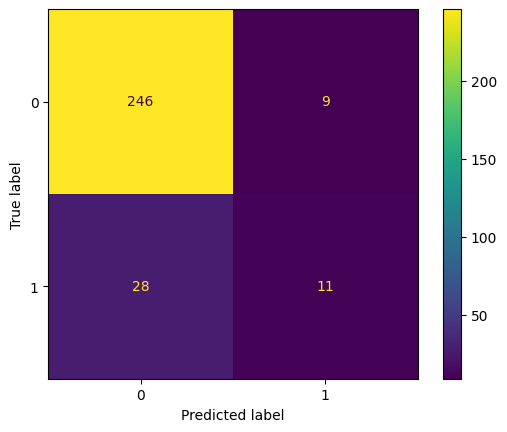

In [45]:
#modeles=[DummyClassifier,LogisticRegression,RandomForestClassifier,CatBoostClassifier]
model = LogisticRegression(solver='lbfgs', max_iter=1000)
'''
ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT
'''
pipeline_logi = Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])

X = df_feat_pipe_clean.drop(columns=['a_quitte_l_entreprise'])
y = df_feat_pipe_clean['a_quitte_l_entreprise']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline_logi.fit(X_train,y_train)

# Prédictions sur les deux jeux
y_train_pred = pipeline_logi.predict(X_train)
y_test_pred = pipeline_logi.predict(X_test)

# Probabilités pour ROC AUC
y_train_prob = pipeline_logi.predict_proba(X_train)[:, 1]
y_test_prob = pipeline_logi.predict_proba(X_test)[:, 1]
#------------------------------------------------------------------------
print("Métriques de train :")
print("Accuracy :", accuracy_score(y_train, y_train_pred))
print(classification_report(y_train, y_train_pred))

print("ROC AUC Score (train) :", roc_auc_score(y_train, y_train_prob))
#------------------------------------------------------------------------
print("-------------------------------------------------------")
print("Métriques de test :")
print("Accuracy :", accuracy_score(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))

print("ROC AUC Score (test) :", roc_auc_score(y_test, y_test_prob))

# predictions= pipeline_logi.predict(X_test)
cm = confusion_matrix(y_test,y_test_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=pipeline_logi.classes_)
disp.plot()
print(cm)



- LogisticRegression :
    - precision(oui)/recall  0.83/0.45 en train et 0.55/0.28 en test
    - ROC AUC Score (train) : 0.86
    - ROC AUC Score (test) :  0.80    
    - globalement score du non > oui

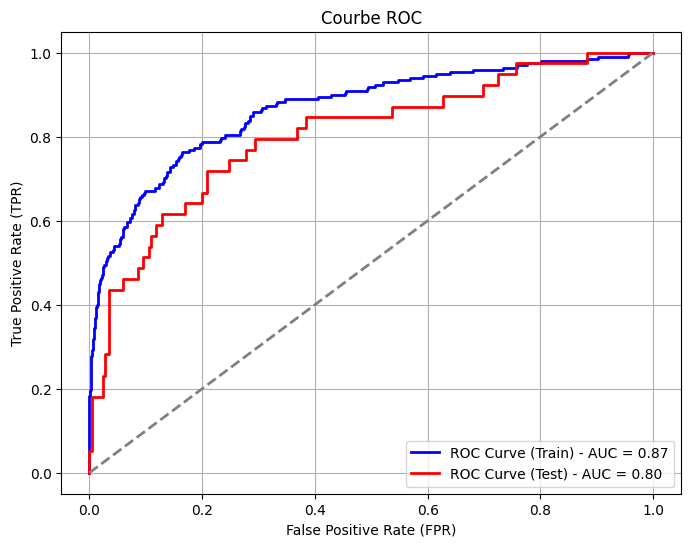

[4.00358906e-04 7.59082123e-04 1.12701613e-03 1.22009000e-03
 1.34974912e-03 1.35314405e-03 1.57580566e-03 1.57998046e-03
 1.67334661e-03 2.13948123e-03 2.15199377e-03 2.37873156e-03
 2.38828746e-03 2.51858823e-03 2.65107013e-03 2.92364500e-03
 2.92556701e-03 3.30629842e-03 3.32988327e-03 3.36373453e-03
 4.47430871e-03 4.53649879e-03 4.86217919e-03 5.25529274e-03
 5.32356866e-03 5.68453531e-03 5.83731789e-03 6.14904982e-03
 6.45649844e-03 6.61545113e-03 6.83886688e-03 7.14703348e-03
 7.30585571e-03 7.46734437e-03 7.77057291e-03 8.17947626e-03
 8.33768521e-03 8.86897120e-03 9.58851269e-03 9.63144084e-03
 1.03744259e-02 1.04392644e-02 1.05899382e-02 1.10883353e-02
 1.14492115e-02 1.17369938e-02 1.22075401e-02 1.22615699e-02
 1.26541288e-02 1.29066834e-02 1.31903375e-02 1.35111454e-02
 1.42825993e-02 1.45328139e-02 1.50364076e-02 1.50521253e-02
 1.56350865e-02 1.59975550e-02 1.60585818e-02 1.70161205e-02
 1.70790044e-02 1.71571388e-02 1.72497821e-02 1.73388894e-02
 1.75986310e-02 1.783646

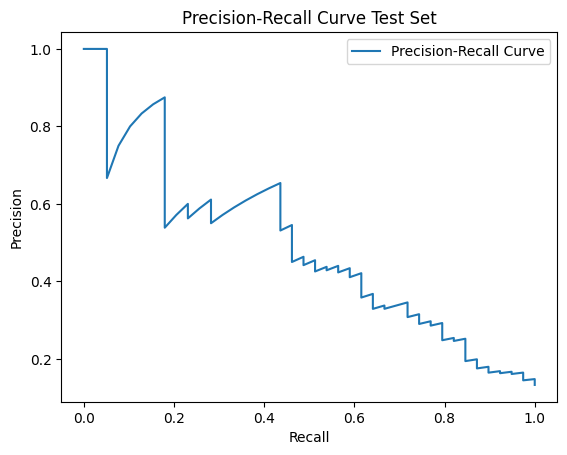

In [46]:
from sklearn.metrics import precision_recall_curve
# Encoder les labels 'Non' et 'Oui' en 0 et 1
#le = LabelEncoder()
#y_train_encoded = le.fit_transform(y_train)
#y_test_encoded = le.transform(y_test)

# Calcul des courbes ROC pour l'entraînement et le test
fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_train_prob)
fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_test_prob)

# Calcul de l'AUC
roc_auc_train = auc(fpr_train, tpr_train)
roc_auc_test = auc(fpr_test, tpr_test)

# Tracer la courbe ROC
plt.figure(figsize=(8, 6))

# Courbe ROC pour l'entraînement
plt.plot(fpr_train, tpr_train, color='blue', lw=2, label=f'ROC Curve (Train) - AUC = {roc_auc_train:.2f}')
# Courbe ROC pour le test
plt.plot(fpr_test, tpr_test, color='red', lw=2, label=f'ROC Curve (Test) - AUC = {roc_auc_test:.2f}')

# Tracer la ligne diagonale (cas où AUC = 0.5, modèle aléatoire)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=2)

# Paramètres du graphique
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Courbe ROC')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()
# -----------------------------------
y_scores_test = pipeline_logi.predict_proba(X_test)[:, 1]
precision_test, recall_test, thresholds_test = precision_recall_curve(y_test, y_scores_test)
print(thresholds_test)
plt.plot(recall_test, precision_test, label="Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Test Set")
plt.legend()
plt.show()



Métriques sur le jeu d'entraînement avec seuil ajusté :
              precision    recall  f1-score   support

           0       0.99      0.28      0.44       978
           1       0.22      0.98      0.36       198

    accuracy                           0.40      1176
   macro avg       0.60      0.63      0.40      1176
weighted avg       0.86      0.40      0.42      1176

ROC AUC Score (train) : 0.8753950548429077
Métriques sur le jeu de test avec seuil ajusté :
              precision    recall  f1-score   support

           0       0.99      0.28      0.43       255
           1       0.17      0.97      0.29        39

    accuracy                           0.37       294
   macro avg       0.58      0.63      0.36       294
weighted avg       0.88      0.37      0.42       294

ROC AUC Score (test) : 0.7762694821518351
[[ 71 184]
 [  1  38]]


h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


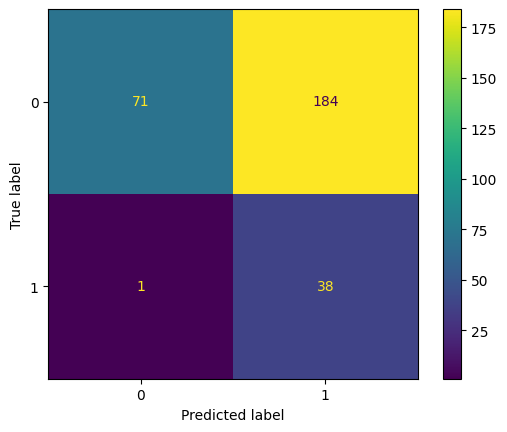

In [52]:
model = LogisticRegression(class_weight='balanced',solver='lbfgs', max_iter=1000)
'''
ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT
'''
pipeline_logi = Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])

X = df_feat_pipe_clean.drop(columns=['a_quitte_l_entreprise'])
y = df_feat_pipe_clean['a_quitte_l_entreprise']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline_logi.fit(X_train,y_train)

# Prédictions sur les deux jeux
y_train_pred = pipeline_logi.predict(X_train)
y_test_pred = pipeline_logi.predict(X_test)

# Probabilités pour ROC AUC
y_train_prob = pipeline_logi.predict_proba(X_train)[:, 1]
y_test_prob = pipeline_logi.predict_proba(X_test)[:, 1]
#------------------------------------------------------------------------
# Choisir un seuil 
y_train_pred_custom = (y_train_prob > 0.1).astype(int)
y_test_pred_custom = (y_test_prob > 0.1).astype(int)

print("Métriques sur le jeu d'entraînement avec seuil ajusté :")
print(classification_report(y_train, y_train_pred_custom))
print("ROC AUC Score (train) :", roc_auc_score(y_train, y_train_prob))

print("Métriques sur le jeu de test avec seuil ajusté :")
print(classification_report(y_test, y_test_pred_custom))
print("ROC AUC Score (test) :", roc_auc_score(y_test, y_test_prob))

# predictions= pipeline_logi.predict(X_test)
cm = confusion_matrix(y_test,y_test_pred_custom)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=pipeline_logi.classes_)
disp.plot()
print(cm)

variation selon le seuil:

| seuil        | 0.8  | 0.5  | 0.3  | 0.2  | 0.1  |
| ------------ | ---- | ---- | ---- | ---- | ---- |
| recall train | 0.47 | 0.79 | 0.9 | 0.94 | 0.98 |
| recall test  | 0.31 | 0.62 | 0.82 | 0.90 | 0.97 |


h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


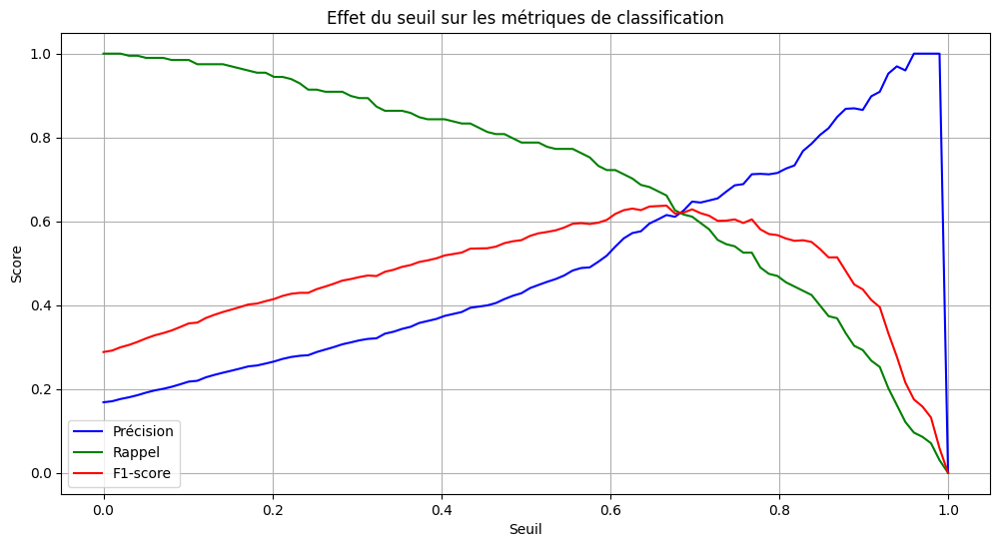

In [53]:
# Calcul des différentes métriques pour un éventail de seuils
thresholds = np.linspace(0, 1, 100)
precisions, recalls, f1_scores = [], [], []

for threshold in thresholds:
    y_train_pred_custom = (y_train_prob > threshold).astype(int)
    y_test_pred_custom = (y_test_prob > threshold).astype(int)
    
    # Calcul des métriques pour le seuil courant
    precision_train = precision_score(y_train, y_train_pred_custom)
    recall_train = recall_score(y_train, y_train_pred_custom)
    f1_train = f1_score(y_train, y_train_pred_custom)
    
    precisions.append(precision_train)
    recalls.append(recall_train)
    f1_scores.append(f1_train)

# Tracer l'effet du seuil sur la précision, le rappel et le F1-score
plt.figure(figsize=(12, 6))

plt.plot(thresholds, precisions, label='Précision', color='blue')
plt.plot(thresholds, recalls, label='Rappel', color='green')
plt.plot(thresholds, f1_scores, label='F1-score', color='red')

plt.xlabel('Seuil')
plt.ylabel('Score')
plt.title('Effet du seuil sur les métriques de classification')
plt.legend(loc='best')
plt.grid(True)
plt.show()

Métriques sur le jeu d'entraînement avec SMOTE :
              precision    recall  f1-score   support

           0       0.95      0.80      0.87       978
           1       0.44      0.77      0.56       198

    accuracy                           0.79      1176
   macro avg       0.69      0.79      0.71      1176
weighted avg       0.86      0.79      0.81      1176

ROC AUC Score (train) : 0.8753950548429077
Métriques sur le jeu de test avec SMOTE :
              precision    recall  f1-score   support

           0       0.94      0.75      0.83       255
           1       0.29      0.67      0.40        39

    accuracy                           0.74       294
   macro avg       0.61      0.71      0.62       294
weighted avg       0.85      0.74      0.78       294

ROC AUC Score (test) : 0.7762694821518351
[[191  64]
 [ 13  26]]


h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


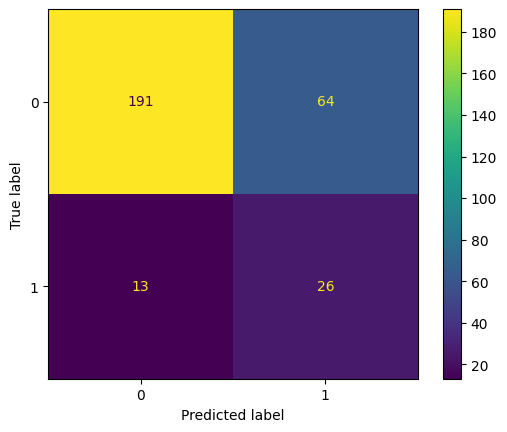

In [54]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Créer un pipeline avec SMOTE
smote = SMOTE(sampling_strategy='auto', random_state=42)
model = LogisticRegression(solver='lbfgs', max_iter=1000)

# Utiliser un pipeline ImbPipeline pour combiner SMOTE et le modèle
imb_pipeline = ImbPipeline([
    ('prep', preprocessor),
    ('smote', smote),
    ('model', model)
])

X = df_feat_pipe_clean.drop(columns=['a_quitte_l_entreprise'])
y = df_feat_pipe_clean['a_quitte_l_entreprise']

# Réentraîner le modèle avec SMOTE
imb_pipeline.fit(X_train, y_train)

# Prédictions
y_train_pred = imb_pipeline.predict(X_train)
y_test_pred = imb_pipeline.predict(X_test)

# Calcul des métriques
print("Métriques sur le jeu d'entraînement avec SMOTE :")
print(classification_report(y_train, y_train_pred))
print("ROC AUC Score (train) :", roc_auc_score(y_train, y_train_prob))

print("Métriques sur le jeu de test avec SMOTE :")
print(classification_report(y_test, y_test_pred))
print("ROC AUC Score (test) :", roc_auc_score(y_test, y_test_prob))

cm = confusion_matrix(y_test,y_test_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=pipeline_logi.classes_)
disp.plot()
print(cm)

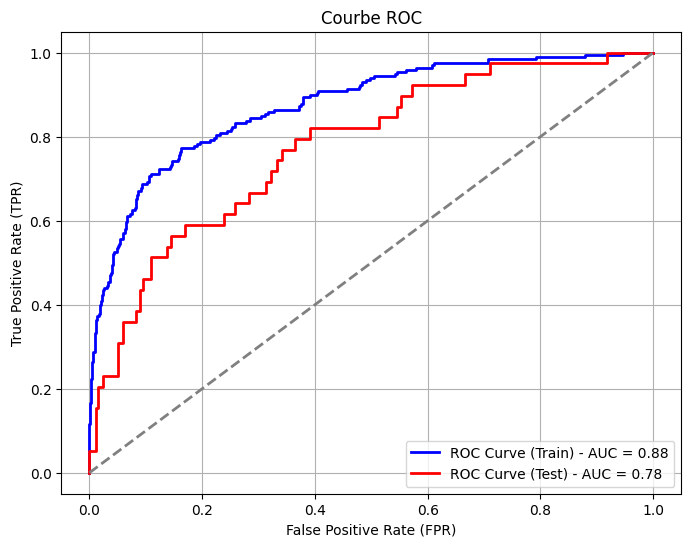

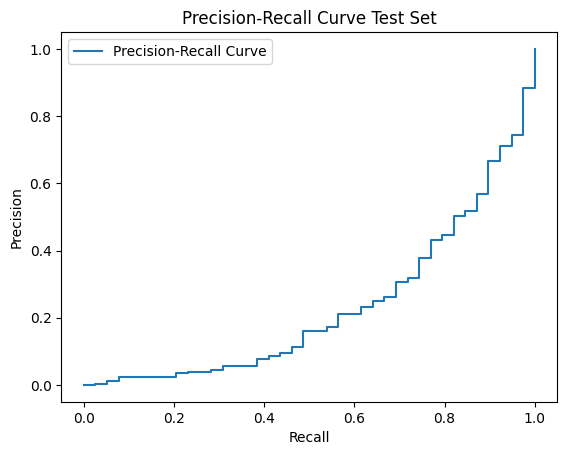

In [55]:
# Encoder les labels 'Non' et 'Oui' en 0 et 1
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# Calcul des courbes ROC pour l'entraînement et le test
fpr_train, tpr_train, thresholds_train = roc_curve(y_train_encoded, y_train_prob)
fpr_test, tpr_test, thresholds_test = roc_curve(y_test_encoded, y_test_prob)

# Calcul de l'AUC
roc_auc_train = auc(fpr_train, tpr_train)
roc_auc_test = auc(fpr_test, tpr_test)

# Tracer la courbe ROC
plt.figure(figsize=(8, 6))

# Courbe ROC pour l'entraînement
plt.plot(fpr_train, tpr_train, color='blue', lw=2, label=f'ROC Curve (Train) - AUC = {roc_auc_train:.2f}')
# Courbe ROC pour le test
plt.plot(fpr_test, tpr_test, color='red', lw=2, label=f'ROC Curve (Test) - AUC = {roc_auc_test:.2f}')

# Tracer la ligne diagonale (cas où AUC = 0.5, modèle aléatoire)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=2)

# Paramètres du graphique
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Courbe ROC')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()
# -----------------------------------
y_scores_test = imb_pipeline.predict_proba(X_test)[:, 1]
precision_test, recall_test, thresholds_test = roc_curve(y_test_encoded, y_scores_test)

plt.plot(recall_test, precision_test, label="Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Test Set")
plt.legend()
plt.show()

Métriques sur le jeu d'entraînement avec SMOTE et ENN :
              precision    recall  f1-score   support

           0       0.96      0.64      0.77       978
           1       0.33      0.88      0.48       198

    accuracy                           0.68      1176
   macro avg       0.65      0.76      0.62      1176
weighted avg       0.86      0.68      0.72      1176

ROC AUC Score (train) : 0.8704271756418995
Métriques sur le jeu de test avec SMOTE et ENN :
              precision    recall  f1-score   support

           0       0.94      0.58      0.72       255
           1       0.22      0.77      0.34        39

    accuracy                           0.61       294
   macro avg       0.58      0.67      0.53       294
weighted avg       0.85      0.61      0.67       294

ROC AUC Score (test) : 0.7560583207642031
[[148 107]
 [  9  30]]


h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


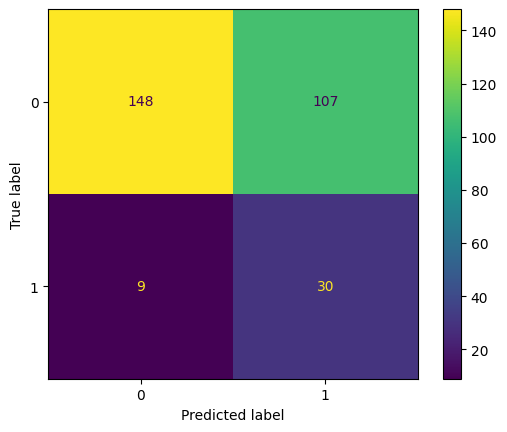

In [56]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import EditedNearestNeighbours

# Créer un pipeline avec SMOTE et ENN
smote = SMOTE(sampling_strategy='auto', random_state=42)
enn = EditedNearestNeighbours(sampling_strategy='majority')

model = LogisticRegression(solver='lbfgs', max_iter=1000)

# Utiliser un pipeline ImbPipeline pour combiner SMOTE, ENN et le modèle
imb_pipeline = ImbPipeline([
    ('prep', preprocessor), 
    ('smote', smote),
    ('enn', enn),
    ('model', model)
])

# Préparer les données 
X = df_feat_pipe_clean.drop(columns=['a_quitte_l_entreprise'])
y = df_feat_pipe_clean['a_quitte_l_entreprise']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Réentraîner le modèle avec SMOTE et ENN
imb_pipeline.fit(X_train, y_train)

# Prédictions
y_train_pred = imb_pipeline.predict(X_train)
y_test_pred = imb_pipeline.predict(X_test)

# Probabilités pour ROC AUC
y_train_prob = imb_pipeline.predict_proba(X_train)[:, 1]
y_test_prob = imb_pipeline.predict_proba(X_test)[:, 1]

# Calcul des métriques
print("Métriques sur le jeu d'entraînement avec SMOTE et ENN :")
print(classification_report(y_train, y_train_pred))
print("ROC AUC Score (train) :", roc_auc_score(y_train, y_train_prob))

print("Métriques sur le jeu de test avec SMOTE et ENN :")
print(classification_report(y_test, y_test_pred))
print("ROC AUC Score (test) :", roc_auc_score(y_test, y_test_prob))

# Matrice de confusion
cm = confusion_matrix(y_test, y_test_pred)

# Afficher la matrice de confusion
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=imb_pipeline.classes_)
disp.plot()
print(cm)

##### 9.3 RandomForestClassifier

Métriques de train :
Accuracy : 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       978
           1       1.00      1.00      1.00       198

    accuracy                           1.00      1176
   macro avg       1.00      1.00      1.00      1176
weighted avg       1.00      1.00      1.00      1176

ROC AUC Score (train) : 1.0
-------------------------------------------------------
Métriques de test :
Accuracy : 0.8673469387755102
              precision    recall  f1-score   support

           0       0.87      0.99      0.93       255
           1       0.50      0.05      0.09        39

    accuracy                           0.87       294
   macro avg       0.69      0.52      0.51       294
weighted avg       0.82      0.87      0.82       294

ROC AUC Score (test) : 0.7442433383609854
[[253   2]
 [ 37   2]]


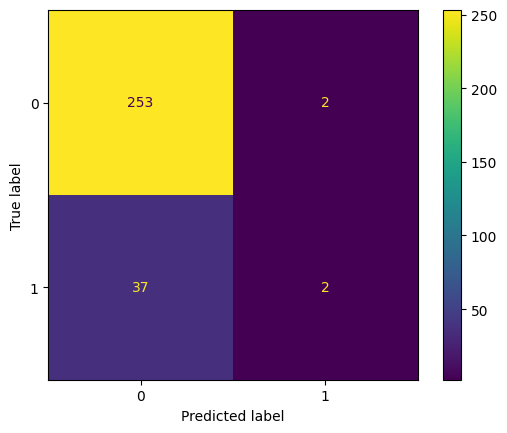

In [57]:
#modeles=[DummyClassifier,LogisticRegression,RandomForestClassifier,CatBoostClassifier]
model = RandomForestClassifier()#class_weight='balanced_subsample')#class_weight='balanced')

pipeline_rand = Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])

X = df_feat_pipe_clean.drop(columns=['a_quitte_l_entreprise'])
y = df_feat_pipe_clean['a_quitte_l_entreprise']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline_rand.fit(X_train,y_train)

# Prédictions sur les deux jeux
y_train_pred = pipeline_rand.predict(X_train)
y_test_pred = pipeline_rand.predict(X_test)

# Probabilités pour ROC AUC
y_train_prob = pipeline_rand.predict_proba(X_train)[:, 1]
y_test_prob = pipeline_rand.predict_proba(X_test)[:, 1]
#------------------------------------------------------------------------
print("Métriques de train :")
print("Accuracy :", accuracy_score(y_train, y_train_pred))
print(classification_report(y_train, y_train_pred))

print("ROC AUC Score (train) :", roc_auc_score(y_train, y_train_prob))
#------------------------------------------------------------------------
print("-------------------------------------------------------")
print("Métriques de test :")
print("Accuracy :", accuracy_score(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))

print("ROC AUC Score (test) :", roc_auc_score(y_test, y_test_prob))

# predictions= pipeline_logi.predict(X_test)
cm = confusion_matrix(y_test,y_test_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=pipeline_rand.classes_)
disp.plot()
print(cm)

Cross-validation accuracy scores :  [0.83474576 0.85531915 0.85531915 0.85106383 0.86382979]
Moyenne de la précision en cross-validation :  0.8520555355210963
Précision en entraînement (cross-validation) :  1.0
Métriques sur l'ensemble d'entraînement :
Accuracy : 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       978
           1       1.00      1.00      1.00       198

    accuracy                           1.00      1176
   macro avg       1.00      1.00      1.00      1176
weighted avg       1.00      1.00      1.00      1176

ROC AUC Score (train) : 1.0
-------------------------------------------------------
Métriques sur l'ensemble de test :
Accuracy : 0.8741496598639455
              precision    recall  f1-score   support

           0       0.88      1.00      0.93       255
           1       0.75      0.08      0.14        39

    accuracy                           0.87       294
   macro avg       0.81      0.54     

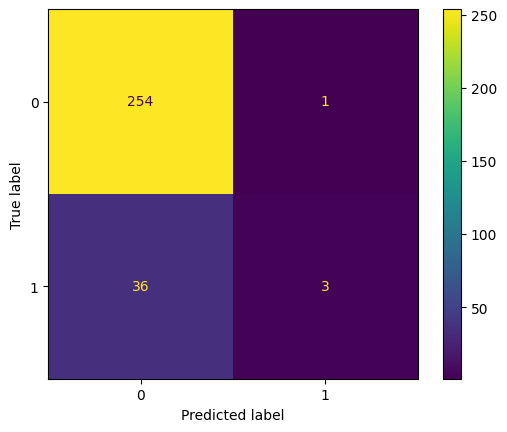

In [58]:
# Définition du modèle
model = RandomForestClassifier()

# Pipeline avec préprocesseur et modèle
pipeline_rand = Pipeline([
    ('prep', preprocessor),  
    ('model', model)
])

# Préparer les données
X = df_feat_pipe_clean.drop(columns=['a_quitte_l_entreprise'])
y = df_feat_pipe_clean['a_quitte_l_entreprise']

# Séparer les données en train et test (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Définir le StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Appliquer la cross-validation stratifiée
cv_results = cross_validate(pipeline_rand, X_train, y_train, cv=skf, scoring='accuracy', return_train_score=True)

# Résultats de la cross-validation
print("Cross-validation accuracy scores : ", cv_results['test_score'])
print("Moyenne de la précision en cross-validation : ", np.mean(cv_results['test_score']))
print("Précision en entraînement (cross-validation) : ", np.mean(cv_results['train_score']))

# Entraînement du modèle sur l'ensemble d'entraînement
pipeline_rand.fit(X_train, y_train)

# Prédictions sur les données d'entraînement et de test
y_train_pred = pipeline_rand.predict(X_train)
y_test_pred = pipeline_rand.predict(X_test)

# Probabilités pour calculer le ROC AUC
y_train_prob = pipeline_rand.predict_proba(X_train)[:, 1]
y_test_prob = pipeline_rand.predict_proba(X_test)[:, 1]

# Métriques sur l'ensemble d'entraînement
print("Métriques sur l'ensemble d'entraînement :")
print("Accuracy :", accuracy_score(y_train, y_train_pred))
print(classification_report(y_train, y_train_pred))
print("ROC AUC Score (train) :", roc_auc_score(y_train, y_train_prob))

# Métriques sur l'ensemble de test
print("-------------------------------------------------------")
print("Métriques sur l'ensemble de test :")
print("Accuracy :", accuracy_score(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))
print("ROC AUC Score (test) :", roc_auc_score(y_test, y_test_prob))

# Matrice de confusion
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipeline_rand.classes_)
disp.plot()
print(cm)


---
#### 10. Version Pipeline Logistic Regression

##### 10.1 Class/Def

In [12]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay,classification_report, roc_auc_score, precision_recall_curve, average_precision_score, fbeta_score, make_scorer
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.linear_model import LogisticRegression

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.inspection import permutation_importance

class ModelHandler:
    def __init__(self, model, param_grid, use_smote=False, use_enn=False, smote_params=None, enn_params=None, stratify=True, preprocessor=None, n_splits=5):
        """
        :param model: Modèle de machine learning (e.g., LogisticRegression)
        :param param_grid: Dictionnaire des hyperparamètres du modèle à utiliser dans GridSearch
        :param use_smote: Booléen pour activer SMOTE
        :param use_enn: Booléen pour activer ENN
        :param smote_params: Paramètres à utiliser pour SMOTE
        :param enn_params: Paramètres à utiliser pour ENN
        :param stratify: Si True, utilise une stratification dans la validation croisée
        :param preprocessor: Transformations de prétraitement (e.g., StandardScaler, OneHotEncoder)
        :param n_splits: Nombre de splits dans la validation croisée
        """
        self.model = model
        self.param_grid = param_grid
        self.use_smote = use_smote
        self.use_enn = use_enn
        self.smote_params = smote_params or {'sampling_strategy': 'auto', 'random_state': 42}
        self.enn_params = enn_params or {'sampling_strategy': 'majority'}
        self.stratify = stratify
        self.n_splits = n_splits  # Nombre de folds pour la validation croisée
        self.metrics = {'precision': [], 'recall': [], 'f1': [], 'roc_auc': [], 'fbeta_2': [], 'fbeta_5': []}
        self.best_params = None
        self.preprocessor = preprocessor

    def build_pipeline(self, X_train):
            """ Build the pipeline with preprocessing, SMOTE, ENN, and the model """
            steps = []
            # Add preprocessor if it is defined
            if self.preprocessor:
                steps.append(('prep', self.preprocessor))
            # Add SMOTE if enabled and with dynamic parameters
            if self.use_smote:
                smote = SMOTE(**self.smote_params)
                steps.append(('smote', smote))        
            # Add ENN if enabled and with dynamic parameters
            if self.use_enn:
                enn = EditedNearestNeighbours(**self.enn_params)
                steps.append(('enn', enn))
            # Add the model
            steps.append(('model', self.model))        
            # Create the pipeline
            self.pipeline = ImbPipeline(steps)

    def grid_search(self, X_train, y_train,wanted_score):
        """ Run a grid search to find the best hyperparameters """  
        grid_search = GridSearchCV(self.pipeline, self.param_grid, cv=StratifiedKFold(n_splits=self.n_splits), n_jobs=-1, scoring=wanted_score)
        grid_search.fit(X_train, y_train)
        self.best_params = grid_search.best_params_
        self.pipeline = grid_search.best_estimator_
        print('----------------------------------------------')
        print("Best hyperparameters found:", self.best_params)
        print('----------------------------------------------')

    def train_model(self, X_train, y_train):
        """ Train the model using StratifiedKFold """
        skf = StratifiedKFold(n_splits=self.n_splits, shuffle=True, random_state=42)
        #ftwo_scorer = make_scorer(fbeta_score, beta=2)
        fold_metrics = {'precision': [], 'recall': [], 'f1': [], 'roc_auc': [], 'fbeta_2': [], 'fbeta_5': []}

        # Perform StratifiedKFold
        for train_idx, val_idx in skf.split(X_train, y_train):
            # Utilisation de iloc pour indexer X_train et y_train correctement
            X_train_fold = X_train.iloc[train_idx]  # .iloc pour DataFrame
            X_val_fold = X_train.iloc[val_idx]
            y_train_fold = y_train.iloc[train_idx]  # .iloc pour Series
            y_val_fold = y_train.iloc[val_idx]

            # Fit the model on the current fold
            self.pipeline.fit(X_train_fold, y_train_fold)
            
            # Evaluate on the validation fold
            y_val_pred = self.pipeline.predict(X_val_fold)
            y_val_prob = self.pipeline.predict_proba(X_val_fold)[:, 1]

            # Store the metrics
            report = classification_report(y_val_fold, y_val_pred, output_dict=True)
            fold_metrics['precision'].append(report['macro avg']['precision'])
            fold_metrics['recall'].append(report['macro avg']['recall'])
            fold_metrics['f1'].append(report['macro avg']['f1-score'])
            fold_metrics['fbeta_2'].append(fbeta_score(y_val_fold, y_val_pred, beta=2))
            fold_metrics['fbeta_5'].append(fbeta_score(y_val_fold, y_val_pred, beta=5))
            fold_metrics['roc_auc'].append(roc_auc_score(y_val_fold, y_val_prob))

        # After training, calculate the average metrics
        self.metrics = {key: np.mean(val) for key, val in fold_metrics.items()}

        return self.metrics


    def evaluate_model(self, X_test, y_test):
        """ Evaluate the model on the test set """
        y_test_pred = self.pipeline.predict(X_test)
        y_test_prob = self.pipeline.predict_proba(X_test)[:, 1]

        # Evaluate the final performance
        report = classification_report(y_test, y_test_pred, output_dict=True)
        self.metrics['precision'] = report['macro avg']['precision']
        self.metrics['recall'] = report['macro avg']['recall']
        self.metrics['f1'] = report['macro avg']['f1-score']
        self.metrics['fbeta_2'] = fbeta_score(y_test, y_test_pred, beta=2)
        self.metrics['fbeta_5'] = fbeta_score(y_test, y_test_pred, beta=5)
        self.metrics['roc_auc'] = roc_auc_score(y_test, y_test_prob)
        
        # Confusion matrix
        cm = confusion_matrix(y_test, y_test_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=self.pipeline.classes_)
        disp.plot()
        plt.show()

        return self.metrics

    def precision_recall_curve(self, X_test, y_test):
        """ Plot precision-recall curve and return optimal threshold """
        y_test_prob = self.pipeline.predict_proba(X_test)[:, 1]
        precision, recall, thresholds = precision_recall_curve(y_test, y_test_prob)
        avg_precision = average_precision_score(y_test, y_test_prob)

        # Plot Precision-Recall curve
        plt.plot(recall, precision, label=f'AP={avg_precision:.2f}')
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title('Precision-Recall curve')
        plt.legend(loc='best')
        plt.show()

        # Find optimal threshold (where precision and recall are closest)
        f1_scores = 2 * (precision * recall) / (precision + recall)
        optimal_threshold = thresholds[np.argmax(f1_scores)]
        print('----------------------------------------------')
        print(f'Optimal threshold: {optimal_threshold}')
        print('----------------------------------------------') 
        return optimal_threshold

##### 10.2 Déclaration

In [17]:
X = df_feat_pipe_clean.drop(columns=['a_quitte_l_entreprise'])
y = df_feat_pipe_clean['a_quitte_l_entreprise']

# Split train-test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)



# Définir le modèle et les paramètres du GridSearch
#model = LogisticRegression( max_iter=1000)
#model = LogisticRegression(solver='lbfgs', max_iter=1000)
model = LogisticRegression( )

#print(X.columns)


##### 10.3 Logistic Regression Stratification

In [67]:
model = LogisticRegression()

param_grid = {
    #'model__solver': [ 'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'],
    #'model__C': [0.1, 1.0, 10],
    #'model__penalty': ['l2','l1'],
    #'model__class_weight': [{0: 1, 1: 10}], #'balanced'],
    'model__max_iter' : [1000],
    #'smote__sampling_strategy': ['auto', 0.5, 0.7],  # Paramètres pour SMOTE
    #'enn__sampling_strategy': ['majority', 0.8]  # Paramètres pour ENN
}

# Instancier la classe avec préprocesseur
handler = ModelHandler(
    model=model, 
    param_grid=param_grid, 
    use_smote=False, 
    use_enn=False, 
    preprocessor=preprocessor
)

handler.build_pipeline(X_train)

metric_train = handler.train_model(X_train, y_train)
print(metric_train)

h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproces

{'precision': np.float64(0.7371633895176062), 'recall': np.float64(0.552917230007799), 'f1': np.float64(0.5548172675307568), 'roc_auc': np.float64(0.7591030529716076), 'fbeta_2': np.float64(0.14255776987880558), 'fbeta_5': np.float64(0.12465883429142104)}


h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


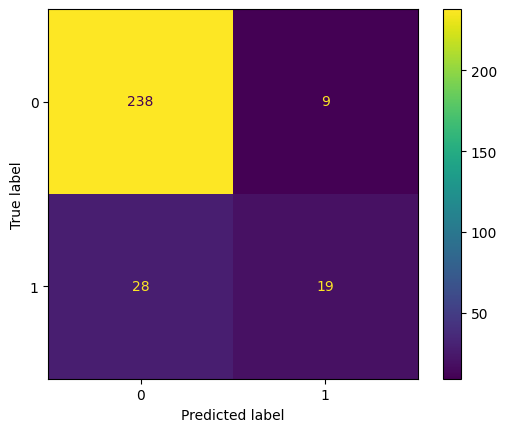

{'precision': 0.7866541353383458, 'recall': 0.6839090360926867, 'f1': 0.717270955165692, 'roc_auc': 0.8171246446722372, 'fbeta_2': 0.4398148148148148, 'fbeta_5': 0.4106400665004156}


In [66]:
metric_test = handler.evaluate_model(X_test, y_test)
print(metric_test)

##### 10.4 Logistic Regression GridSearch

h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
160 fits failed out of a total of 480.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\base.py", line 1336, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "h:\python_project\projet04_bis\.venv\Lib\site-packages\imblearn\pipeline.

----------------------------------------------
Best hyperparameters found: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__max_iter': 1000, 'model__penalty': 'l2', 'model__solver': 'newton-cg'}
----------------------------------------------


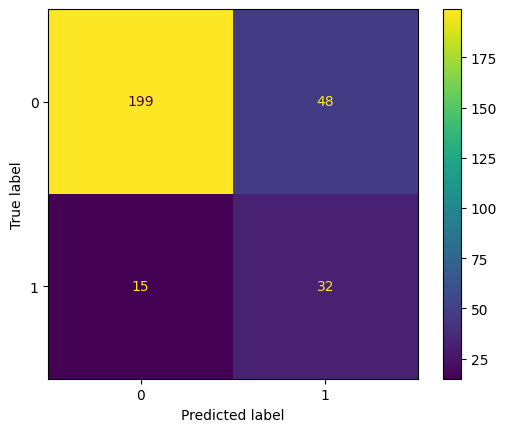

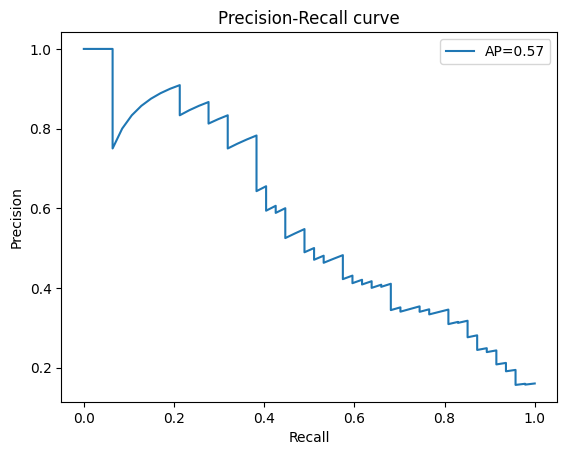

----------------------------------------------
Optimal threshold: 0.5926652047196324
----------------------------------------------


np.float64(0.5926652047196324)

In [68]:

param_grid = {
    'model__solver': [ 'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'],
    'model__C': [0.1, 1.0, 10,100],
    'model__penalty': ['l2','l1'],
    'model__class_weight': [{0: 1, 1: 10},'balanced'],
    'model__max_iter' : [1000],
    #'smote__sampling_strategy': ['auto', 0.5, 0.7],  # Paramètres pour SMOTE
    #'enn__sampling_strategy': ['majority', 0.8]  # Paramètres pour ENN
}

# Instancier la classe avec préprocesseur
handler = ModelHandler(
    model=model, 
    param_grid=param_grid, 
    use_smote=False, 
    use_enn=False, 
    preprocessor=preprocessor
)

handler.build_pipeline(X_train)

fbeta_2 = make_scorer(fbeta_score, beta=2)

# Effectuer un grid search pour optimiser les hyperparamètres:
# 'precision', 'recall', 'f1': , 'roc_auc', 'fbeta_2', 'fbeta_5'
handler.grid_search(X_train, y_train,fbeta_2)
handler.evaluate_model(X_test, y_test)
handler.precision_recall_curve(X_test, y_test)

for fbeta=2
- Best hyperparameters found: {    
    'model__C': 0.1,     
    'model__class_weight': 'balanced',     
    'model__max_iter': 1000,     
    'model__penalty': 'l2',     
    'model__solver': 'newton-cg'    
    }


h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
160 fits failed out of a total of 480.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\base.py", line 1336, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "h:\python_project\projet04_bis\.venv\Lib\site-packages\imblearn\pipeline.

----------------------------------------------
Best hyperparameters found: {'model__C': 0.1, 'model__class_weight': {0: 1, 1: 10}, 'model__max_iter': 1000, 'model__penalty': 'l2', 'model__solver': 'saga'}
----------------------------------------------


h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


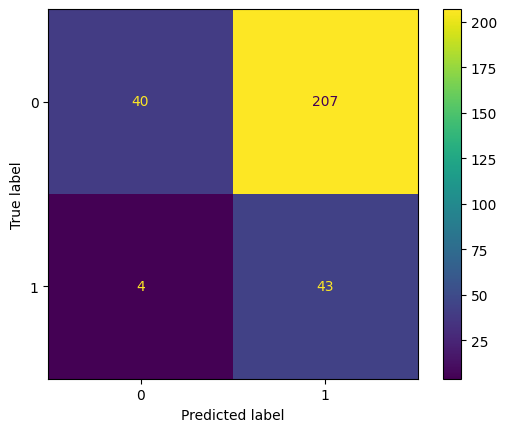

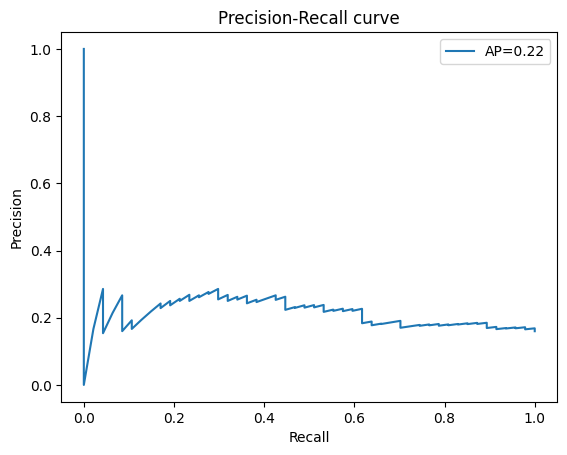

----------------------------------------------
Optimal threshold: 0.8952072722195565
----------------------------------------------


C:\Users\Myself\AppData\Local\Temp\ipykernel_18272\329436126.py:143: RuntimeWarning: invalid value encountered in divide
  f1_scores = 2 * (precision * recall) / (precision + recall)


np.float64(0.8952072722195565)

In [69]:
handler.build_pipeline(X_train)


fbeta_5 = make_scorer(fbeta_score, beta=5)

# Effectuer un grid search pour optimiser les hyperparamètres:
# 'precision', 'recall', 'f1': , 'roc_auc', 'fbeta_2', 'fbeta_5'
handler.grid_search(X_train, y_train,fbeta_5)
handler.evaluate_model(X_test, y_test)
handler.precision_recall_curve(X_test, y_test)

for fbeta=5
- Best hyperparameters found: {    
    'model__C': 0.1,    
    'model__class_weight': {0: 1, 1: 10},     
    'model__max_iter': 1000,     
    'model__penalty': 'l2',     
    'model__solver': 'saga'    
    }



##### 10.5 Logistic Regression Optimisée

In [18]:
model = LogisticRegression(
    #fbeta=2     
    C=0.1,     
    class_weight={0: 1, 1: 10},     
    max_iter=1000,     
    penalty='l2',     
    solver='newton-cg'
    # #fbeta=5
    # C=0.1,     
    # class_weight={0: 1, 1: 10},     
    # max_iter=1000,     
    # penalty='l2',     
    # solver='saga'  
)

h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

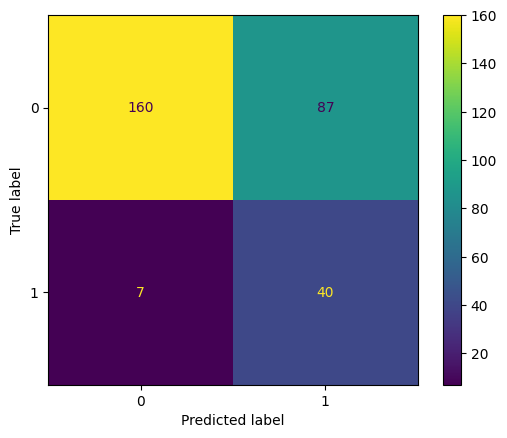

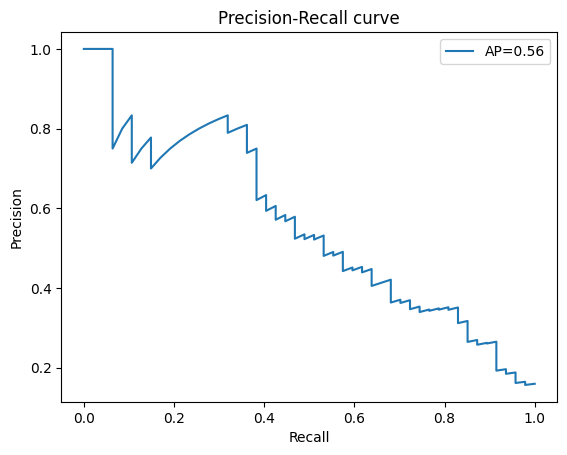

----------------------------------------------
Optimal threshold: 0.8018861375247374
----------------------------------------------


0.8018861375247374

In [ ]:
param_grid = {
    #'model__solver': [ 'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'],
    #'model__C': [0.1, 1.0, 10,100],
    #'model__penalty': ['l2','l1'],
    #'model__class_weight': [{0: 1, 1: 10},'balanced'],
    #'model__max_iter' : [1000],
    #'smote__sampling_strategy': ['auto', 0.5, 0.7],  # Paramètres pour SMOTE
    #'enn__sampling_strategy': ['majority', 0.8]  # Paramètres pour ENN
}

# Instancier la classe avec préprocesseur
handler = ModelHandler(
    model=model, 
    param_grid=param_grid, 
    use_smote=False, 
    use_enn=False, 
    preprocessor=preprocessor
)

handler.build_pipeline(X_train)

handler.train_model(X_train, y_train)

# Effectuer un grid search pour optimiser les hyperparamètres:
# 'precision', 'recall', 'f1': , 'roc_auc', 'fbeta_2', 'fbeta_5'
#handler.grid_search(X_train, y_train,fbeta_2)
handler.evaluate_model(X_test, y_test)
handler.precision_recall_curve(X_test, y_test)


h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


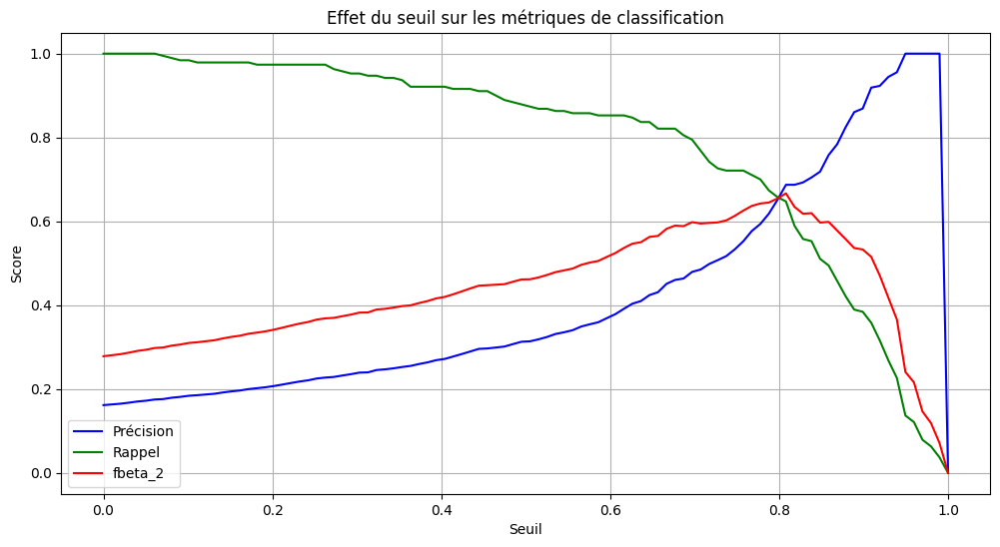

In [25]:
# Prédictions sur les deux jeux
y_train_pred = handler.pipeline.predict(X_train)
y_test_pred = handler.pipeline.predict(X_test)

# Probabilités pour ROC AUC
y_train_prob = handler.pipeline.predict_proba(X_train)[:, 1]
y_test_prob = handler.pipeline.predict_proba(X_test)[:, 1]
#------------------------------------------------------------------------
# Choisir un seuil 
y_train_pred_custom = (y_train_prob > 0.1).astype(int)
y_test_pred_custom = (y_test_prob > 0.1).astype(int)


# Calcul des différentes métriques pour un éventail de seuils
fbeta_2 = make_scorer(fbeta_score, beta=2)
thresholds = np.linspace(0, 1, 100)
precisions, recalls, fbeta_2 = [], [], []

for threshold in thresholds:
    y_train_pred_custom = (y_train_prob > threshold).astype(int)
    y_test_pred_custom = (y_test_prob > threshold).astype(int)
    
    # Calcul des métriques pour le seuil courant
    precision_train = precision_score(y_train, y_train_pred_custom)
    recall_train = recall_score(y_train, y_train_pred_custom)
    f1_train = f1_score(y_train, y_train_pred_custom)
    
    precisions.append(precision_train)
    recalls.append(recall_train)
    fbeta_2.append(f1_train)

# Tracer l'effet du seuil sur la précision, le rappel et le F1-score
plt.figure(figsize=(12, 6))

plt.plot(thresholds, precisions, label='Précision', color='blue')
plt.plot(thresholds, recalls, label='Rappel', color='green')
plt.plot(thresholds, fbeta_2, label='fbeta_2', color='red')

plt.xlabel('Seuil')
plt.ylabel('Score')
plt.title('Effet du seuil sur les métriques de classification')
plt.legend(loc='best')
plt.grid(True)
plt.show()

##### 10.6 Logistic Regression Optimisée + SMOTE

h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

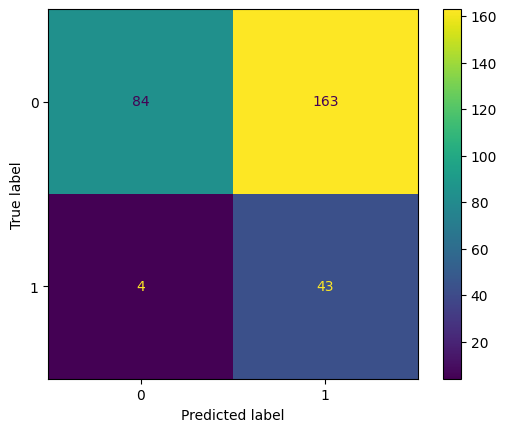

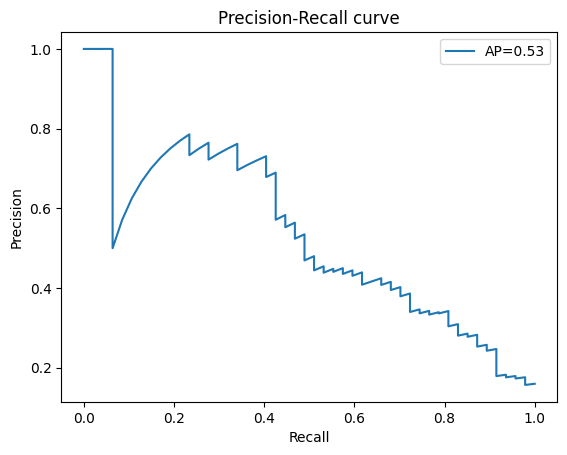

----------------------------------------------
Optimal threshold: 0.9729566573100412
----------------------------------------------


np.float64(0.9729566573100412)

In [83]:
param_grid = {
    # 'model__solver': [ 'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'],
    # 'model__C': [0.1, 1.0, 10,100],
    # 'model__penalty': ['l2','l1'],
    # 'model__class_weight': [{0: 1, 1: 10},'balanced'],
    # 'model__max_iter' : [1000],
    'smote__sampling_strategy': ['auto', 0.5, 0.7],  # Paramètres pour SMOTE
    #'enn__sampling_strategy': ['majority', 0.8]  # Paramètres pour ENN
}

# Instancier la classe avec préprocesseur
handler = ModelHandler(
    model=model, 
    param_grid=param_grid, 
    use_smote=True, 
    use_enn=False, 
    preprocessor=preprocessor
)

handler.build_pipeline(X_train)

handler.train_model(X_train, y_train)

# Effectuer un grid search pour optimiser les hyperparamètres:
# 'precision', 'recall', 'f1': , 'roc_auc', 'fbeta_2', 'fbeta_5'
#handler.grid_search(X_train, y_train,fbeta_2)
handler.evaluate_model(X_test, y_test)
handler.precision_recall_curve(X_test, y_test)

---
#### 11. Pipeline RandomForestClassifier

##### 11.1 Déclaration

In [84]:
# Split train-test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X = df_feat_pipe_clean.drop(columns=['a_quitte_l_entreprise'])
y = df_feat_pipe_clean['a_quitte_l_entreprise']

model = RandomForestClassifier( )


##### 11.2 RandomForestClassifier Stratification

In [85]:
model = RandomForestClassifier()

param_grid = {
    'model__n_estimators': [50, 100, 200],  # Nombre d'arbres
    'model__max_depth': [None, 10, 20, 30],  # Profondeur maximale de chaque arbre
    'model__min_samples_split': [2, 5, 10],  # Nombre minimal d'échantillons pour diviser un noeud
    'model__min_samples_leaf': [1, 2, 4],  # Nombre minimal d'échantillons pour une feuille
    'model__max_features': ['auto', 'sqrt', 'log2'],  # Stratégies de recherche des meilleures fonctionnalités
    'model__bootstrap': [True, False]  # Utilisation de bootstrap pour l'échantillonnage
}

# Instancier la classe avec préprocesseur
handler_r = ModelHandler(
    model=model, 
    param_grid=param_grid, 
    use_smote=False, 
    use_enn=False, 
    preprocessor=preprocessor
)

handler_r.build_pipeline(X_train)

metric_train = handler_r.train_model(X_train, y_train)
print(metric_train)

{'precision': np.float64(0.8249180520614594), 'recall': np.float64(0.5865215068127171), 'f1': np.float64(0.604390999148512), 'roc_auc': np.float64(0.8124306786810127), 'fbeta_2': np.float64(0.21466601741335137), 'fbeta_5': np.float64(0.18935653623908485)}


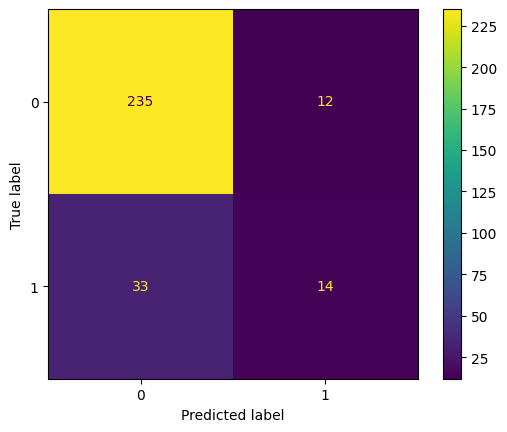

{'precision': 0.7076636050516647, 'recall': 0.6246446722370574, 'f1': 0.6480915015294587, 'roc_auc': 0.716556120251529, 'fbeta_2': 0.32710280373831774, 'fbeta_5': 0.30308076602830974}


In [217]:
metric_test = handler_r.evaluate_model(X_test, y_test)
print(metric_test)

##### 11.3 RandomForestClassifier GridSearch

h:\python_project\projet04_bis\.venv\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
3240 fits failed out of a total of 9720.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1589 fits failed with the following error:
Traceback (most recent call last):
  File "h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~

----------------------------------------------
Best hyperparameters found: {'model__bootstrap': False, 'model__class_weight': {0: 1, 1: 10}, 'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4, 'model__min_samples_split': 10, 'model__n_estimators': 200}
----------------------------------------------


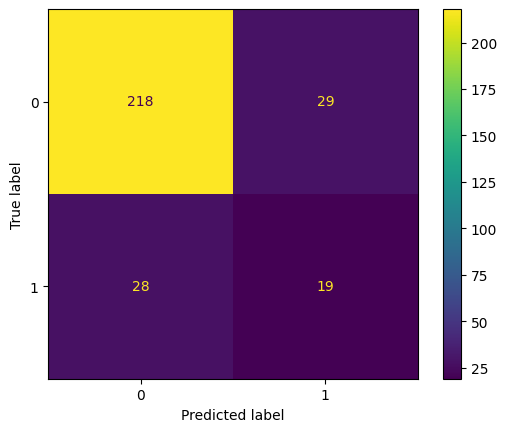

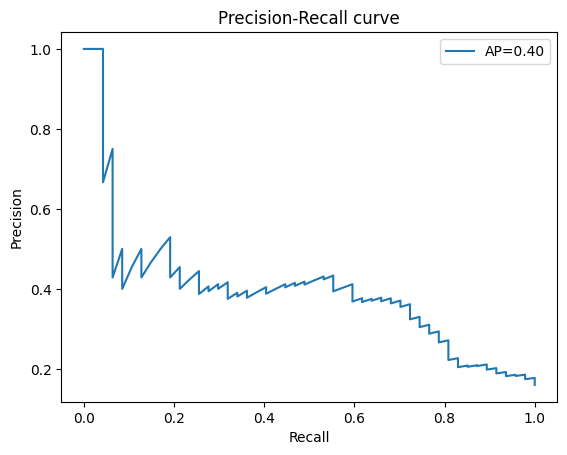

----------------------------------------------
Optimal threshold: 0.44723587524978237
----------------------------------------------


np.float64(0.44723587524978237)

In [86]:

param_grid = {
    'model__n_estimators': [50, 100, 200],  # Nombre d'arbres
    'model__max_depth': [None, 10, 20, 30],  # Profondeur maximale de chaque arbre
    'model__min_samples_split': [2, 5, 10],  # Nombre minimal d'échantillons pour diviser un noeud
    'model__min_samples_leaf': [1, 2, 4],  # Nombre minimal d'échantillons pour une feuille
    'model__max_features': ['auto', 'sqrt', 'log2'],  # Stratégies de recherche des meilleures fonctionnalités
    'model__bootstrap': [True, False],  # Utilisation de bootstrap pour l'échantillonnage
    'model__class_weight':['balanced','balanced_subsample',{0: 1, 1: 10}],
    #'smote__sampling_strategy': ['auto', 0.5, 0.7],  # Paramètres pour SMOTE
    #'enn__sampling_strategy': ['majority', 0.8]  # Paramètres pour ENN
}

# Instancier la classe avec préprocesseur
handler_r = ModelHandler(
    model=model, 
    param_grid=param_grid, 
    use_smote=False, 
    use_enn=False, 
    preprocessor=preprocessor
)

handler_r.build_pipeline(X_train)

fbeta_2 = make_scorer(fbeta_score, beta=2)

# Effectuer un grid search pour optimiser les hyperparamètres:
# 'precision', 'recall', 'f1': , 'roc_auc', 'fbeta_2', 'fbeta_5'
handler_r.grid_search(X_train, y_train,fbeta_2)
handler_r.evaluate_model(X_test, y_test)
handler_r.precision_recall_curve(X_test, y_test)


- Best hyperparameters found: {    
    'model__bootstrap': False,     
    'model__class_weight': {0: 1, 1: 10},     
    'model__max_depth': 10,     
    'model__max_features': 'sqrt',     
    'model__min_samples_leaf': 4,     
    'model__min_samples_split': 10,     
    'model__n_estimators': 200    
    }



h:\python_project\projet04_bis\.venv\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
3240 fits failed out of a total of 9720.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1906 fits failed with the following error:
Traceback (most recent call last):
  File "h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~

----------------------------------------------
Best hyperparameters found: {'model__bootstrap': False, 'model__class_weight': {0: 1, 1: 10}, 'model__max_depth': 10, 'model__max_features': 'log2', 'model__min_samples_leaf': 4, 'model__min_samples_split': 2, 'model__n_estimators': 200}
----------------------------------------------


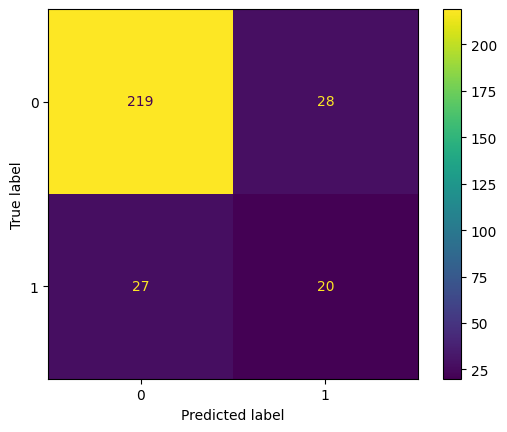

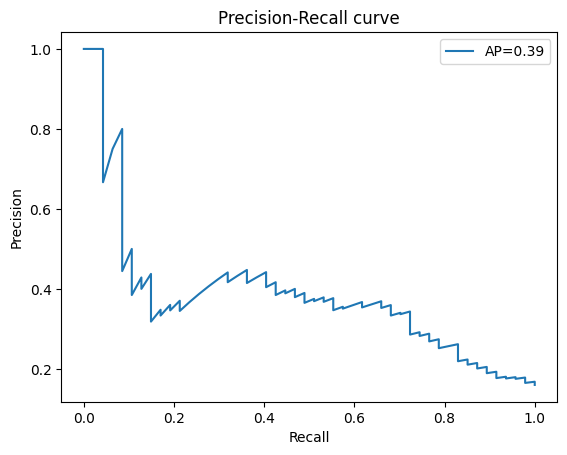

----------------------------------------------
Optimal threshold: 0.39421111064960973
----------------------------------------------


np.float64(0.39421111064960973)

In [87]:
handler_r.build_pipeline(X_train)


fbeta_5 = make_scorer(fbeta_score, beta=5)

# Effectuer un grid search pour optimiser les hyperparamètres:
# 'precision', 'recall', 'f1': , 'roc_auc', 'fbeta_2', 'fbeta_5'
handler_r.grid_search(X_train, y_train,fbeta_5)
handler_r.evaluate_model(X_test, y_test)
handler_r.precision_recall_curve(X_test, y_test)

- Best hyperparameters found: {    
    'model__bootstrap': False,     
    'model__class_weight': {0: 1, 1: 10},     
    'model__max_depth': 10,      
    'model__max_features': 'log2',     
    'model__min_samples_leaf': 4,     
    'model__min_samples_split': 2,     
    'model__n_estimators': 200    
    }



##### 11.4 RandomForestClassifier Optimisée

In [88]:
model = RandomForestClassifier( 
    #fbeta=2
    bootstrap=False,
    class_weight= {0: 1, 1: 10}, 
    max_depth=10, 
    max_features='sqrt',
    min_samples_leaf=4, 
    min_samples_split=10, 
    n_estimators=200,
         
)

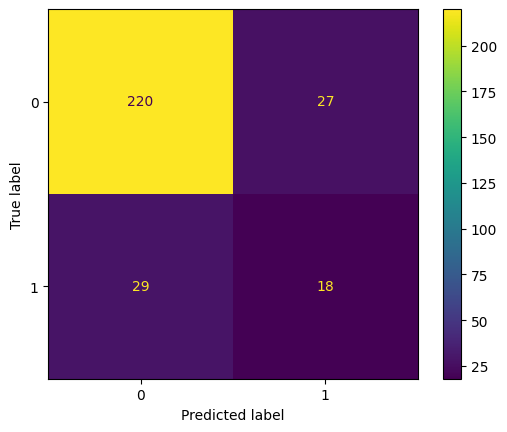

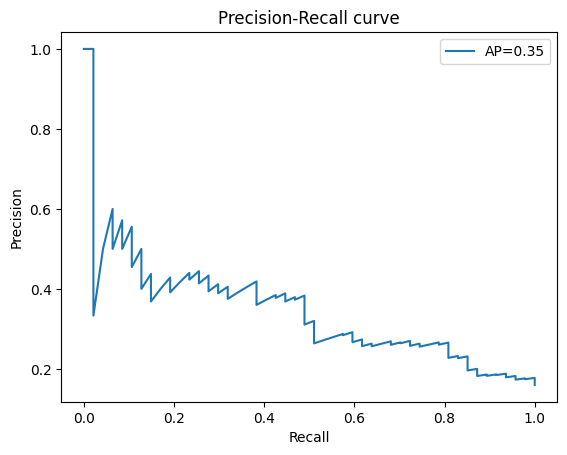

----------------------------------------------
Optimal threshold: 0.462113842458581
----------------------------------------------


np.float64(0.462113842458581)

In [89]:
param_grid = {
    # 'model__n_estimators': [50, 100, 200],  
    # 'model__max_depth': [None, 10, 20, 30],  
    # 'model__min_samples_split': [2, 5, 10],  
    # 'model__min_samples_leaf': [1, 2, 4],  
    # 'model__max_features': ['auto', 'sqrt', 'log2'],  
    # 'model__bootstrap': [True, False]  
    #'smote__sampling_strategy': ['auto', 0.5, 0.7],  # Paramètres pour SMOTE
    #'enn__sampling_strategy': ['majority', 0.8]  # Paramètres pour ENN
}

# Instancier la classe avec préprocesseur
handler_r = ModelHandler(
    model=model, 
    param_grid=param_grid, 
    use_smote=False, 
    use_enn=False, 
    preprocessor=preprocessor
)

handler_r.build_pipeline(X_train)

handler_r.train_model(X_train, y_train)

# Effectuer un grid search pour optimiser les hyperparamètres:
# 'precision', 'recall', 'f1': , 'roc_auc', 'fbeta_2', 'fbeta_5'
#handler.grid_search(X_train, y_train,fbeta_2)
handler_r.evaluate_model(X_test, y_test)
handler_r.precision_recall_curve(X_test, y_test)

##### 11.5 RandomForestClassifier Optimisée + SMOTE

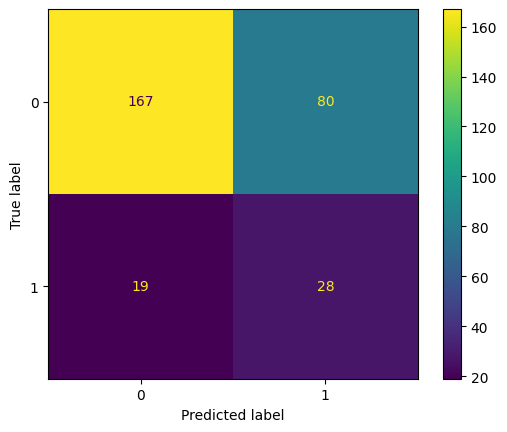

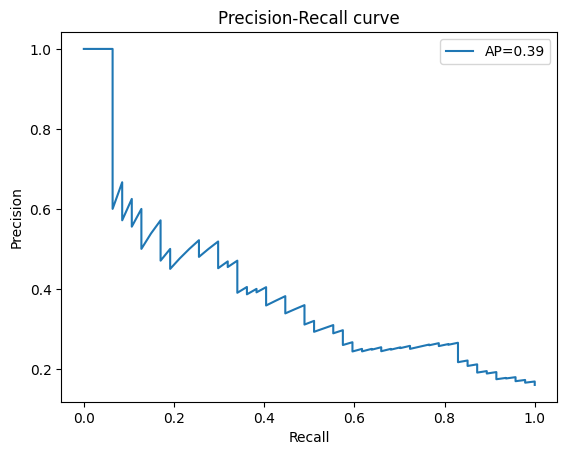

----------------------------------------------
Optimal threshold: 0.616451368956853
----------------------------------------------


np.float64(0.616451368956853)

In [90]:
param_grid = {
    'smote__sampling_strategy': ['auto', 0.5, 0.7],  # Paramètres pour SMOTE
    #'enn__sampling_strategy': ['majority', 0.8]  # Paramètres pour ENN
}

# Instancier la classe avec préprocesseur
handler_r = ModelHandler(
    model=model, 
    param_grid=param_grid, 
    use_smote=True, 
    use_enn=False, 
    preprocessor=preprocessor
)

handler_r.build_pipeline(X_train)

handler_r.train_model(X_train, y_train)

# Effectuer un grid search pour optimiser les hyperparamètres:
# 'precision', 'recall', 'f1': , 'roc_auc', 'fbeta_2', 'fbeta_5'
#handler.grid_search(X_train, y_train,fbeta_2)
handler_r.evaluate_model(X_test, y_test)
handler_r.precision_recall_curve(X_test, y_test)

---
#### 12. Features Importances

h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
h:\python_project\projet04_bis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

[-0.00238095  0.00340136 -0.0207483  -0.00272109 -0.00680272 -0.01836735
 -0.00510204 -0.00918367  0.01122449 -0.00170068  0.00102041 -0.00340136
  0.         -0.0122449  -0.00068027  0.00340136 -0.01326531 -0.01496599
 -0.00510204  0.00136054  0.00238095  0.00238095 -0.00986395 -0.00102041
  0.00782313 -0.00136054]


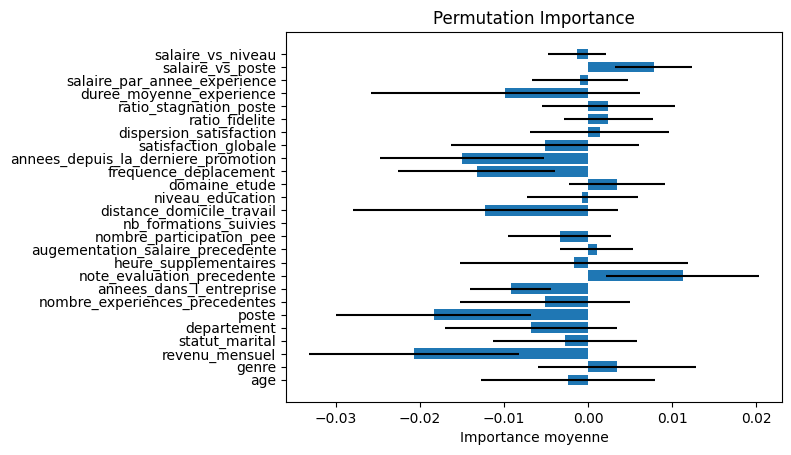

In [26]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

model = LogisticRegression(
    #fbeta=2     
    C=0.1,     
    class_weight={0: 1, 1: 10},     
    max_iter=1000,     
    penalty='l2',     
    solver='newton-cg'   
)
param_grid = {
    'smote__sampling_strategy': ['auto', 0.5, 0.7],  # Paramètres pour SMOTE
    #'enn__sampling_strategy': ['majority', 0.8]  # Paramètres pour ENN
}
handler = ModelHandler(
    model=model, 
    param_grid=param_grid, 
    use_smote=True, 
    use_enn=False, 
    preprocessor=preprocessor
)

handler.build_pipeline(X_train)
handler.train_model(X_train, y_train)

# Calcul de la permutation importance
result = permutation_importance(handler.pipeline, X_test, y_test, n_repeats=10, random_state=42)

# Affichage des importances
importances = result.importances_mean
std_importances = result.importances_std
print(importances)
# Tracer les résultats
plt.barh(X_train.columns, importances, xerr=std_importances)
plt.xlabel("Importance moyenne")
plt.title("Permutation Importance")
plt.show()

Récupération des Coefficients

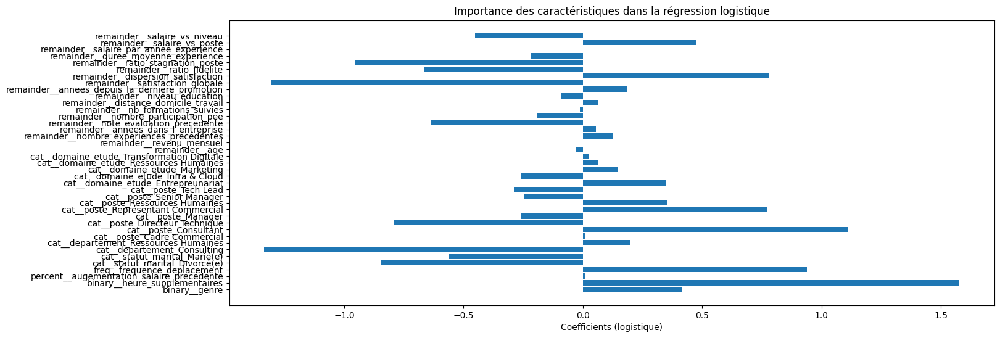

In [12]:
# Accéder au modèle dans le pipeline pour obtenir les coefficients

coefficients = handler.pipeline.named_steps['model'].coef_[0]  # Pour une classification binaire
features = preprocessor.get_feature_names_out()

# Tracer les coefficients
plt.figure(figsize=(16, 6))
plt.barh(features, coefficients)
plt.xlabel("Coefficients (logistique)")
plt.title("Importance des caractéristiques dans la régression logistique")
plt.show()

In [89]:
handler.pipeline.named_steps['model'].intercept_
print("coef:",len(handler.pipeline.named_steps['model'].coef_[0]))
print("X.columns",len(preprocessor.get_feature_names_out()))

coef: 39
X.columns 39


In [28]:
import numpy as np
import shap

print(f"NumPy Version: {np.__version__}")
print(f"SHAP Version: {shap.__version__}")

NumPy Version: 1.26.4
SHAP Version: 0.49.1


h:\python_project\projet04_bis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [150]:
X_train.dtypes

age                                      int64
genre                                   object
revenu_mensuel                           int64
statut_marital                          object
departement                             object
poste                                   object
nombre_experiences_precedentes           int64
annees_dans_l_entreprise                 int64
note_evaluation_precedente               int64
heure_supplementaires                   object
augementation_salaire_precedente        object
nombre_participation_pee                 int64
nb_formations_suivies                    int64
distance_domicile_travail                int64
niveau_education                         int64
domaine_etude                           object
frequence_deplacement                   object
annees_depuis_la_derniere_promotion      int64
satisfaction_globale                   float64
dispersion_satisfaction                float64
ratio_fidelite                         float64
ratio_stagnat

---
#### 13. Calcul et Visualisation des Shapley Values avec SHAP

---
###### test

In [37]:
# Récupérer le modèle à partir du pipeline
model = handler.pipeline.named_steps['model']  
preprocessor = handler.pipeline.named_steps['prep']

# Création du KernelExplainer pour une régression logistique
explainer = shap.KernelExplainer(model.predict_proba, preprocessor.transform(X_train))

# Calcul des valeurs SHAP pour l'ensemble des données d'entraînement
shap_values = explainer.shap_values( preprocessor.transform(X_train))



Using 1176 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  1%|          | 14/1176 [00:42<58:57,  3.04s/it]


KeyboardInterrupt: 

In [ ]:
shap.plots.beeswarm(shap_values, max_display=20)

NameError: name 'shap_values1' is not defined

In [41]:
import pickle

# Enregistrer les valeurs SHAP dans un fichier binaire
with open('./shap_values.pkl', 'wb') as f:
    pickle.dump(shap_values, f)

In [48]:
# Lire les valeurs SHAP depuis un fichier binaire
with open('./shap_values.pkl', 'rb') as f:
    loaded_shap_values = pickle.load(f)

# Vérifier que les données sont chargées
print(loaded_shap_values)

[[[ 0.0262371  -0.0262371 ]
  [ 0.06623609 -0.06623609]
  [ 0.          0.        ]
  ...
  [ 0.          0.        ]
  [ 0.          0.        ]
  [ 0.          0.        ]]

 [[ 0.          0.        ]
  [ 0.05320352 -0.05320352]
  [ 0.          0.        ]
  ...
  [ 0.          0.        ]
  [ 0.          0.        ]
  [ 0.          0.        ]]

 [[ 0.          0.        ]
  [ 0.06202183 -0.06202183]
  [ 0.          0.        ]
  ...
  [ 0.          0.        ]
  [ 0.          0.        ]
  [ 0.          0.        ]]

 ...

 [[ 0.          0.        ]
  [ 0.03852744 -0.03852744]
  [ 0.          0.        ]
  ...
  [ 0.          0.        ]
  [ 0.          0.        ]
  [ 0.          0.        ]]

 [[ 0.          0.        ]
  [-0.18441204  0.18441204]
  [ 0.          0.        ]
  ...
  [ 0.          0.        ]
  [-0.07798369  0.07798369]
  [ 0.          0.        ]]

 [[ 0.          0.        ]
  [ 0.06127706 -0.06127706]
  [ 0.          0.        ]
  ...
  [ 0.          0.      

In [14]:
# compute SHAP values
explainer1 = shap.Explainer(model, preprocessor.transform(X))
shap_values1 = explainer1(preprocessor.transform(X))
print(explainer1)
print(shap_values1)

.values =
array([[-0.22460429481702557, 1.1525029875899382, -0.04810780516819103,
        ..., 0.09164652960237124, -0.055069240578907185,
        -0.02713336934835057],
       [0.1913295844737625, -0.42626822828668953, 0.0782146591684156,
        ..., -0.1266021628728722, 0.2854614616293396,
        0.04365864414541796],
       [0.1913295844737625, 1.1525029875899382, -0.006000317055988818,
        ..., -0.3509636528528961, -0.1593760428135418,
        0.1259890401736691],
       ...,
       [0.1913295844737625, 1.1525029875899382, 0.04663404308426394, ...,
        0.32303708561768363, -0.06625261220872426, -0.0393558606699861],
       [0.1913295844737625, -0.42626822828668953, -0.01652718908403937,
        ..., -0.3091850436076162, -0.09638069430217648,
        0.022330806939879395],
       [0.1913295844737625, -0.42626822828668953, -0.03758093314014048,
        ..., 0.051452252032366814, 0.17972224447631024,
        0.10321252803472963]], dtype=object)

.base_values =
array([1.13920

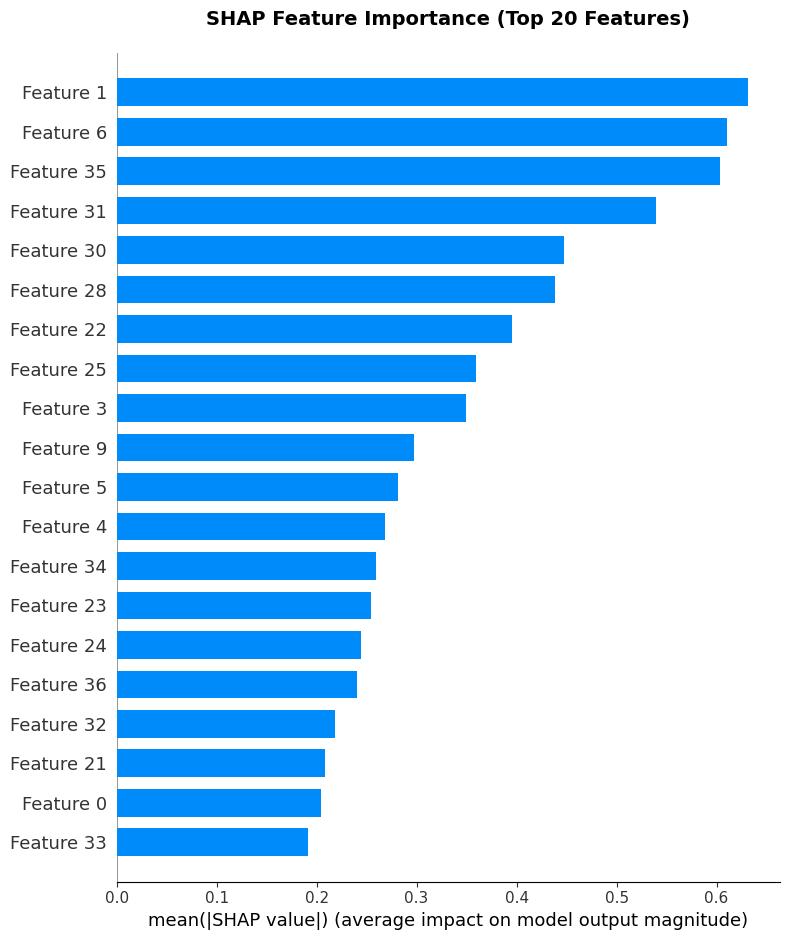

In [15]:
# SHAP Feature Importance - Bar Plot (Working Alternative)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values1, preprocessor.transform(X), plot_type="bar", max_display=20, show=False)
plt.title('SHAP Feature Importance (Top 20 Features)', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

TypeError: loop of ufunc does not support argument 0 of type float which has no callable rint method

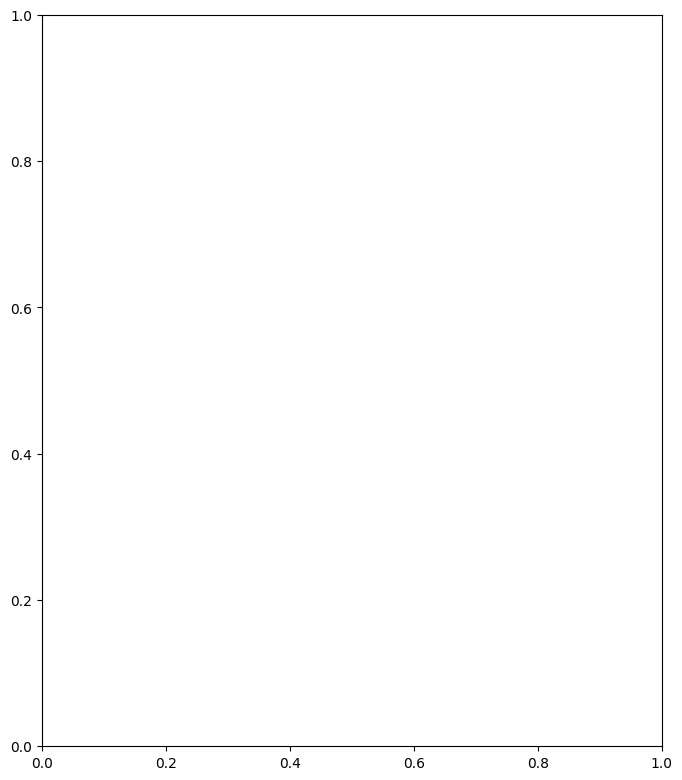

In [19]:
# Test beeswarm avec vos données existantes
shap.plots.beeswarm(shap_values1, max_display=20)
plt.show()

IndexError: index 1412 is out of bounds for axis 0 with size 1176

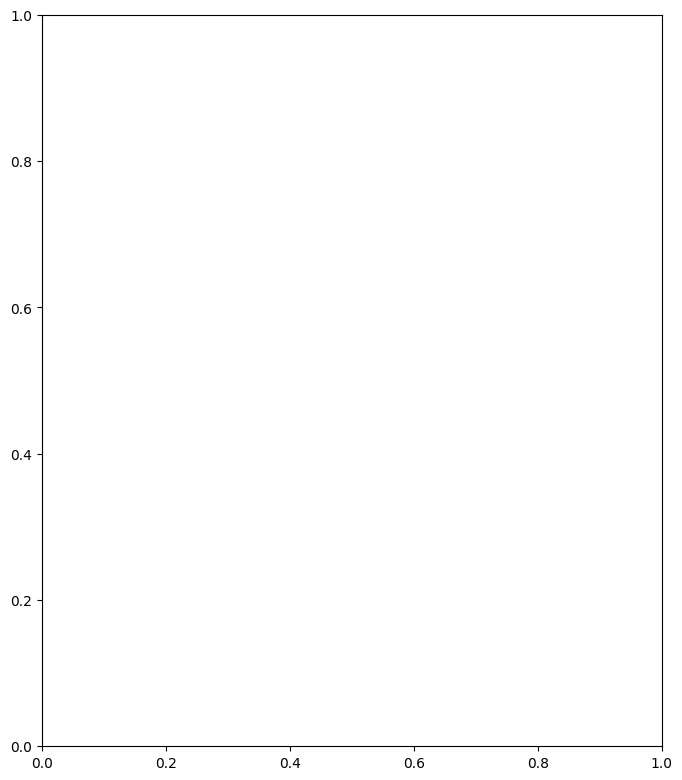

In [24]:
plt.figure(figsize=(10, 10))
shap.summary_plot(shap_values1, preprocessor.transform(X_train), show=False)
plt.figure(figsize=(12, 8))
plt.tight_layout()

plt.show()




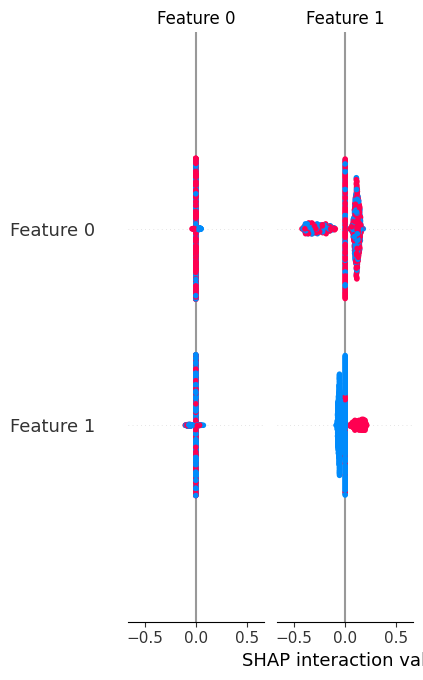

In [48]:
shap.summary_plot(shap_values, preprocessor.transform(X_train), show=False)

---
##### 

In [32]:
feature_names = preprocessor.get_feature_names_out()
len(feature_names)
print(feature_names)

['binary__genre' 'binary__heure_supplementaires'
 'percent__augementation_salaire_precedente' 'freq__frequence_deplacement'
 'cat__statut_marital_Divorcé(e)' 'cat__statut_marital_Marié(e)'
 'cat__departement_Consulting' 'cat__departement_Ressources Humaines'
 'cat__poste_Cadre Commercial' 'cat__poste_Consultant'
 'cat__poste_Directeur Technique' 'cat__poste_Manager'
 'cat__poste_Représentant Commercial' 'cat__poste_Ressources Humaines'
 'cat__poste_Senior Manager' 'cat__poste_Tech Lead'
 'cat__domaine_etude_Entrepreunariat' 'cat__domaine_etude_Infra & Cloud'
 'cat__domaine_etude_Marketing' 'cat__domaine_etude_Ressources Humaines'
 'cat__domaine_etude_Transformation Digitale' 'remainder__age'
 'remainder__revenu_mensuel' 'remainder__nombre_experiences_precedentes'
 'remainder__annees_dans_l_entreprise'
 'remainder__note_evaluation_precedente'
 'remainder__nombre_participation_pee' 'remainder__nb_formations_suivies'
 'remainder__distance_domicile_travail' 'remainder__niveau_education'
 '

##### Beeswarm

NumPy version: 1.26.4
SHAP version: 0.49.1
X_train_transformed shape: (1176, 39)
X_test_transformed shape: (294, 39)
Shape SHAP values: (294, 39)


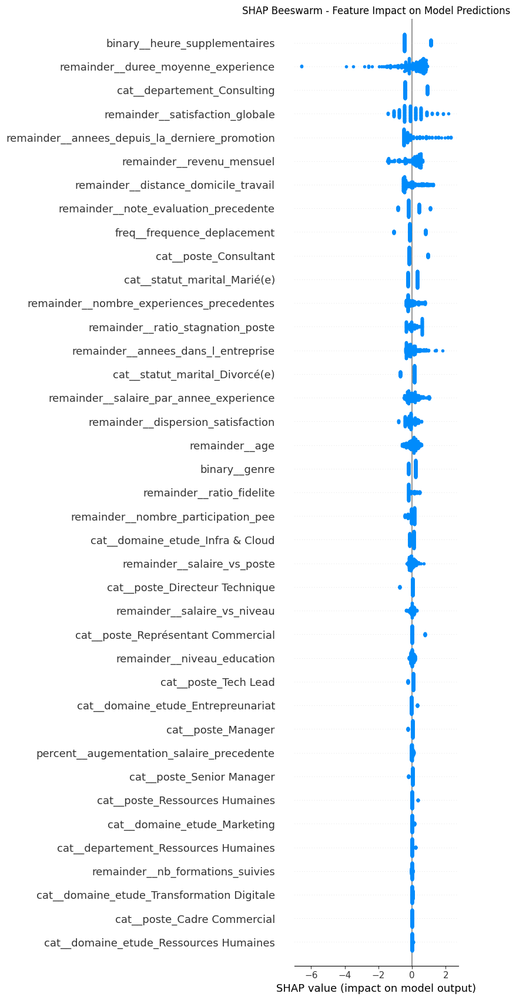

In [33]:
import shap


print(f"NumPy version: {np.__version__}")
print(f"SHAP version: {shap.__version__}")

# Transformer les données avec le preprocessor
X_train_transformed = preprocessor.transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print(f"X_train_transformed shape: {X_train_transformed.shape}")
print(f"X_test_transformed shape: {X_test_transformed.shape}")

# Recalculer les SHAP values avec les données transformées
explainer_new = shap.LinearExplainer(model, X_train_transformed)
shap_values_new = explainer_new.shap_values(X_test_transformed)

# Convertir en numpy array propre
shap_vals_array = np.asarray(shap_values_new, dtype=np.float64)

print(f"Shape SHAP values: {shap_vals_array.shape}")

# Créer l'Explanation correctement
shap_explanation = shap.Explanation(
    values=shap_vals_array,
    base_values=np.mean(shap_vals_array),
    feature_names=feature_names
)

# Afficher le beeswarm
plt.figure(figsize=(14, 8))
shap.plots.beeswarm(shap_explanation, max_display=100, show=False)
plt.title('SHAP Beeswarm - Feature Impact on Model Predictions')
plt.tight_layout()
plt.show()


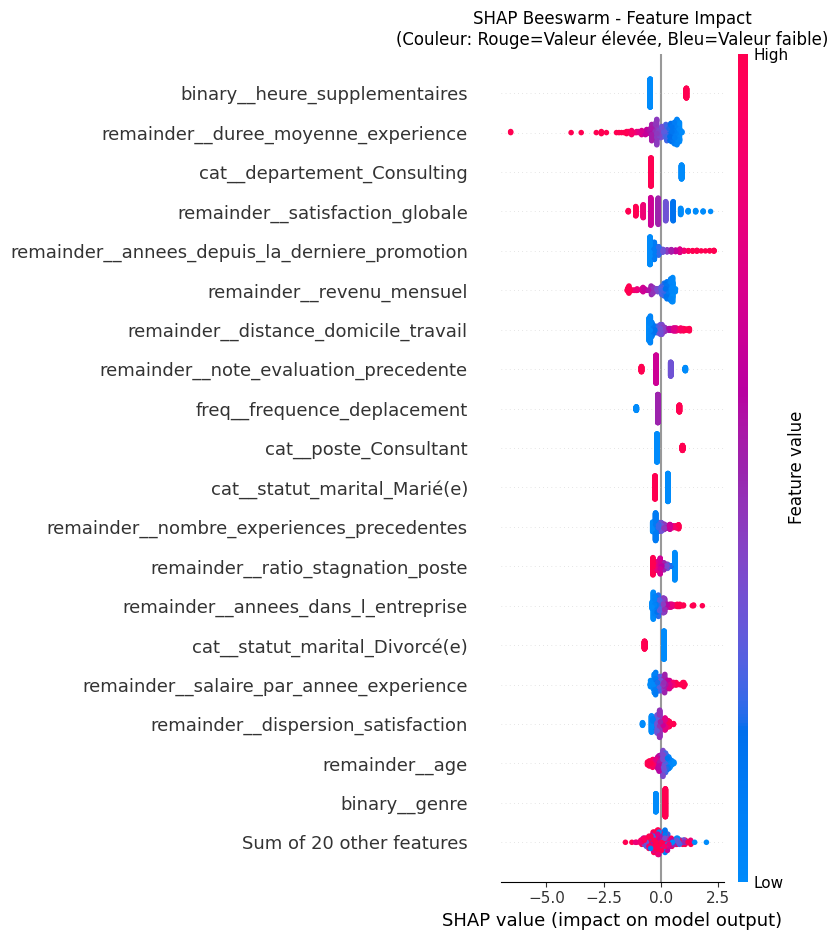

In [34]:
# Transformer les données avec le preprocessor
X_train_transformed = preprocessor.transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# Recalculer les SHAP values
explainer_new = shap.LinearExplainer(model, X_train_transformed)
shap_values_new = explainer_new.shap_values(X_test_transformed)

# Convertir en numpy array propre
shap_vals_array = np.asarray(shap_values_new, dtype=np.float64)

# Créer l'Explanation avec les données
shap_explanation = shap.Explanation(
    values=shap_vals_array,
    base_values=np.mean(shap_vals_array),
    data=X_test_transformed,
    feature_names=feature_names
)

# Afficher le beeswarm (couleurs = valeurs des features)
plt.figure(figsize=(14, 8))
shap.plots.beeswarm(shap_explanation, max_display=20, show=False)
plt.title('SHAP Beeswarm - Feature Impact\n(Couleur: Rouge=Valeur élevée, Bleu=Valeur faible)')
plt.tight_layout()
plt.show()

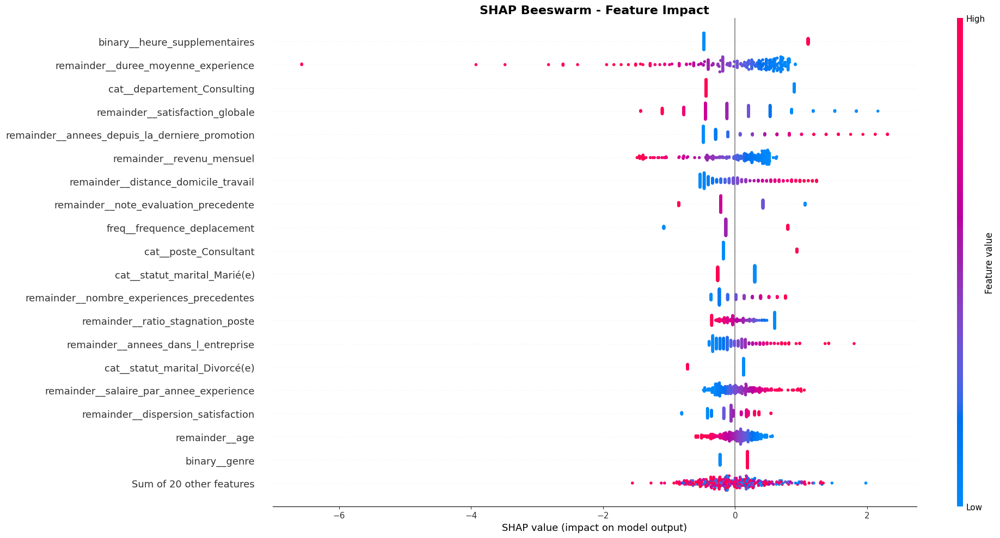

In [35]:
# Transformer les données avec le preprocessor
X_train_transformed = preprocessor.transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# Recalculer les SHAP values
explainer_new = shap.LinearExplainer(model, X_train_transformed)
shap_values_new = explainer_new.shap_values(X_test_transformed)

# Convertir en numpy array propre
shap_vals_array = np.asarray(shap_values_new, dtype=np.float64)

# Créer l'Explanation avec les données
shap_explanation = shap.Explanation(
    values=shap_vals_array,
    base_values=np.mean(shap_vals_array),
    data=X_test_transformed,
    feature_names=feature_names
)

# Afficher le beeswarm avec zone graphique PLUS LARGE
plt.figure(figsize=(20, 10))
shap.plots.beeswarm(
    shap_explanation, 
    max_display=20,
    plot_size=(20, 10),  # Contrôle la largeur de la zone de plot
    show=False
)
plt.title('SHAP Beeswarm - Feature Impact', 
          fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

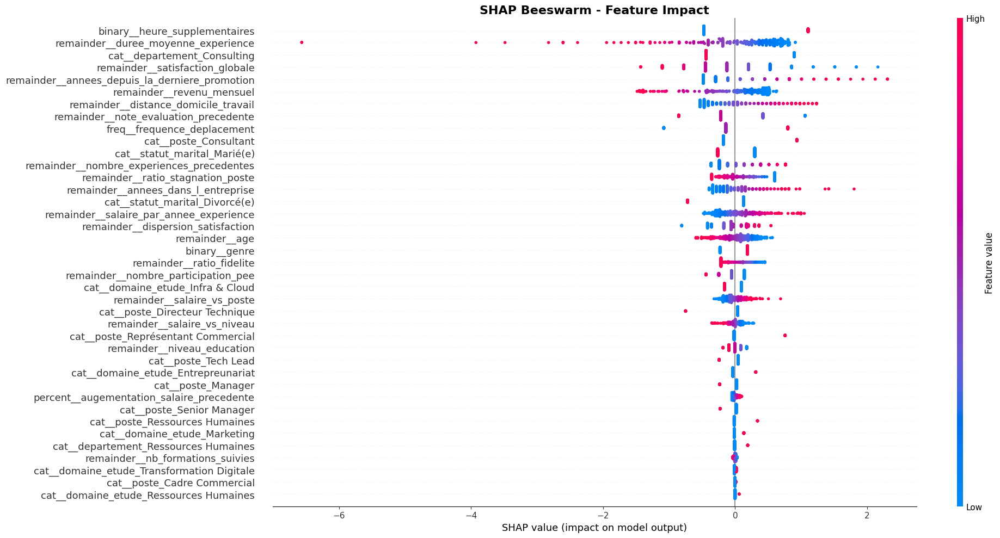

In [47]:
# Afficher le beeswarm avec zone graphique PLUS LARGE
plt.figure(figsize=(20, 10))
shap.plots.beeswarm(
    shap_explanation, 
    max_display=39,
    plot_size=(20, 10),  # Contrôle la largeur de la zone de plot
    show=False
)
plt.title('SHAP Beeswarm - Feature Impact', 
          fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

##### Waterfall

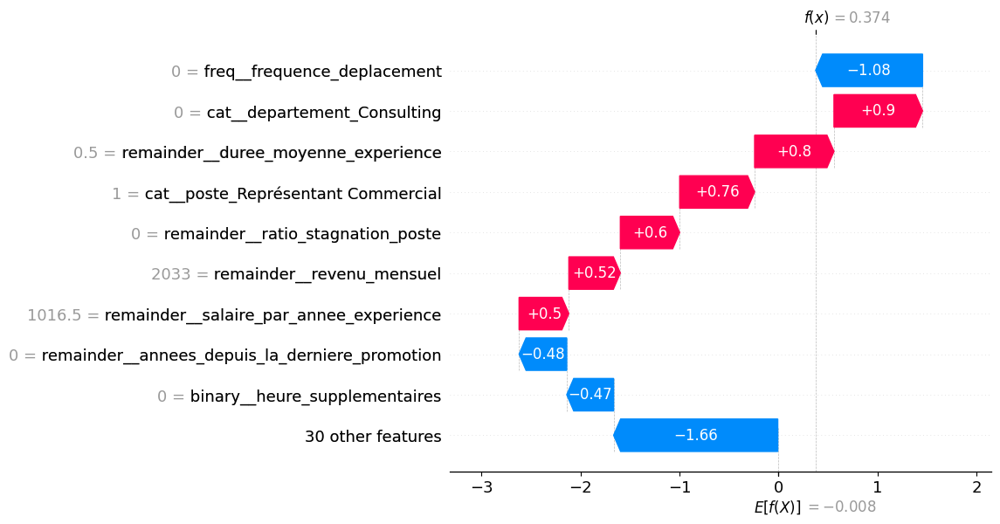

In [ ]:
# Utilisation de l'explainer déjà créé
shap.plots.waterfall(shap_explanation[0])  # Premier employé

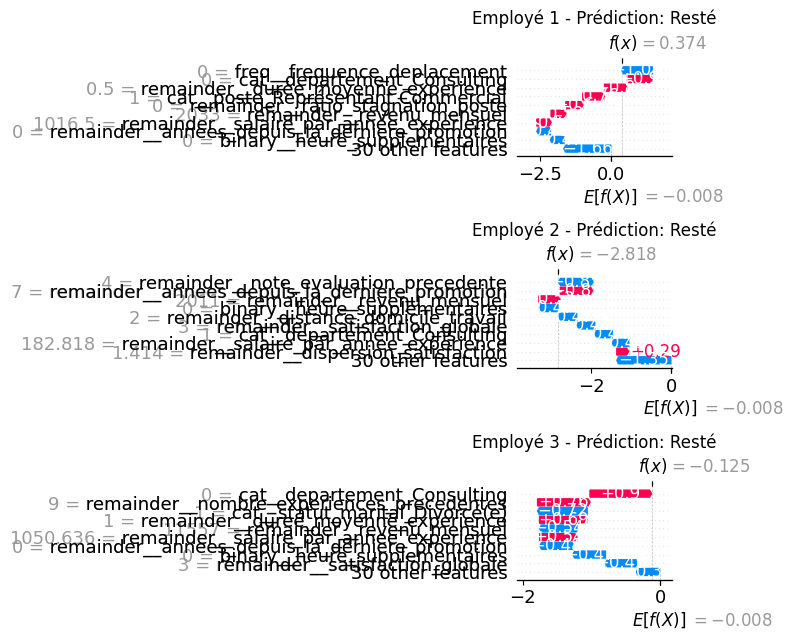

In [44]:
fig, axes = plt.subplots(3, 1, figsize=(15, 30))

for i in range(3):
    plt.sca(axes[i])
    shap.plots.waterfall(shap_explanation[i], show=False)
    axes[i].set_title(f"Employé {i+1} - Prédiction: {'A quitté' if y_test.iloc[i] == 1 else 'Resté'}")

plt.tight_layout()
plt.show()

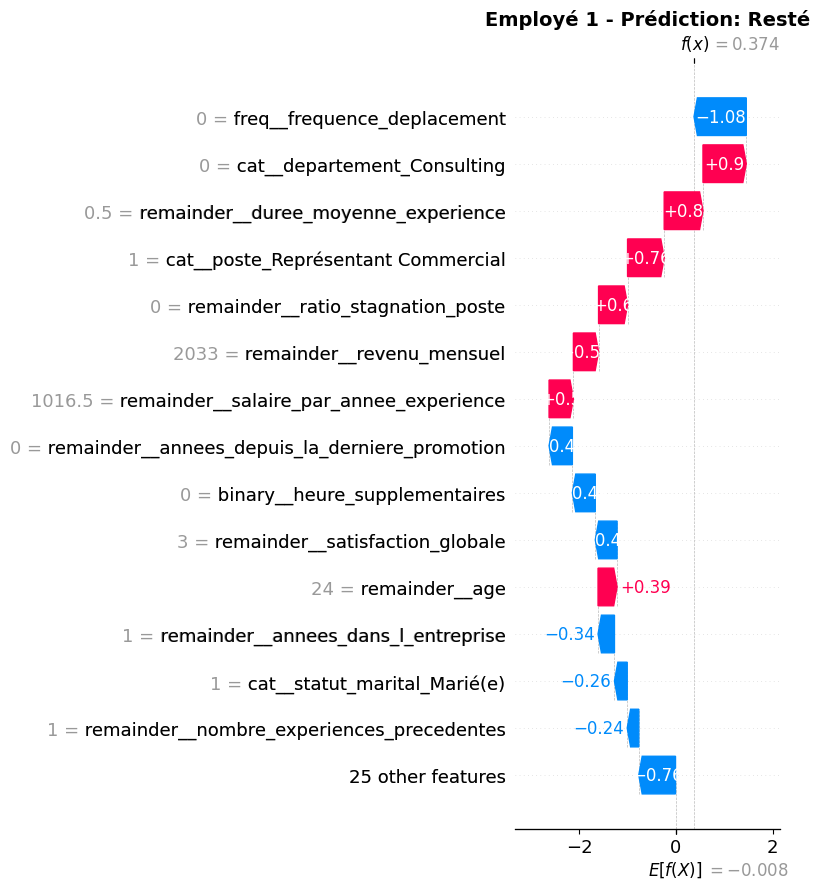

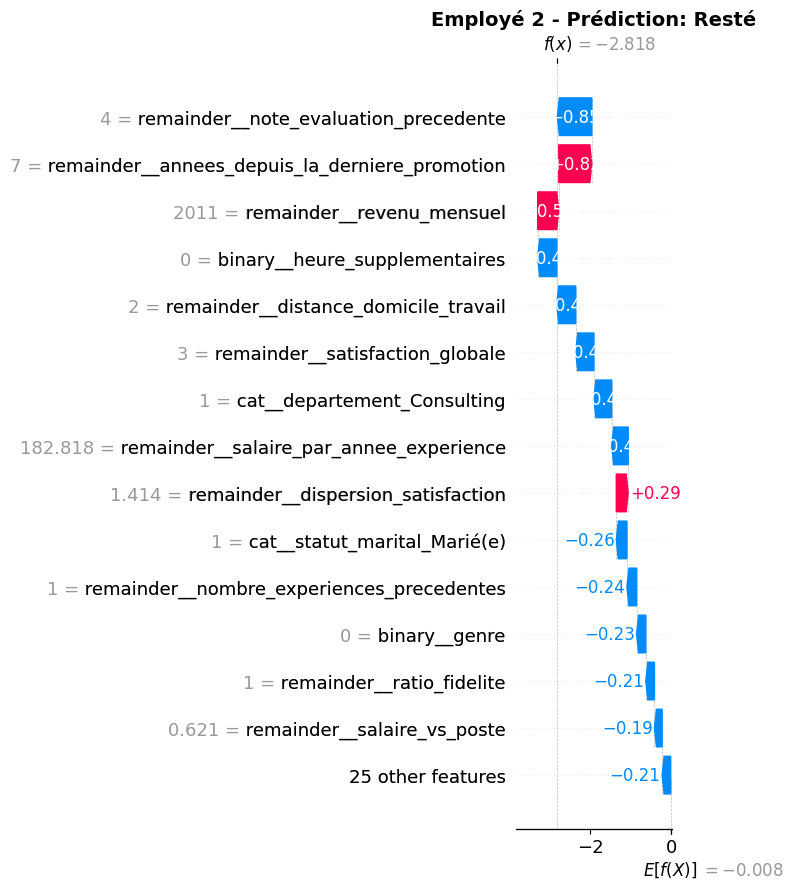

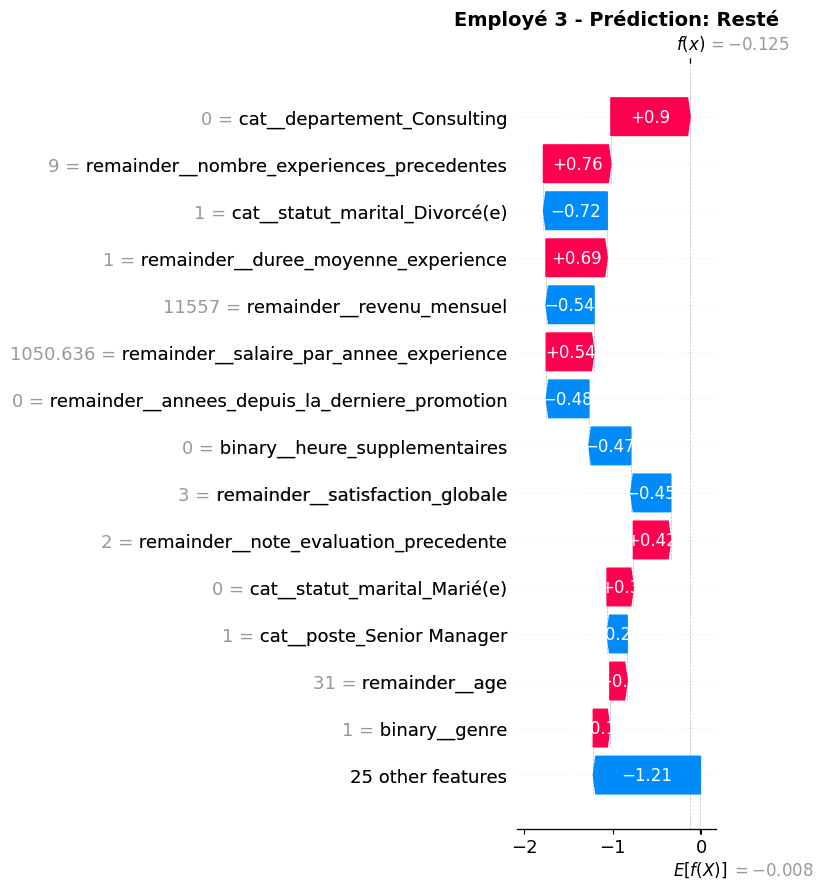

In [36]:
# Afficher les waterfall séparément (meilleure lisibilité)
import matplotlib.pyplot as plt

for i in range(3):
    plt.figure(figsize=(10, 8))  # Chaque waterfall a sa propre figure
    shap.plots.waterfall(shap_explanation[i], max_display=15, show=False)
    plt.title(
        f"Employé {i+1} - Prédiction: {'A quitté' if y_test.iloc[i] == 1 else 'Resté'}", 
        fontsize=14, 
        fontweight='bold'
    )
    plt.tight_layout()
    plt.show()
    print(f"\n{'='*60}\n")  # Séparateur visuel

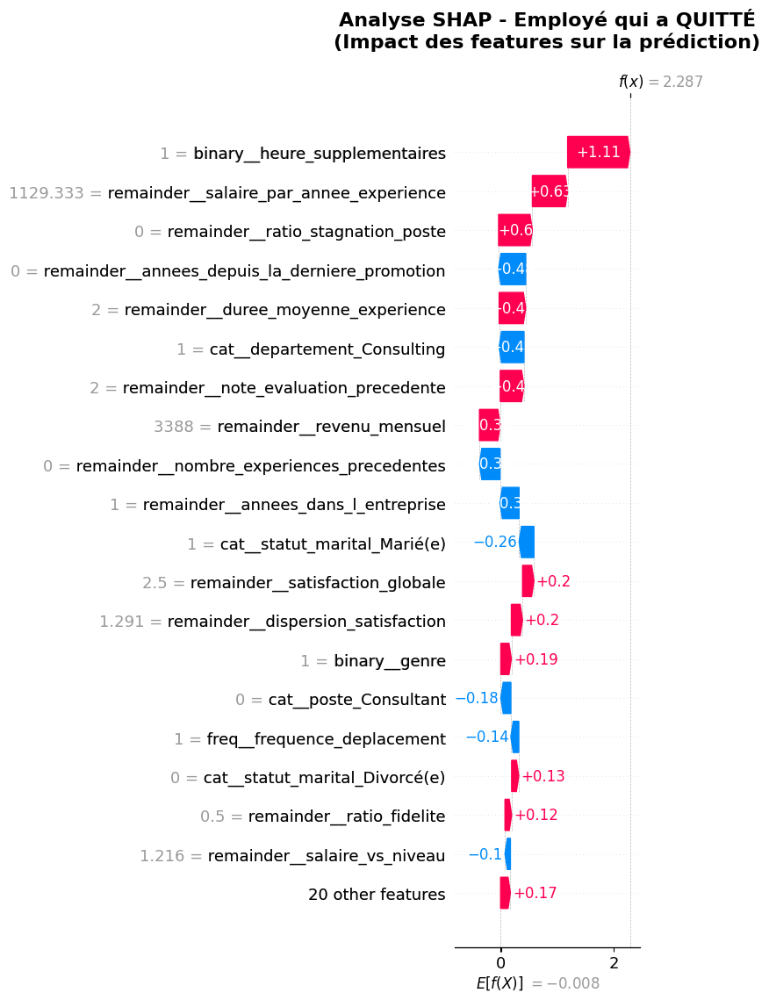

In [ ]:
# Choisir un employé intéressant (par exemple le premier qui a quitté)
idx_quitte = y_test[y_test == 1].index[0] if (y_test == 1).any() else 0
idx_position = y_test.index.get_loc(idx_quitte)

plt.figure(figsize=(14, 10))
shap.plots.waterfall(shap_explanation[idx_position], max_display=20, show=False)
plt.title(
    f"Analyse SHAP - Employé qui a QUITTÉ\n(Impact des features sur la prédiction)", 
    fontsize=16, 
    fontweight='bold',
    pad=20
)
plt.tight_layout()
plt.show()

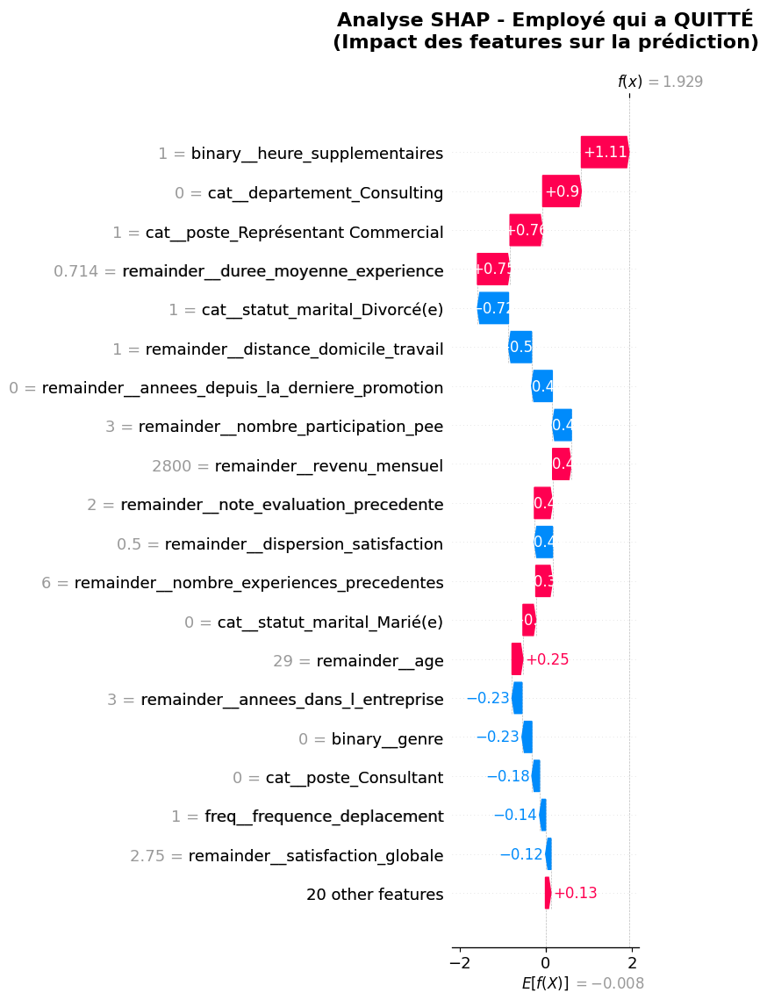

In [ ]:
# Choisir un employé intéressant (par exemple le premier qui a quitté)
idx_quitte = y_test[y_test == 1].index[1] if (y_test == 1).any() else 0
idx_position = y_test.index.get_loc(idx_quitte)

plt.figure(figsize=(14, 10))
shap.plots.waterfall(shap_explanation[idx_position], max_display=20, show=False)
plt.title(
    f"Analyse SHAP - Employé qui a QUITTÉ\n(Impact des features sur la prédiction)", 
    fontsize=16, 
    fontweight='bold',
    pad=20
)
plt.tight_layout()
plt.show()

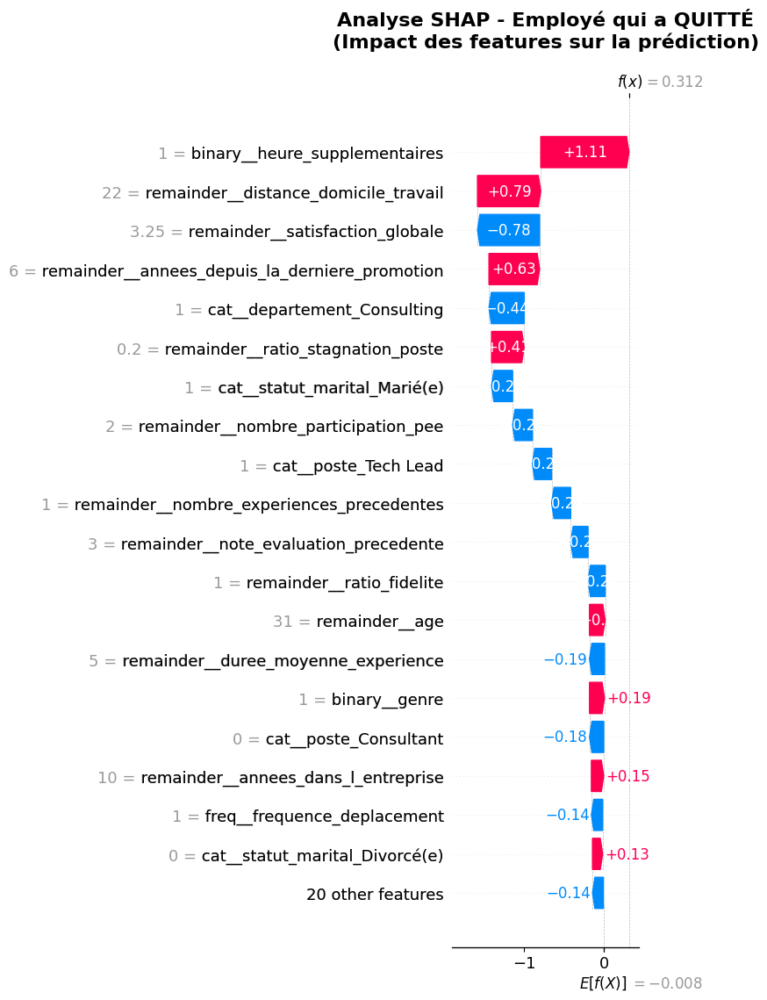

In [76]:
idx_quitte = y_test[y_test == 1].index[2] if (y_test == 1).any() else 0
idx_position = y_test.index.get_loc(idx_quitte)

plt.figure(figsize=(14, 10))
shap.plots.waterfall(shap_explanation[idx_position], max_display=20, show=False)
plt.title(
    f"Analyse SHAP - Employé qui a QUITTÉ\n(Impact des features sur la prédiction)", 
    fontsize=16, 
    fontweight='bold',
    pad=20
)
plt.tight_layout()
plt.show()

In [75]:
idx_quitte = y_test[y_test == 1]if (y_test == 1).any() else 0
len(idx_quitte)

47

##### Scatter

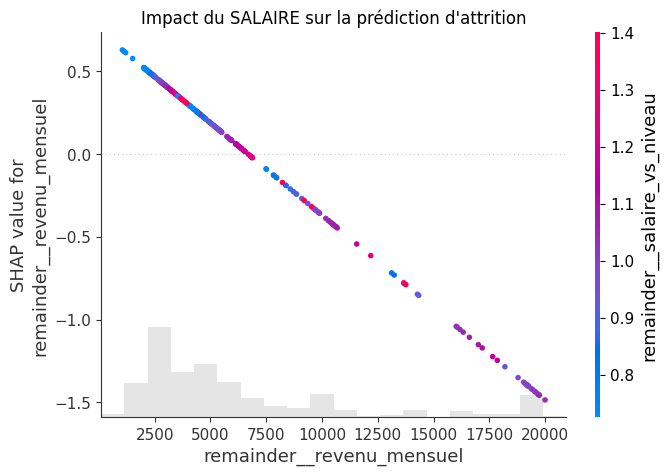

In [54]:
# Voir comment le salaire influence la décision de quitter
shap.plots.scatter(
    shap_explanation[:, 'remainder__revenu_mensuel'],show=False, 
    color=shap_explanation
)
plt.title("Impact du SALAIRE sur la prédiction d'attrition")
plt.show()


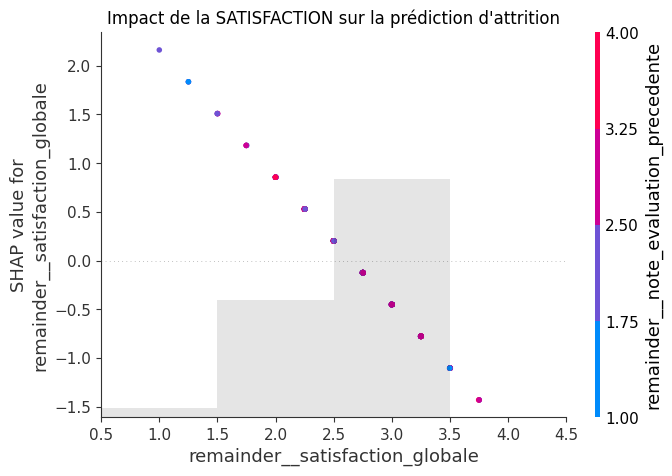

In [56]:
# Feature la PLUS importante généralement
shap.plots.scatter(
    shap_explanation[:, "remainder__satisfaction_globale"],show=False,
    color=shap_explanation
)
plt.title("Impact de la SATISFACTION sur la prédiction d'attrition")
plt.show()

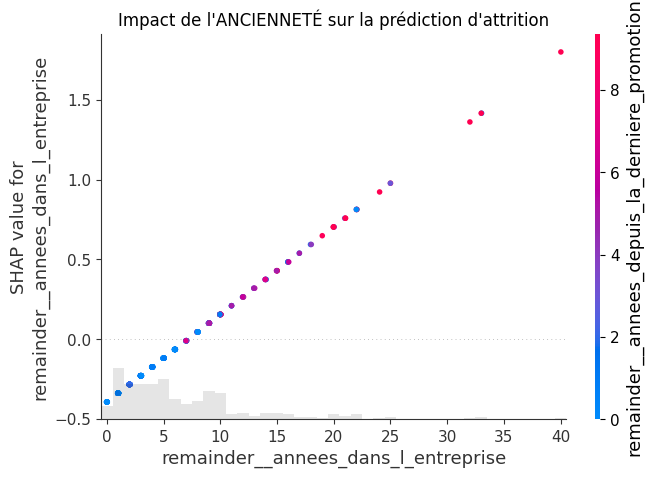

In [58]:
# Analyser l'effet de l'ancienneté
shap.plots.scatter(
    shap_explanation[:, "remainder__annees_dans_l_entreprise"],show=False,
    color=shap_explanation
)
plt.title("Impact de l'ANCIENNETÉ sur la prédiction d'attrition")
plt.show()

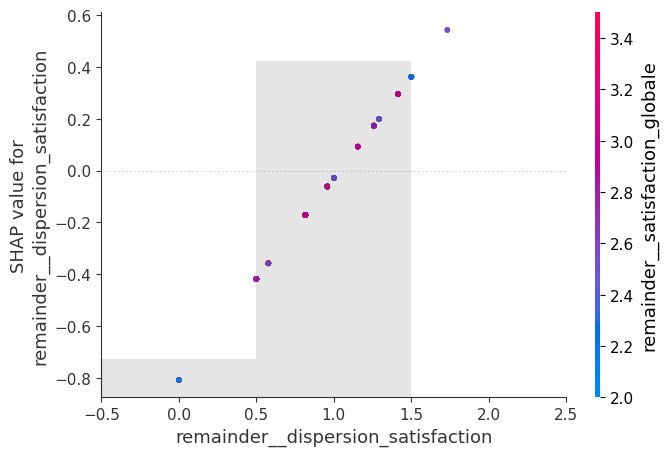

In [60]:
# Voir si l'effet 
shap.plots.scatter(
    shap_explanation[:, "remainder__dispersion_satisfaction"],
    color=shap_explanation[:, "remainder__satisfaction_globale"]
)
plt.show()

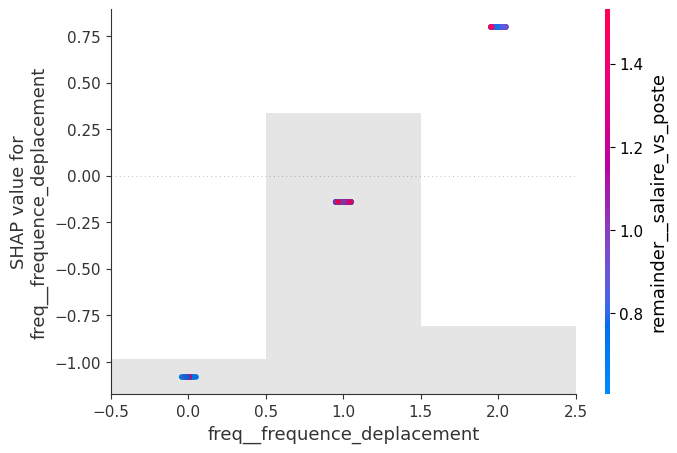

In [61]:
# Analyser la charge de travail
shap.plots.scatter(
    shap_explanation[:, "freq__frequence_deplacement"],
    color=shap_explanation
)
plt.show()

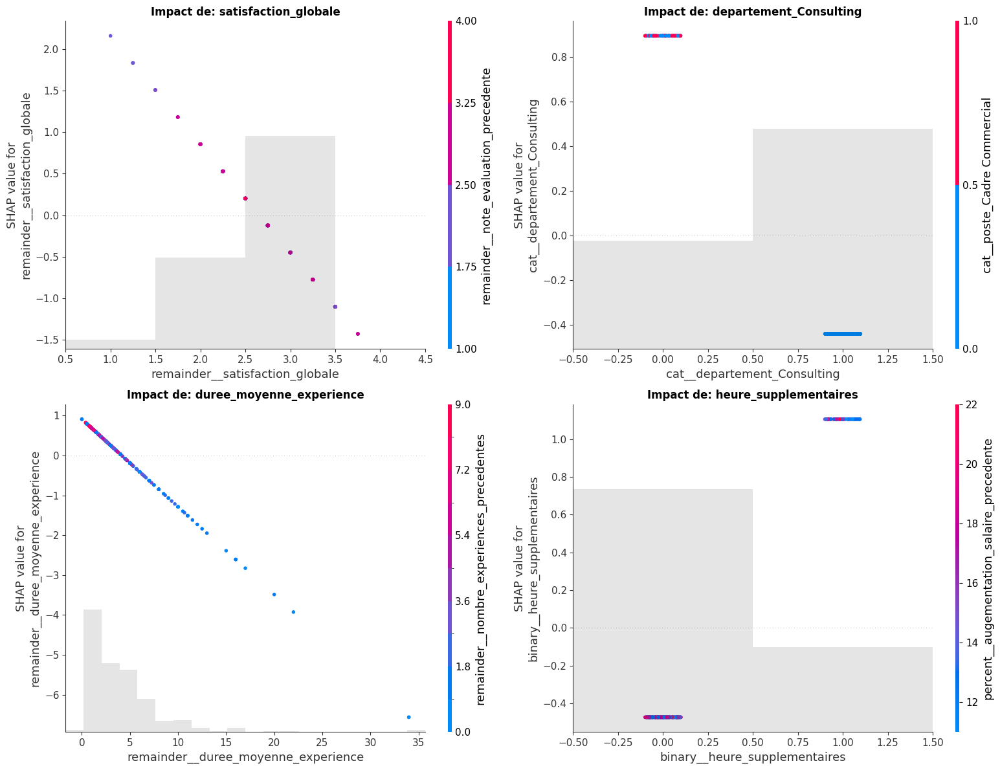

In [42]:
# Afficher les 4 features les plus importantes
import matplotlib.pyplot as plt

# Récupérer les 4 features avec le plus d'impact moyen
feature_importance = np.abs(shap_vals_array).mean(axis=0)
top_4_idx = np.argsort(feature_importance)[-4:]
top_4_features = feature_names[top_4_idx]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, feat in enumerate(top_4_features):
    plt.sca(axes[i])
    shap.plots.scatter(
        shap_explanation[:, feat],
        color=shap_explanation,
        show=False,
        ax=axes[i]
    )
    axes[i].set_title(f"Impact de: {feat.split('__')[-1]}", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

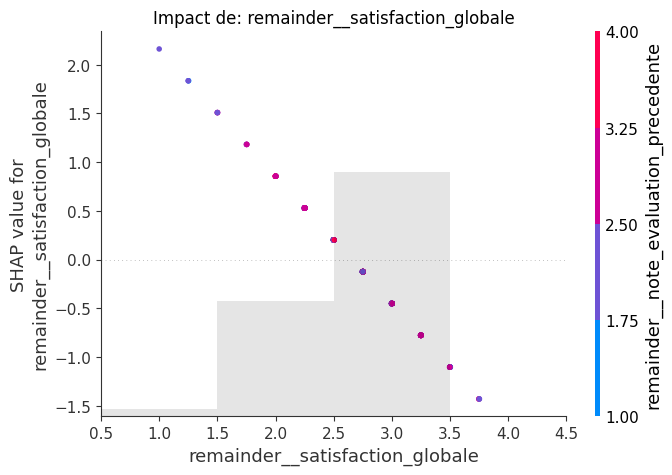

In [72]:
# Fonction helper pour trouver l'index d'une feature
def get_feature_idx(feature_name_partial):
    """Trouve l'index d'une feature par son nom (partiel)"""
    for i, name in enumerate(feature_names):
        if feature_name_partial.lower() in name.lower():
            return i
    return None

# Exemple : Satisfaction globale
idx_satisfaction = get_feature_idx("satisfaction_globale")
if idx_satisfaction is not None:
    shap.plots.scatter(
        shap_explanation[:, idx_satisfaction],show=False,
        color=shap_explanation
    )
    plt.title(f"Impact de: {feature_names[idx_satisfaction]}")
    plt.show()

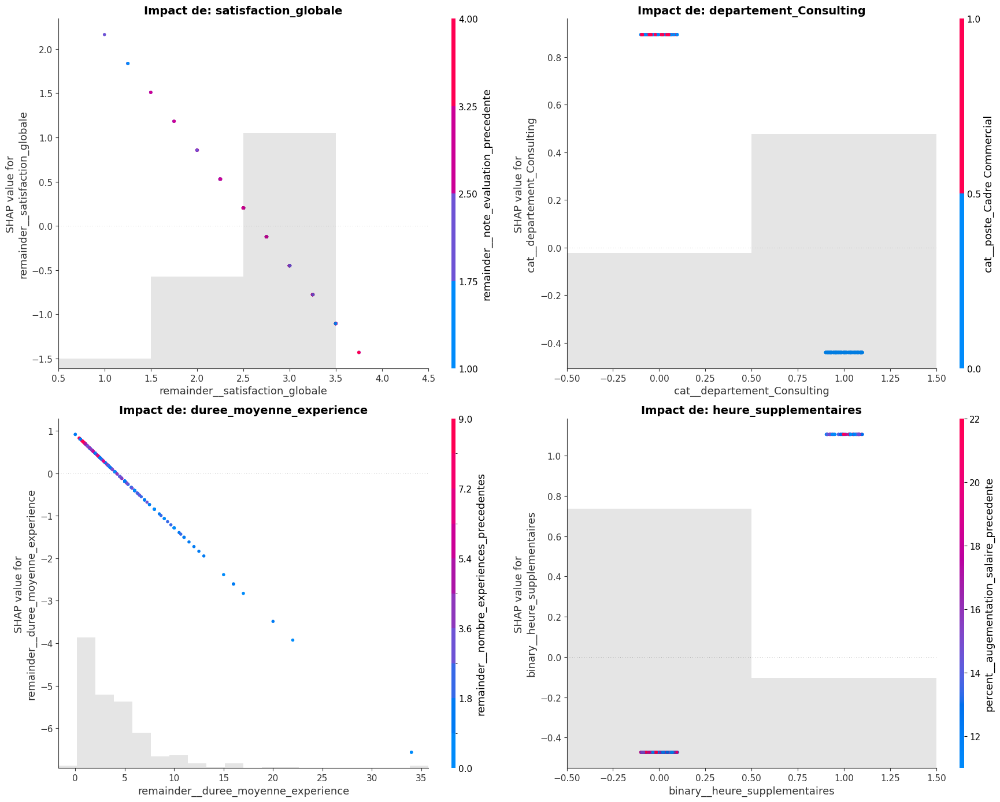

Top 4 features analysées:
  - remainder__satisfaction_globale
  - cat__departement_Consulting
  - remainder__duree_moyenne_experience
  - binary__heure_supplementaires


In [44]:
import matplotlib.pyplot as plt
import numpy as np

# Récupérer les 4 features avec le plus d'impact moyen
feature_importance = np.abs(shap_vals_array).mean(axis=0)
top_4_idx = np.argsort(feature_importance)[-4:]

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

for i, feat_idx in enumerate(top_4_idx):
    plt.sca(axes[i])
    shap.plots.scatter(
        shap_explanation[:, feat_idx],
        color=shap_explanation,
        show=False,
        ax=axes[i]
    )
    # Nom plus court pour le titre
    feat_name = feature_names[feat_idx].split('__')[-1]
    axes[i].set_title(f"Impact de: {feat_name}", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("Top 4 features analysées:")
for idx in top_4_idx:
    print(f"  - {feature_names[idx]}")

Features disponibles (50 premières):
  0: binary__genre
  1: binary__heure_supplementaires
  2: percent__augementation_salaire_precedente
  3: freq__frequence_deplacement
  4: cat__statut_marital_Divorcé(e)
  5: cat__statut_marital_Marié(e)
  6: cat__departement_Consulting
  7: cat__departement_Ressources Humaines
  8: cat__poste_Cadre Commercial
  9: cat__poste_Consultant
 10: cat__poste_Directeur Technique
 11: cat__poste_Manager
 12: cat__poste_Représentant Commercial
 13: cat__poste_Ressources Humaines
 14: cat__poste_Senior Manager
 15: cat__poste_Tech Lead
 16: cat__domaine_etude_Entrepreunariat
 17: cat__domaine_etude_Infra & Cloud
 18: cat__domaine_etude_Marketing
 19: cat__domaine_etude_Ressources Humaines
 20: cat__domaine_etude_Transformation Digitale
 21: remainder__age
 22: remainder__revenu_mensuel
 23: remainder__nombre_experiences_precedentes
 24: remainder__annees_dans_l_entreprise
 25: remainder__note_evaluation_precedente
 26: remainder__nombre_participation_pee
 27:

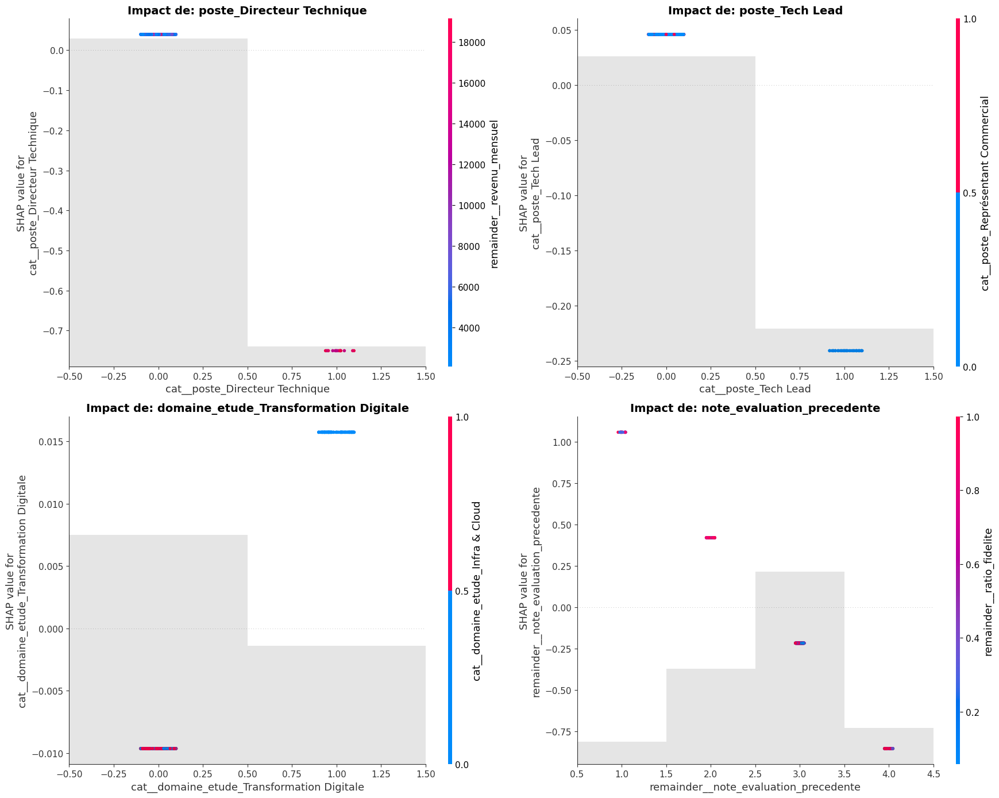

In [ ]:
# Liste les features disponibles
print("Features disponibles (50 premières):")
for i, name in enumerate(feature_names[:50]):
    print(f"{i:3d}: {name}")

# Choisir manuellement les indices qui t'intéressent

indices_interessants = [10, 15, 20, 25]  # À adapter selon tes features

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

for i, feat_idx in enumerate(indices_interessants):
    if feat_idx < len(feature_names):
        plt.sca(axes[i])
        shap.plots.scatter(
            shap_explanation[:, feat_idx],
            color=shap_explanation,
            show=False,
            ax=axes[i]
        )
        feat_name = feature_names[feat_idx].split('__')[-1]
        axes[i].set_title(f"Impact de: {feat_name}", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

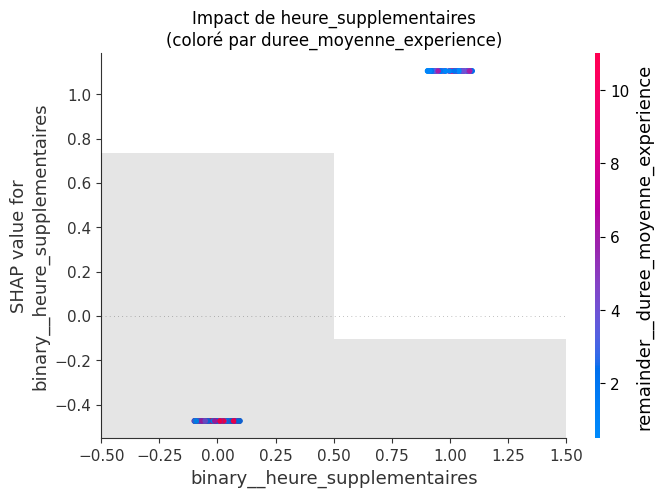

In [62]:
# Trouver les 2 features les plus importantes
feature_importance = np.abs(shap_vals_array).mean(axis=0)
top_2_idx = np.argsort(feature_importance)[-2:]

idx_feat1 = top_2_idx[1]  # Plus importante
idx_feat2 = top_2_idx[0]  # 2ème plus importante

# Scatter avec interaction
shap.plots.scatter(
    shap_explanation[:, idx_feat1],
    color=shap_explanation[:, idx_feat2],show=False,
)
plt.title(f"Impact de {feature_names[idx_feat1].split('__')[-1]}\n(coloré par {feature_names[idx_feat2].split('__')[-1]})")
plt.show()

##### Autre

In [74]:
# Récupérer les 4 features avec le plus d'impact moyen
feature_importance = np.abs(shap_vals_array).mean(axis=0)
top_idx = np.argsort(-feature_importance)

for i, feat_idx in enumerate(top_idx):
    # Nom plus court pour le titre
    feat_name = feature_names[feat_idx]
    print(f"{feat_name.split('__')[-1]}",",i:",i,",idx",feat_idx,",value:", top_idx[feat_idx])

heure_supplementaires ,i: 0 ,idx 1 ,value: 35
duree_moyenne_experience ,i: 1 ,idx 35 ,value: 27
departement_Consulting ,i: 2 ,idx 6 ,value: 28
satisfaction_globale ,i: 3 ,idx 31 ,value: 14
annees_depuis_la_derniere_promotion ,i: 4 ,idx 30 ,value: 2
revenu_mensuel ,i: 5 ,idx 22 ,value: 37
distance_domicile_travail ,i: 6 ,idx 28 ,value: 16
note_evaluation_precedente ,i: 7 ,idx 25 ,value: 12
frequence_deplacement ,i: 8 ,idx 3 ,value: 31
poste_Consultant ,i: 9 ,idx 9 ,value: 9
statut_marital_Marié(e) ,i: 10 ,idx 5 ,value: 22
nombre_experiences_precedentes ,i: 11 ,idx 23 ,value: 10
ratio_stagnation_poste ,i: 12 ,idx 34 ,value: 7
annees_dans_l_entreprise ,i: 13 ,idx 24 ,value: 38
statut_marital_Divorcé(e) ,i: 14 ,idx 4 ,value: 30
salaire_par_annee_experience ,i: 15 ,idx 36 ,value: 20
dispersion_satisfaction ,i: 16 ,idx 32 ,value: 13
age ,i: 17 ,idx 21 ,value: 17
genre ,i: 18 ,idx 0 ,value: 1
ratio_fidelite ,i: 19 ,idx 33 ,value: 18
nombre_participation_pee ,i: 20 ,idx 26 ,value: 29
domaine_e